In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
file_path="../Data/Raw_data/FIRMS/district_daily_paddy.csv.gz"


<div style="background-color:#172554; padding:18px; border-radius:10px; color:white;">
  <h2 style="color:#60A5FA;">🔥 01 — FIRMS Dataset Audit</h2>
  <p><b style="color:#FBBF24;">Objective:</b> Understand the structure and quality of our satellite fire-detection dataset before preprocessing.</p>
  <hr>
  <p><b style="color:#86EFAC;">What we will investigate:</b></p>
  <ul>
    <li>Dataset dimensions and column names</li>
    <li>Data types and missing values</li>
    <li>Date range and geographical coverage</li>
    <li>Satellite sensor distribution</li>
    <li>Duplicate records and unique identifiers</li>
  </ul>
  <p style="color:#FCA5A5;"><b>Important:</b> A missing district-date record does not automatically mean zero fires.</p>
</div>


In [4]:
fires=pd.read_csv(file_path)

Filtering dataset geographically based on India 


In [5]:
print("Dataset shape:", fires.shape)
print("\nColumn information:")
fires.info()
print("\nStatistical summary:")
display(fires.describe(include="all"))

Dataset shape: (427728, 8)

Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 427728 entries, 0 to 427727
Data columns (total 8 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   year          427728 non-null  int64 
 1   sensor_group  427728 non-null  object
 2   date          427728 non-null  object
 3   district_id   427728 non-null  int64 
 4   district      427728 non-null  object
 5   state         427728 non-null  object
 6   country       427728 non-null  object
 7   detections    427728 non-null  int64 
dtypes: int64(3), object(5)
memory usage: 26.1+ MB

Statistical summary:


,year,sensor_group,date,district_id,district,state,country,detections
count,427728.000000,427728,427728,427728.000000,427728,427728,427728,427728.000000
unique,NaN,3,1814,NaN,844,41,2,NaN
top,NaN,viirs,2025-11-16,NaN,Okara,Punjab,India,NaN
freq,NaN,200690,942,NaN,2838,98765,340855,NaN
mean,2018.662538,NaN,NaN,384.337885,NaN,NaN,NaN,10.490316
std,4.905211,NaN,NaN,210.120794,NaN,NaN,NaN,41.015665
min,2003.000000,NaN,NaN,0.000000,NaN,NaN,NaN,1.000000
25%,2015.000000,NaN,NaN,230.000000,NaN,NaN,NaN,1.000000
50%,2019.000000,NaN,NaN,362.000000,NaN,NaN,NaN,2.000000
75%,2023.000000,NaN,NaN,513.000000,NaN,NaN,NaN,5.000000


In [6]:
fires_india = fires[
    (fires["country"] == "India") &
    (fires["state"].isin(["Punjab", "Haryana"]))
].copy()

print("Filtered shape:", fires_india.shape)

print("\nDistricts per state:")
print(fires_india.groupby("state")["district"].nunique())

print("\nRecords per state:")
print(fires_india["state"].value_counts())

Filtered shape: (72410, 8)

Districts per state:
state
Haryana    21
Punjab     22
Name: district, dtype: int64

Records per state:
state
Punjab     46727
Haryana    25683
Name: count, dtype: int64


sensor_group
viirs    26707
snpp     23199
modis    22504
Name: count, dtype: int64


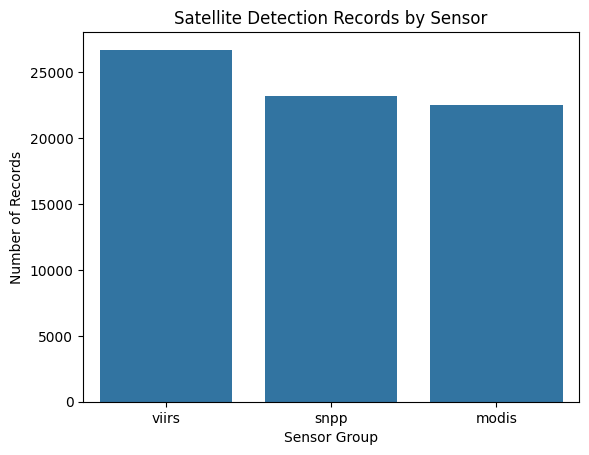

In [7]:
sensor_counts = fires_india["sensor_group"].value_counts()
print(sensor_counts)

sns.barplot(
    x=sensor_counts.index,
    y=sensor_counts.values
)

plt.title("Satellite Detection Records by Sensor")
plt.xlabel("Sensor Group")
plt.ylabel("Number of Records")
plt.show()

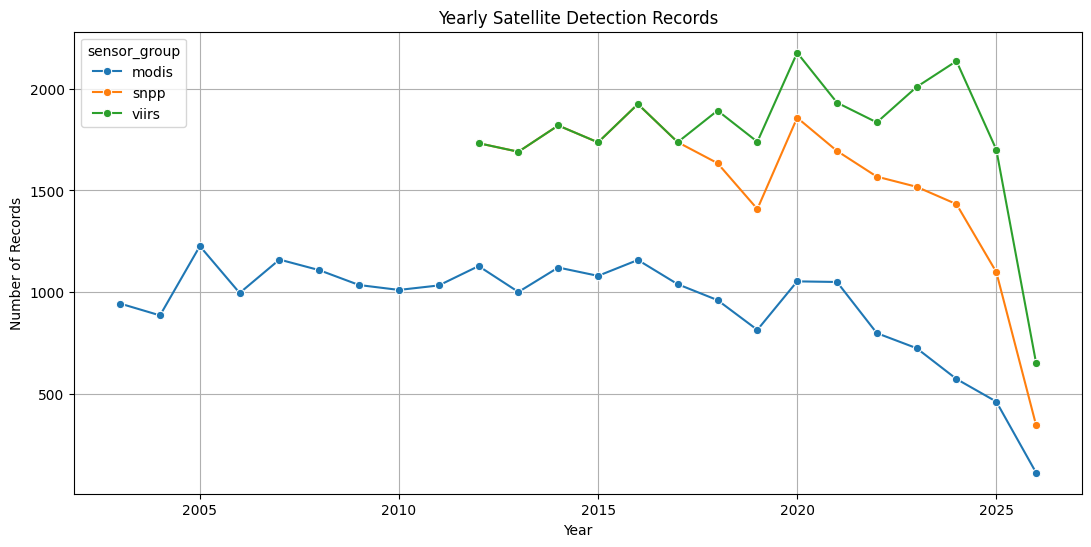

In [8]:
yearly_records = (
    fires_india
    .groupby(["year", "sensor_group"])
    .size()
    .reset_index(name="records")
)

plt.figure(figsize=(13, 6))

sns.lineplot(
    data=yearly_records,
    x="year",
    y="records",
    hue="sensor_group",
    marker="o"
)

plt.title("Yearly Satellite Detection Records")
plt.xlabel("Year")
plt.ylabel("Number of Records")
plt.grid(True)
plt.show()


<div style="background-color:#172554; padding:16px; border-radius:10px; color:white;">
  <h2 style="color:#60A5FA;">🔥 02 — District-Level Temporal Coverage Audit</h2>
  <p><b style="color:#FBBF24;">Objective:</b> Investigate how frequently satellite detections are recorded for each district over time.</p>
  <p><b style="color:#86EFAC;">What we will examine:</b></p>
  <ul>
    <li>Unique observation dates per district</li>
    <li>Year-wise district coverage</li>
    <li>Differences in coverage between Punjab and Haryana</li>
  </ul>
  <p style="color:#FCA5A5;"><b>Important:</b> No record does not necessarily mean zero burning.</p>
</div>


In [9]:

# Count unique detection dates for each district
district_coverage = (
    fires_india
    .groupby(["state", "district"])["date"]
    .nunique()
    .reset_index(name="unique_detection_dates")
)

# Sort districts by number of recorded dates
district_coverage = district_coverage.sort_values(
    by=["state", "unique_detection_dates"],
    ascending=[True, False]
)

display(district_coverage)

# Summary by state
state_coverage = (
    district_coverage
    .groupby("state")["unique_detection_dates"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
)

display(state_coverage)


,state,district,unique_detection_dates
9,Haryana,Karnal,1165
3,Haryana,Fatehabad,1158
8,Haryana,Kaithal,1071
18,Haryana,Sirsa,1064
10,Haryana,Kurukshetra,1052
7,Haryana,Jind,1024
0,Haryana,Ambala,903
5,Haryana,Hisar,811
20,Haryana,Yamunanagar,808
15,Haryana,Panipat,690


,count,mean,median,min,max
state,,,,,
Haryana,21,640.48,657.0,65,1165
Punjab,22,1051.41,1132.5,199,1276



<div style="background-color:#172554; padding:18px; border-radius:10px; color:white;">
  <h2 style="color:#60A5FA;">📊 03 — District-Year Detection Coverage</h2>
  <p><b style="color:#FBBF24;">Objective:</b> Examine how satellite detection records are distributed across years for every district in Punjab and Haryana.</p>
  <p><b style="color:#86EFAC;">We will investigate:</b></p>
  <ul>
    <li>Number of detection dates per district per year</li>
    <li>Districts with consistent yearly records</li>
    <li>Districts with limited or irregular historical records</li>
  </ul>
  <p style="color:#FCA5A5;"><b>Interpretation caution:</b> A zero in this table means no recorded detection date, not necessarily zero actual fires or zero satellite observation.</p>
</div>


In [12]:

fires_india["date"] = pd.to_datetime(
    fires_india["date"],
    errors="coerce"
)

print("Updated date type:", fires_india["date"].dtype)
print("Invalid dates:", fires_india["date"].isna().sum())

Updated date type: datetime64[ns]
Invalid dates: 0


year                                2003  2004  2005  2006  2007  2008  2009  \
state   district                                                               
Haryana Ambala                      17.0  10.0  27.0  21.0  27.0  21.0  21.0   
        Bhiwani                      0.0   0.0   1.0   0.0   2.0   6.0   0.0   
        Faridabad                    0.0   0.0   1.0   3.0   1.0   2.0   1.0   
        Fatehabad                   40.0  37.0  46.0  39.0  41.0  36.0  34.0   
        Gurgaon                      1.0   0.0   0.0   0.0   1.0   1.0   1.0   
        Hisar                       10.0  11.0  16.0   5.0  10.0  14.0   6.0   
        Jhajjar                      2.0   1.0   1.0   0.0   2.0  12.0   0.0   
        Jind                        20.0  27.0  38.0  31.0  31.0  32.0  28.0   
        Kaithal                     28.0  28.0  41.0  37.0  42.0  33.0  37.0   
        Karnal                      35.0  30.0  44.0  39.0  36.0  34.0  39.0   
        Kurukshetra                 28.0  28.0  38.0  34.0  37.0  31.0  35.0   
        Mahendragarh                 0.0   1.0   0.0   0.0   0.0   1.0   0.0   
        Mewat                        0.0   0.0   0.0   0.0   0.0   0.0   0.0   
        Palwal                       6.0   8.0  17.0  12.0  12.0  15.0  11.0   
        Panchkula                    0.0   0.0   3.0   0.0   0.0   1.0   3.0   
        Panipat                      7.0   7.0  19.0   8.0  10.0   7.0   9.0   
        Rewari                       0.0   1.0   1.0   0.0   0.0   0.0   0.0   
        Rohtak                       1.0   1.0   3.0   2.0   1.0  16.0   3.0   
        Sirsa                       33.0  32.0  34.0  28.0  40.0  35.0  25.0   
        Sonipat                      1.0   1.0   6.0   3.0   4.0  13.0   4.0   
        Yamunanagar                  5.0   6.0  14.0  10.0  13.0  14.0  19.0   
Punjab  Amritsar                    33.0  29.0  39.0  25.0  34.0  36.0  35.0   
        Barnala                     36.0  31.0  42.0  35.0  37.0  29.0  30.0   
        Bathinda                    33.0  38.0  43.0  38.0  45.0  47.0  40.0   
        Faridkot                    31.0  29.0  41.0  35.0  48.0  47.0  41.0   
        Fatehgarh Sahib             35.0  28.0  47.0  40.0  43.0  34.0  34.0   
        Fazilka                     43.0  30.0  43.0  38.0  44.0  41.0  39.0   
        Firozpur                    31.0  31.0  41.0  40.0  46.0  43.0  42.0   
        Gurdaspur                   26.0  32.0  37.0  27.0  35.0  31.0  32.0   
        Hoshiarpur                  18.0  20.0  33.0  18.0  33.0  33.0  25.0   
        Jalandhar                   40.0  38.0  49.0  38.0  48.0  46.0  39.0   
        Kapurthala                  33.0  34.0  38.0  36.0  42.0  38.0  39.0   
        Ludhiana                    40.0  41.0  50.0  45.0  52.0  45.0  46.0   
        Mansa                       39.0  36.0  43.0  35.0  39.0  37.0  35.0   
        Moga                        40.0  39.0  52.0  46.0  49.0  44.0  46.0   
        Muktsar                     40.0  41.0  45.0  39.0  46.0  50.0  50.0   
        Pathankot                    0.0   3.0   2.0   2.0   5.0   3.0   5.0   
        Patiala                     40.0  35.0  49.0  45.0  45.0  37.0  38.0   
        Rupnagar                    25.0  17.0  34.0  24.0  25.0  24.0  21.0   
        Sahibzada Ajit Singh Nagar  15.0  10.0  21.0  16.0  20.0  18.0  16.0   
        Sangrur                     44.0  36.0  50.0  41.0  43.0  31.0  35.0   
        Shahid Bhagat Singh Nagar   35.0  26.0  38.0  30.0  36.0  30.0  29.0   
        Tarn Taran                  34.0  34.0  40.0  32.0  36.0  41.0  43.0   

year                                2010  2011  2012  ...  2017  2018  2019  \
state   district                                      ...                     
Haryana Ambala                      20.0  26.0  54.0  ...  50.0  56.0  50.0   
        Bhiwani                      1.0   3.0   3.0  ...  23.0  29.0  19.0   
        Faridabad                    1.0   1.0   7.0  ...   6.0  12.0  22.0   
    

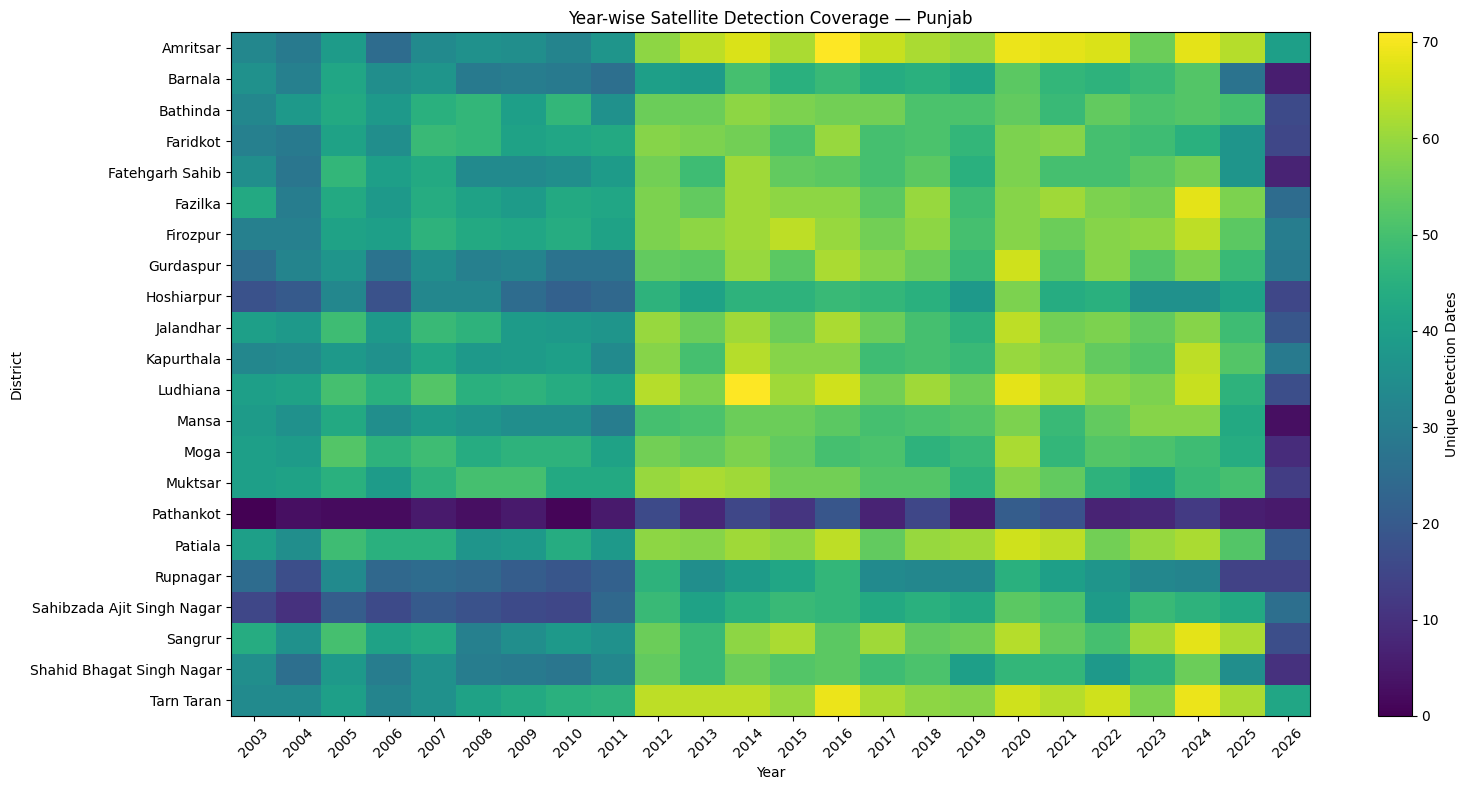

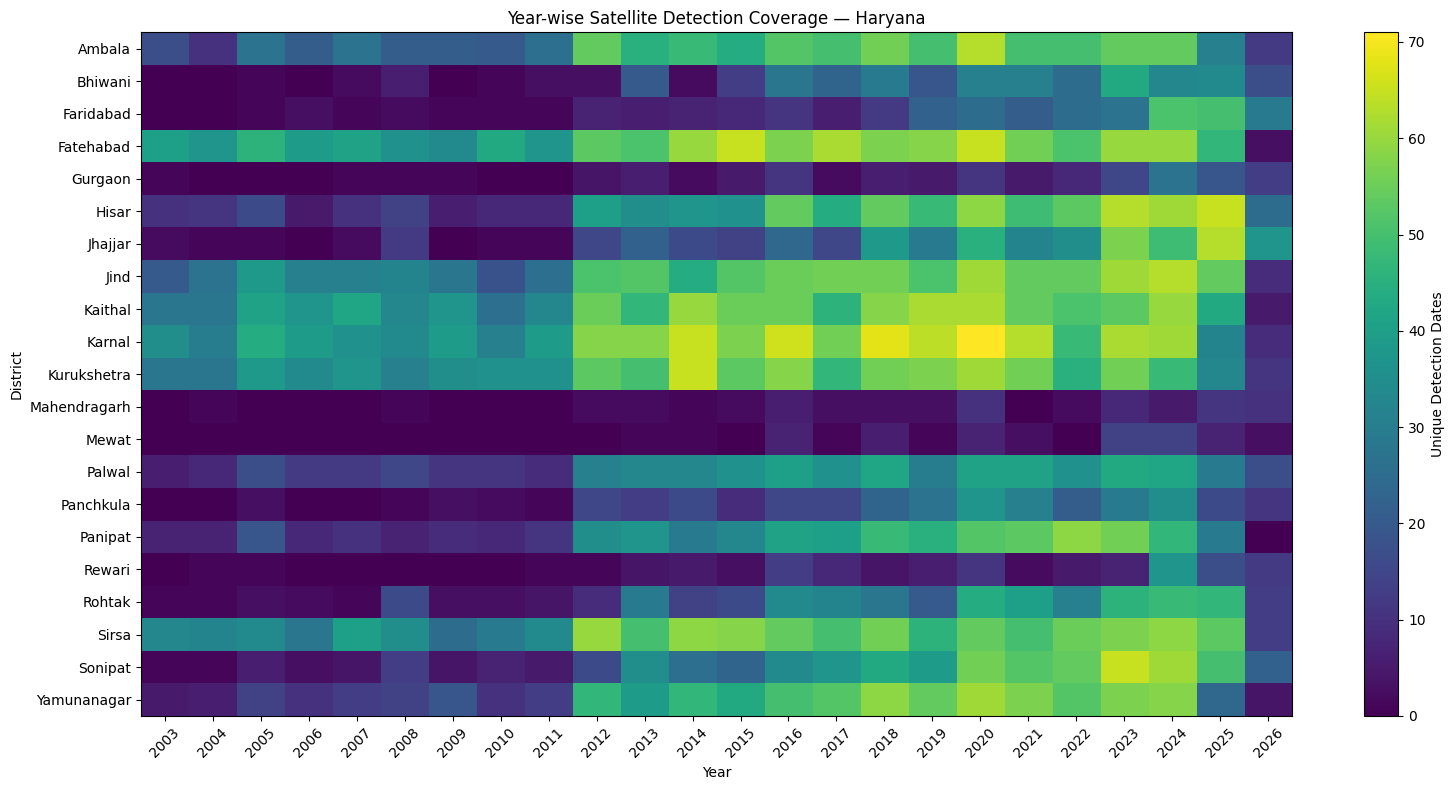

In [13]:


# Extract year from date
fires_india["year"] = fires_india["date"].dt.year
# Count unique detection dates per district per year
district_year = (
    fires_india
    .groupby(["state", "district", "year"])["date"]
    .nunique()
    .reset_index(name="detection_dates")
)

# Create district-year matrix
coverage_matrix = district_year.pivot_table(
    index=["state", "district"],
    columns="year",
    values="detection_dates",
    fill_value=0
)

display(coverage_matrix)

# Plot separate heatmaps for each state
for state in ["Punjab", "Haryana"]:
    state_data = coverage_matrix.loc[state]

    plt.figure(figsize=(16, 8))

    plt.imshow(
        state_data,
        aspect="auto",
        interpolation="nearest"
    )

    plt.colorbar(label="Unique Detection Dates")

    plt.title(f"Year-wise Satellite Detection Coverage — {state}")
    plt.xlabel("Year")
    plt.ylabel("District")

    plt.xticks(
        range(len(state_data.columns)),
        state_data.columns,
        rotation=45
    )

    plt.yticks(
        range(len(state_data.index)),
        state_data.index
    )

    plt.tight_layout()
    plt.show()



<div style="background-color:#172554; padding:18px; border-radius:10px; color:white;">
  <h2 style="color:#60A5FA;">🛰️ 04 — Duplicate Records & Sensor Overlap Audit</h2>
  <p><b style="color:#FBBF24;">Objective:</b> Investigate duplicate records and overlapping satellite observations.</p>
  <p><b style="color:#86EFAC;">What we will check:</b></p>
  <ul>
    <li>Exact duplicate rows</li>
    <li>Repeated district-date-sensor combinations</li>
    <li>District-date combinations observed by multiple sensors</li>
    <li>Distribution of sensor overlap</li>
  </ul>
  <p style="color:#FCA5A5;"><b>Research caution:</b> Multiple sensors recording detections on the same date do not necessarily represent multiple unique burning events.</p>
</div>


In [15]:

# Check exact duplicate rows
exact_duplicates = fires_india.duplicated().sum()

print("Total exact duplicate rows:", exact_duplicates)

# Display duplicate rows if they exist
duplicate_rows = fires_india[
    fires_india.duplicated(keep=False)
]

display(duplicate_rows.head(10))


Total exact duplicate rows: 0


,year,sensor_group,date,district_id,district,state,country,detections


In [16]:

# Group records by state, district, date and sensor
sensor_key_counts = (
    fires_india
    .groupby(["state", "district", "date", "sensor_group"])
    .size()
    .reset_index(name="record_count")
)

# Find combinations having more than one record
repeated_sensor_keys = sensor_key_counts[
    sensor_key_counts["record_count"] > 1
]

print("Repeated district-date-sensor combinations:",
      len(repeated_sensor_keys))

display(repeated_sensor_keys.head(20))


Repeated district-date-sensor combinations: 0


,state,district,date,sensor_group,record_count


In [17]:

# Count distinct sensors for each district-date combination
sensor_overlap = (
    fires_india
    .groupby(["state", "district", "date"])["sensor_group"]
    .nunique()
    .reset_index(name="number_of_sensors")
)

print("Sensor overlap distribution:")

display(
    sensor_overlap["number_of_sensors"]
    .value_counts()
    .sort_index()
    .to_frame("district_date_combinations")
)


Sensor overlap distribution:


,district_date_combinations
number_of_sensors,
1,12952
2,11429
3,12200


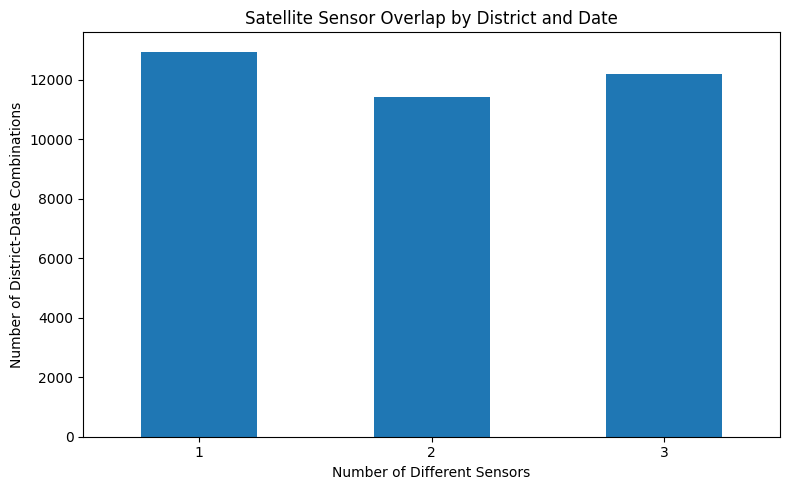

In [18]:

overlap_counts = (
    sensor_overlap["number_of_sensors"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(8, 5))

overlap_counts.plot(kind="bar")

plt.title("Satellite Sensor Overlap by District and Date")
plt.xlabel("Number of Different Sensors")
plt.ylabel("Number of District-Date Combinations")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()



<div style="background-color:#172554; padding:18px; border-radius:10px; color:white;">
  <h2 style="color:#60A5FA;">🔥 05 — Detection Count Distribution Audit</h2>
  <p><b style="color:#FBBF24;">Objective:</b> Understand the distribution and statistical properties of satellite fire detections.</p>
  <p><b style="color:#86EFAC;">We will investigate:</b></p>
  <ul>
    <li>Minimum, maximum, mean and median detections</li>
    <li>Detection distribution across satellite sensors</li>
    <li>Detection distribution across Punjab and Haryana</li>
    <li>Potential extreme values and outliers</li>
  </ul>
  <p style="color:#FCA5A5;"><b>Research caution:</b> Detection counts are satellite observations, not confirmed unique agricultural burning incidents.</p>
</div>


In [19]:

# Check the data type
print("Detection column datatype:")
print(fires_india["detections"].dtype)

# Statistical summary
print("\nOverall detection statistics:")
display(fires_india["detections"].describe())

# Check zero and negative values
print("\nZero detections:", (fires_india["detections"] == 0).sum())
print("Negative detections:", (fires_india["detections"] < 0).sum())
print("Missing detections:", fires_india["detections"].isna().sum())


Detection column datatype:
int64

Overall detection statistics:


count    72410.000000
mean        34.696023
std         88.877624
min          1.000000
25%          2.000000
50%          7.000000
75%         27.000000
max       1899.000000
Name: detections, dtype: float64


Zero detections: 0
Negative detections: 0
Missing detections: 0


In [20]:

sensor_statistics = (
    fires_india
    .groupby("sensor_group")["detections"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .round(2)
)

display(sensor_statistics)


,count,mean,median,std,min,max
sensor_group,,,,,,
modis,22504,14.41,5.0,25.36,1,319
snpp,23199,37.37,7.0,82.50,1,1201
viirs,26707,49.47,9.0,119.97,1,1899


In [21]:

state_statistics = (
    fires_india
    .groupby("state")["detections"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .round(2)
)

display(state_statistics)


,count,mean,median,std,min,max
state,,,,,,
Haryana,25683,11.50,3.0,23.19,1,411
Punjab,46727,47.45,11.0,107.18,1,1899


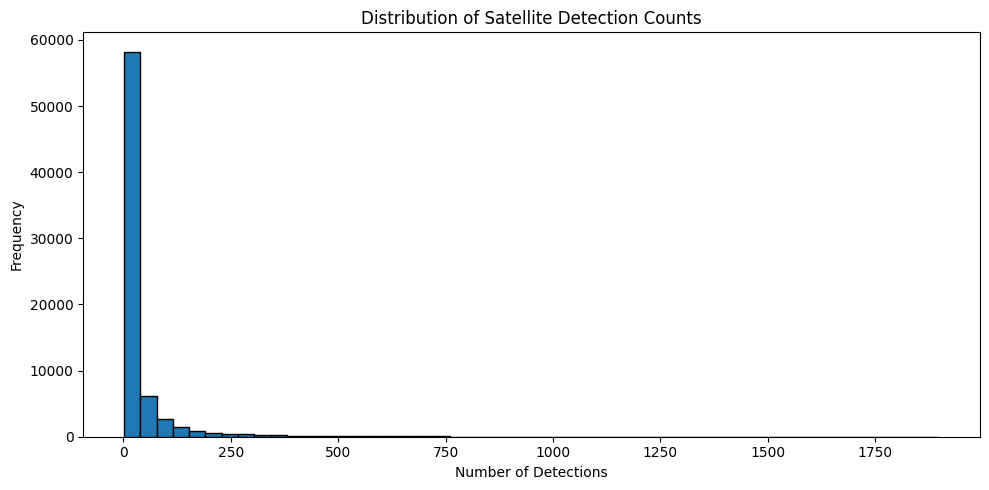

In [22]:

plt.figure(figsize=(10, 5))

plt.hist(
    fires_india["detections"],
    bins=50,
    edgecolor="black"
)

plt.title("Distribution of Satellite Detection Counts")
plt.xlabel("Number of Detections")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()


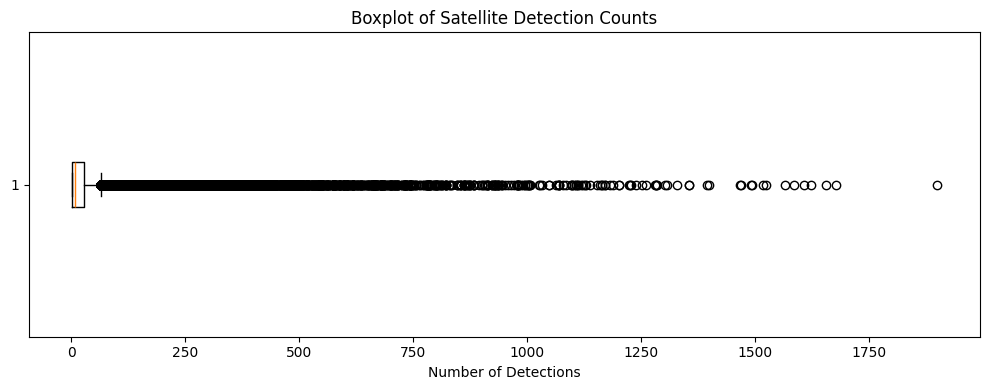

In [23]:

plt.figure(figsize=(10, 4))

plt.boxplot(
    fires_india["detections"],
    vert=False
)

plt.title("Boxplot of Satellite Detection Counts")
plt.xlabel("Number of Detections")

plt.tight_layout()
plt.show()


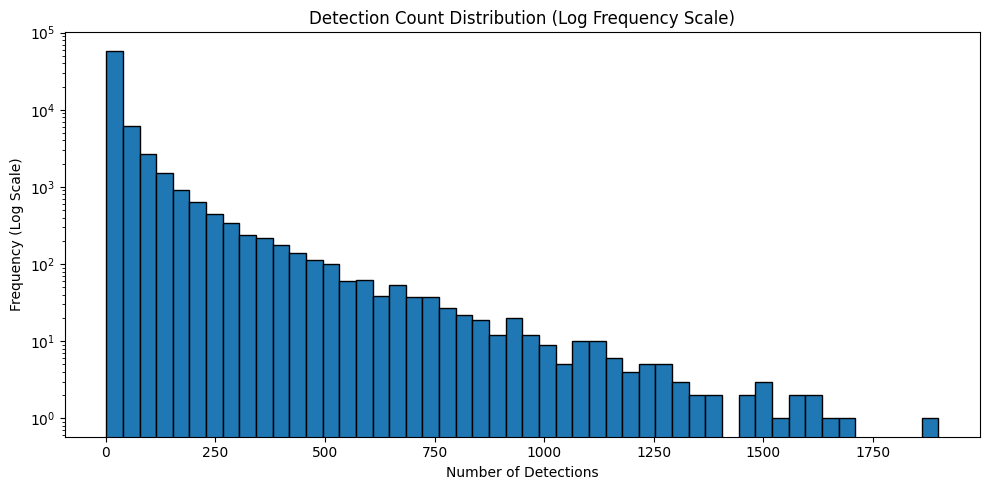

In [24]:

plt.figure(figsize=(10, 5))

plt.hist(
    fires_india["detections"],
    bins=50,
    log=True,
    edgecolor="black"
)

plt.title("Detection Count Distribution (Log Frequency Scale)")
plt.xlabel("Number of Detections")
plt.ylabel("Frequency (Log Scale)")

plt.tight_layout()
plt.show()



In [25]:

Q1 = fires_india["detections"].quantile(0.25)
Q3 = fires_india["detections"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower boundary:", lower_bound)
print("Upper boundary:", upper_bound)

# Identify potential outliers
outliers = fires_india[
    fires_india["detections"] > upper_bound
]

print("\nPotential outlier records:", len(outliers))
print("Outlier percentage:",
      round(len(outliers) / len(fires_india) * 100, 2), "%")


Q1: 2.0
Q3: 27.0
IQR: 25.0
Lower boundary: -35.5
Upper boundary: 64.5

Potential outlier records: 9360
Outlier percentage: 12.93 %


In [26]:

top_20 = fires_india.sort_values(
    by="detections",
    ascending=False
).head(20)

display(
    top_20[
        ["state", "district", "date",
         "year", "sensor_group", "detections"]
    ]
)


,state,district,date,year,sensor_group,detections
242927,Punjab,Sangrur,2020-11-05,2020,viirs,1899
242929,Punjab,Sangrur,2020-11-07,2020,viirs,1678
272770,Punjab,Sangrur,2021-11-08,2021,viirs,1655
272772,Punjab,Sangrur,2021-11-10,2021,viirs,1623
242926,Punjab,Sangrur,2020-11-04,2020,viirs,1607
301938,Punjab,Sangrur,2022-11-05,2022,viirs,1586
272774,Punjab,Sangrur,2021-11-12,2021,viirs,1567
272767,Punjab,Sangrur,2021-11-05,2021,viirs,1525
211981,Punjab,Sangrur,2019-11-04,2019,viirs,1518
211983,Punjab,Sangrur,2019-11-06,2019,viirs,1493


In [27]:

outlier_sensor_summary = (
    outliers
    .groupby("sensor_group")["detections"]
    .agg(["count", "mean", "median", "max"])
    .round(2)
)

display(outlier_sensor_summary)


,count,mean,median,max
sensor_group,,,,
modis,1036,105.95,93.0,319
snpp,3571,178.58,130.0,1201
viirs,4753,221.35,141.0,1899


In [28]:

sensor_outlier_results = []

for sensor, group in fires_india.groupby("sensor_group"):

    Q1 = group["detections"].quantile(0.25)
    Q3 = group["detections"].quantile(0.75)

    IQR = Q3 - Q1

    upper_bound = Q3 + 1.5 * IQR

    sensor_outliers = group[
        group["detections"] > upper_bound
    ]

    outlier_count = len(sensor_outliers)

    outlier_percentage = (
        outlier_count / len(group)
    ) * 100

    sensor_outlier_results.append({
        "Sensor": sensor,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Upper_Bound": upper_bound,
        "Outlier_Count": outlier_count,
        "Outlier_Percentage": round(outlier_percentage, 2)
    })

sensor_outlier_summary = pd.DataFrame(sensor_outlier_results)

display(sensor_outlier_summary)


,Sensor,Q1,Q3,IQR,Upper_Bound,Outlier_Count,Outlier_Percentage
0,modis,2.0,15.0,13.0,34.5,2547,11.32
1,snpp,2.0,33.0,31.0,79.5,2959,12.75
2,viirs,2.0,39.0,37.0,94.5,3489,13.06



<div style="background-color:#172554; padding:18px; border-radius:10px; color:white;">
  <h2 style="color:#60A5FA;">🌾 6 — District-Level Detection Intensity</h2>
  <p><b style="color:#FBBF24;">Objective:</b> Compare satellite detection activity across districts in Punjab and Haryana.</p>
  <p><b style="color:#86EFAC;">We will calculate:</b></p>
  <ul>
    <li>Total recorded detections per district and sensor</li>
    <li>Number of detection records</li>
    <li>Number of unique detection dates</li>
    <li>Average and median detections per record</li>
  </ul>
  <p style="color:#FCA5A5;"><b>Research caution:</b> Cumulative totals are influenced by the number of years and observation opportunities. We will not treat them as direct measures of actual burning intensity.</p>
</div>


In [29]:

district_intensity = (
    fires_india
    .groupby(["state", "district", "sensor_group"])
    .agg(
        total_detections=("detections", "sum"),
        detection_records=("detections", "count"),
        unique_detection_dates=("date", "nunique"),
        average_detections=("detections", "mean"),
        median_detections=("detections", "median")
    )
    .reset_index()
)

district_intensity[
    ["average_detections", "median_detections"]
] = district_intensity[
    ["average_detections", "median_detections"]
].round(2)

display(district_intensity.head(15))


,state,district,sensor_group,total_detections,detection_records,unique_detection_dates,average_detections,median_detections
0,Haryana,Ambala,modis,1150,462,462,2.49,2.0
1,Haryana,Ambala,snpp,4080,597,597,6.83,4.0
2,Haryana,Ambala,viirs,6404,694,694,9.23,5.0
3,Haryana,Bhiwani,modis,95,60,60,1.58,1.0
4,Haryana,Bhiwani,snpp,428,219,219,1.95,1.0
5,Haryana,Bhiwani,viirs,762,330,330,2.31,2.0
6,Haryana,Faridabad,modis,18,17,17,1.06,1.0
7,Haryana,Faridabad,snpp,275,197,197,1.40,1.0
8,Haryana,Faridabad,viirs,635,305,305,2.08,1.0
9,Haryana,Fatehabad,modis,10525,834,834,12.62,7.0


In [30]:

for sensor in ["modis", "snpp", "viirs"]:

    print(f"\nTop 10 districts for {sensor.upper()}")

    top_districts = (
        district_intensity[
            district_intensity["sensor_group"] == sensor
        ]
        .sort_values(
            by="total_detections",
            ascending=False
        )
        .head(10)
    )

    display(
        top_districts[
            ["state", "district", "total_detections",
             "unique_detection_dates", "average_detections"]
        ]
    )



Top 10 districts for MODIS


,state,district,total_detections,unique_detection_dates,average_detections
120,Punjab,Sangrur,36873,831,44.37
96,Punjab,Ludhiana,26529,925,28.68
102,Punjab,Moga,25103,884,28.40
111,Punjab,Patiala,22728,910,24.98
69,Punjab,Bathinda,22590,904,24.99
105,Punjab,Muktsar,20746,935,22.19
81,Punjab,Firozpur,19562,887,22.05
78,Punjab,Fazilka,16087,902,17.83
99,Punjab,Mansa,14536,807,18.01
66,Punjab,Barnala,14451,667,21.67



Top 10 districts for SNPP


,state,district,total_detections,unique_detection_dates,average_detections
121,Punjab,Sangrur,98520,739,133.32
70,Punjab,Bathinda,64243,686,93.65
103,Punjab,Moga,60957,671,90.85
97,Punjab,Ludhiana,58529,777,75.33
106,Punjab,Muktsar,54331,697,77.95
112,Punjab,Patiala,52157,776,67.21
82,Punjab,Firozpur,48086,759,63.35
79,Punjab,Fazilka,46342,744,62.29
100,Punjab,Mansa,45599,662,68.88
67,Punjab,Barnala,40139,555,72.32



Top 10 districts for VIIRS


,state,district,total_detections,unique_detection_dates,average_detections
122,Punjab,Sangrur,154933,815,190.10
71,Punjab,Bathinda,102410,748,136.91
104,Punjab,Moga,92084,724,127.19
107,Punjab,Muktsar,83543,751,111.24
98,Punjab,Ludhiana,81205,858,94.64
113,Punjab,Patiala,78998,844,93.60
83,Punjab,Firozpur,74991,833,90.03
101,Punjab,Mansa,72758,726,100.22
80,Punjab,Fazilka,71403,821,86.97
128,Punjab,Tarn Taran,61969,921,67.28


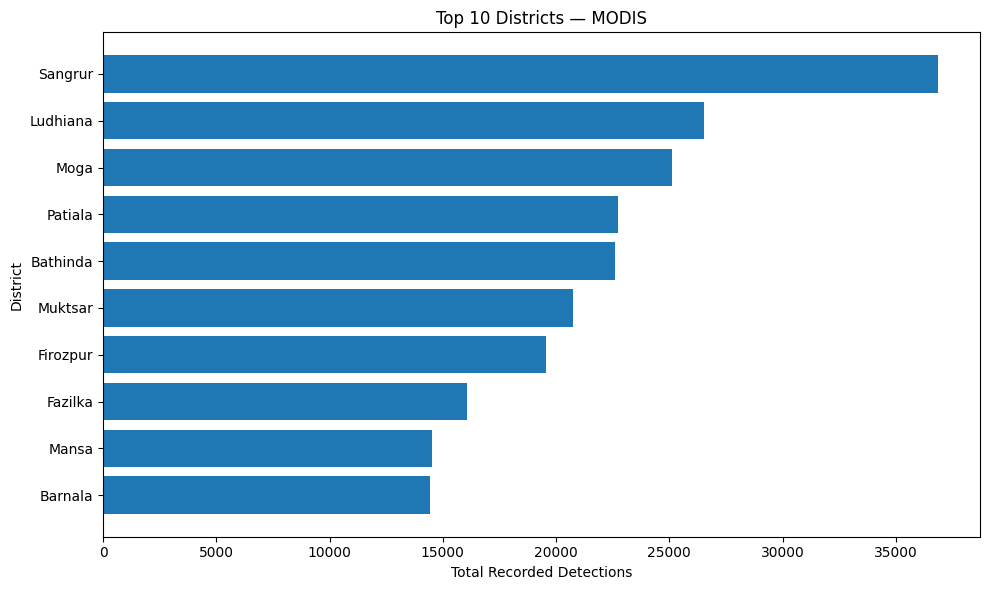

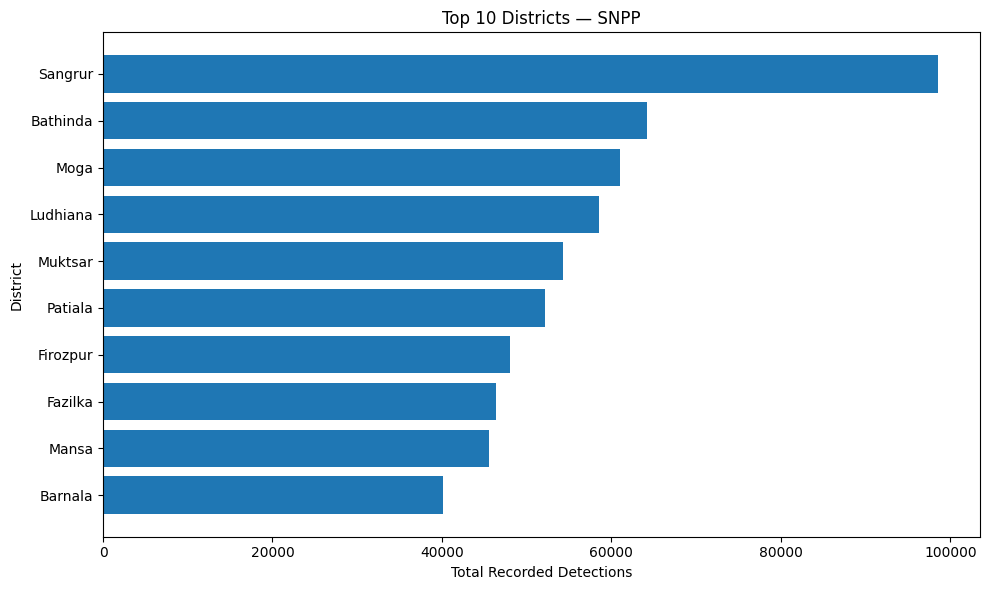

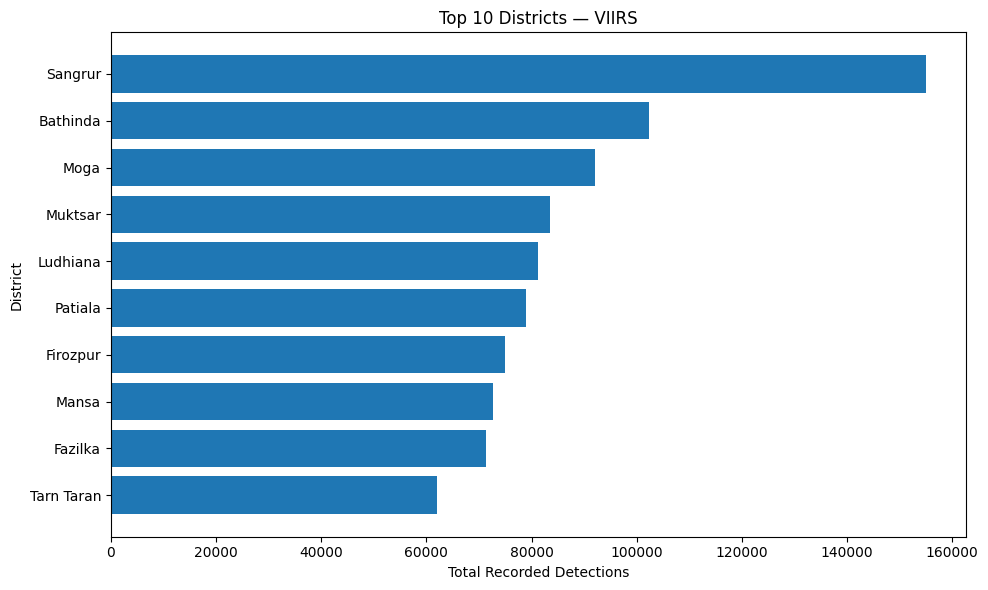

In [31]:

for sensor in ["modis", "snpp", "viirs"]:

    top_districts = (
        district_intensity[
            district_intensity["sensor_group"] == sensor
        ]
        .nlargest(10, "total_detections")
        .sort_values("total_detections")
    )

    plt.figure(figsize=(10, 6))

    plt.barh(
        top_districts["district"],
        top_districts["total_detections"]
    )

    plt.title(f"Top 10 Districts — {sensor.upper()}")
    plt.xlabel("Total Recorded Detections")
    plt.ylabel("District")

    plt.tight_layout()
    plt.show()



### 🔍 FIRMS Dataset 2 — Initial Audit
**Objective:** Understand the structure and contents of the seasonal district-level satellite detections dataset.

We will inspect:
- Dataset dimensions
- Column names
- Data types
- First five records


In [35]:
file_path2="../Data/Raw_data/FIRMS/district_season.csv"

In [37]:

district_season = pd.read_csv(
   file_path2
)

print("Dataset shape:", district_season.shape)

display(district_season.head())

district_season.info()


Dataset shape: (84875, 8)


,year,season,district_id,district,state,country,sensor,detections
0,2003,rice,534,East Godavari,Andhra Pradesh,India,MODIS Aqua,3
1,2003,rice,534,East Godavari,Andhra Pradesh,India,MODIS Terra,4
2,2003,rice,535,Guntur,Andhra Pradesh,India,MODIS Aqua,6
3,2003,rice,535,Guntur,Andhra Pradesh,India,MODIS Terra,10
4,2003,rice,536,Kadapa(YSR),Andhra Pradesh,India,MODIS Aqua,1


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 84875 entries, 0 to 84874
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   year         84875 non-null  int64 
 1   season       84875 non-null  object
 2   district_id  84875 non-null  int64 
 3   district     84875 non-null  object
 4   state        84875 non-null  object
 5   country      84875 non-null  object
 6   sensor       84875 non-null  object
 7   detections   84875 non-null  int64 
dtypes: int64(3), object(5)
memory usage: 5.2+ MB


In [38]:

# 1. Check exact duplicate rows
print("Exact duplicate rows:", district_season.duplicated().sum())

# 2. Check duplicate combinations
key_columns = ["year", "season", "district_id", "sensor"]

print(
    "Duplicate year-season-district-sensor combinations:",
    district_season.duplicated(subset=key_columns).sum()
)

# 3. Understand the available coverage
print("\nYear range:")
print(district_season["year"].min(), "to", district_season["year"].max())

print("\nSeasons:")
print(district_season["season"].value_counts())

print("\nSensors:")
print(district_season["sensor"].value_counts())

print("\nStates:")
print(district_season["state"].nunique(), "unique states")

# 4. Check our research states
punjab_haryana = district_season[
    district_season["state"].isin(["Punjab", "Haryana"])
]

print("\nPunjab and Haryana records:")
print(punjab_haryana.shape)

display(
    punjab_haryana.groupby("state").agg(
        records=("detections", "size"),
        districts=("district", "nunique"),
        years=("year", "nunique"),
        total_detections=("detections", "sum")
    )
)


Exact duplicate rows: 0
Duplicate year-season-district-sensor combinations: 0

Year range:
2003 to 2026

Seasons:
season
wheat    48922
rice     35953
Name: count, dtype: int64

Sensors:
sensor
MODIS Aqua       22801
VIIRS S-NPP      22324
MODIS Terra      20249
VIIRS NOAA-20    13526
VIIRS NOAA-21     5975
Name: count, dtype: int64

States:
41 unique states

Punjab and Haryana records:
(10772, 8)


,records,districts,years,total_detections
state,,,,
Haryana,2713,21,24,353144
Punjab,8059,56,24,2809551



### 📊 Punjab & Haryana — Seasonal Detection Analysis
**Objective:** Compare satellite detections across districts, seasons and years.

We will identify:
- Total detections by state
- Rice vs wheat seasonal detections
- Top 10 districts by detections
- Year-wise detection patterns


In [39]:

# 1. State-wise summary
display(
    punjab_haryana.groupby("state").agg(
        records=("detections", "size"),
        districts=("district", "nunique"),
        years=("year", "nunique"),
        total_detections=("detections", "sum"),
        average_detections=("detections", "mean")
    )
)

# 2. State and season comparison
season_summary = (
    punjab_haryana.groupby(["state", "season"])["detections"]
    .sum()
    .unstack(fill_value=0)
)

display(season_summary)

# 3. Top 10 districts by total detections
top_districts = (
    punjab_haryana.groupby(["state", "district"])["detections"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

display(top_districts)

# 4. Year-wise detection totals
yearly_summary = (
    punjab_haryana.groupby(["year", "state"])["detections"]
    .sum()
    .unstack(fill_value=0)
)

display(yearly_summary.tail(10))


,records,districts,years,total_detections,average_detections
state,,,,,
Haryana,2713,21,24,353144,130.167342
Punjab,8059,56,24,2809551,348.622782


season,rice,wheat
state,,
Haryana,189653,163491
Punjab,1829296,980255


state   district  
Punjab  Sangrur       230573
        Moga          158104
        Bathinda      156579
        Ludhiana      147998
        Muktsar       133734
        Firozpur      128332
        Patiala       127109
        Fazilka       117984
        Tarn Taran    115848
        Sheikhpura    105545
Name: detections, dtype: int64

state,Haryana,Punjab
year,,
2017,18171,122506
2018,32014,238094
2019,28485,202071
2020,20948,256933
2021,33565,278863
2022,19997,206500
2023,20411,228627
2024,24780,182136
2025,18895,163764


In [40]:

print("Detection statistics:")
display(district_season["detections"].describe())

print("Zero detections:",
      (district_season["detections"] == 0).sum())

print("Negative detections:",
      (district_season["detections"] < 0).sum())

Q1 = district_season["detections"].quantile(0.25)
Q3 = district_season["detections"].quantile(0.75)
IQR = Q3 - Q1

upper_limit = Q3 + 1.5 * IQR

print("\nQ1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Upper outlier boundary:", upper_limit)

print("Potential outliers:",
      (district_season["detections"] > upper_limit).sum())

print("\nTop 10 records:")
display(
    district_season.nlargest(10, "detections")
)


Detection statistics:


count    84875.000000
mean       110.505991
std        376.605342
min          1.000000
25%          3.000000
50%         11.000000
75%         57.000000
max      10548.000000
Name: detections, dtype: float64

Zero detections: 0
Negative detections: 0

Q1: 3.0
Q3: 57.0
IQR: 54.0
Upper outlier boundary: 138.0
Potential outliers: 12398

Top 10 records:


,year,season,district_id,district,state,country,sensor,detections
28669,2016,rice,279,Sangrur,Punjab,India,VIIRS S-NPP,10548
45701,2020,rice,279,Sangrur,Punjab,India,VIIRS NOAA-20,10396
45702,2020,rice,279,Sangrur,Punjab,India,VIIRS S-NPP,9964
50574,2021,rice,279,Sangrur,Punjab,India,VIIRS S-NPP,9462
50573,2021,rice,279,Sangrur,Punjab,India,VIIRS NOAA-20,9335
15530,2012,rice,279,Sangrur,Punjab,India,VIIRS S-NPP,9253
22069,2014,rice,279,Sangrur,Punjab,India,VIIRS S-NPP,9021
28646,2016,rice,271,Ludhiana,Punjab,India,VIIRS S-NPP,8208
18760,2013,rice,279,Sangrur,Punjab,India,VIIRS S-NPP,8106
50507,2021,rice,262,Bathinda,Punjab,India,VIIRS S-NPP,7929



### 🔎 FIRMS Seasonal Dataset — Detection Quality
**Objective:** Examine the distribution and validity of seasonal detection counts.

We will check:
- Minimum and maximum detections
- Zero and negative values
- Quartiles and potential outliers
- Highest detection records


In [43]:

print("Detection statistics:")
display(district_season["detections"].describe())

print("Zero detections:",
      (district_season["detections"] == 0).sum())

print("Negative detections:",
      (district_season["detections"] < 0).sum())

Q1 = district_season["detections"].quantile(0.25)
Q3 = district_season["detections"].quantile(0.75)
IQR = Q3 - Q1

upper_limit = Q3 + 1.5 * IQR

print("\nQ1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Upper outlier boundary:", upper_limit)

print("Potential outliers:",
      (district_season["detections"] > upper_limit).sum())

print("\nTop 10 records:")
display(district_season.nlargest(10, "detections"))


Detection statistics:


count    84875.000000
mean       110.505991
std        376.605342
min          1.000000
25%          3.000000
50%         11.000000
75%         57.000000
max      10548.000000
Name: detections, dtype: float64

Zero detections: 0
Negative detections: 0

Q1: 3.0
Q3: 57.0
IQR: 54.0
Upper outlier boundary: 138.0
Potential outliers: 12398

Top 10 records:


,year,season,district_id,district,state,country,sensor,detections
28669,2016,rice,279,Sangrur,Punjab,India,VIIRS S-NPP,10548
45701,2020,rice,279,Sangrur,Punjab,India,VIIRS NOAA-20,10396
45702,2020,rice,279,Sangrur,Punjab,India,VIIRS S-NPP,9964
50574,2021,rice,279,Sangrur,Punjab,India,VIIRS S-NPP,9462
50573,2021,rice,279,Sangrur,Punjab,India,VIIRS NOAA-20,9335
15530,2012,rice,279,Sangrur,Punjab,India,VIIRS S-NPP,9253
22069,2014,rice,279,Sangrur,Punjab,India,VIIRS S-NPP,9021
28646,2016,rice,271,Ludhiana,Punjab,India,VIIRS S-NPP,8208
18760,2013,rice,279,Sangrur,Punjab,India,VIIRS S-NPP,8106
50507,2021,rice,262,Bathinda,Punjab,India,VIIRS S-NPP,7929



### 🔍 FIRMS Dataset 3 — Season Totals Audit
**Objective:** Inspect the seasonal aggregate satellite-detection dataset.

We will examine its dimensions, columns, data types and sample records before checking missing values and aggregation consistency.


In [44]:
file_path3="../Data/Raw_data/FIRMS/season_totals.csv"

In [46]:
season_totals=pd.read_csv(file_path3)

In [47]:
display(season_totals.head())

season_totals.info()


,year,season,state,country,sensor,detections,frp_mw_sum
0,2003,rice,Outside mapped districts,NaN,MODIS Aqua,10,189
1,2003,rice,Outside mapped districts,NaN,MODIS Terra,1,24
2,2003,rice,Andhra Pradesh,India,MODIS Aqua,24,315
3,2003,rice,Andhra Pradesh,India,MODIS Terra,32,472
4,2003,rice,Arunachal Pradesh,India,MODIS Aqua,31,309


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5654 entries, 0 to 5653
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   year        5654 non-null   int64 
 1   season      5654 non-null   object
 2   state       5654 non-null   object
 3   country     5518 non-null   object
 4   sensor      5654 non-null   object
 5   detections  5654 non-null   int64 
 6   frp_mw_sum  5654 non-null   int64 
dtypes: int64(3), object(4)
memory usage: 309.3+ KB



### 🧪 FIRMS Season Totals — Data Integrity
**Objective:** Check missing values, duplicate records, year coverage, seasons, sensors and geographic coverage.


In [48]:

# 1. Missing values
print("Missing values:")
display(season_totals.isnull().sum())

# 2. Exact duplicates
print("\nExact duplicate rows:",
      season_totals.duplicated().sum())

# 3. Check duplicate combinations
key_columns = ["year", "season", "state", "sensor"]

print(
    "Duplicate year-season-state-sensor combinations:",
    season_totals.duplicated(subset=key_columns).sum()
)

# 4. Dataset coverage
print("\nYear range:",
      season_totals["year"].min(),
      "to",
      season_totals["year"].max())

print("\nSeasons:")
print(season_totals["season"].value_counts())

print("\nSensors:")
print(season_totals["sensor"].value_counts())

print("\nStates:")
print(season_totals["state"].nunique())

# 5. Inspect missing country records
print("\nRecords with missing country:")
display(
    season_totals[
        season_totals["country"].isna()
    ].head(10)
)


Missing values:


year            0
season          0
state           0
country       136
sensor          0
detections      0
frp_mw_sum      0
dtype: int64


Exact duplicate rows: 0
Duplicate year-season-state-sensor combinations: 152

Year range: 2003 to 2026

Seasons:
season
wheat    2956
rice     2698
Name: count, dtype: int64

Sensors:
sensor
MODIS Aqua       1716
MODIS Terra      1649
VIIRS S-NPP      1238
VIIRS NOAA-20     734
VIIRS NOAA-21     317
Name: count, dtype: int64

States:
42

Records with missing country:


,year,season,state,country,sensor,detections,frp_mw_sum
0,2003,rice,Outside mapped districts,NaN,MODIS Aqua,10,189
1,2003,rice,Outside mapped districts,NaN,MODIS Terra,1,24
66,2003,wheat,Outside mapped districts,NaN,MODIS Aqua,102,9579
67,2003,wheat,Outside mapped districts,NaN,MODIS Terra,32,1119
135,2004,rice,Outside mapped districts,NaN,MODIS Aqua,14,159
136,2004,rice,Outside mapped districts,NaN,MODIS Terra,5,82
198,2004,wheat,Outside mapped districts,NaN,MODIS Aqua,55,4477
199,2004,wheat,Outside mapped districts,NaN,MODIS Terra,48,1498
272,2005,rice,Outside mapped districts,NaN,MODIS Aqua,13,196
273,2005,rice,Outside mapped districts,NaN,MODIS Terra,2,24



### 📋 FIRMS Season Totals — Duplicate & Coverage Audit
**Objective:** Verify record uniqueness and understand the temporal, seasonal, sensor and geographic coverage.


In [49]:

# Duplicate checks
print("Exact duplicates:", season_totals.duplicated().sum())

key_columns = ["year", "season", "state", "sensor"]

print(
    "Duplicate combinations:",
    season_totals.duplicated(subset=key_columns).sum()
)

# Coverage
print("\nYear range:",
      season_totals["year"].min(),
      "to",
      season_totals["year"].max())

print("\nSeason distribution:")
print(season_totals["season"].value_counts())

print("\nSensor distribution:")
print(season_totals["sensor"].value_counts())

print("\nNumber of states:",
      season_totals["state"].nunique())

print("\nPunjab and Haryana:")
display(
    season_totals[
        season_totals["state"].isin(["Punjab", "Haryana"])
    ].groupby(["state", "season"]).agg(
        records=("detections", "size"),
        total_detections=("detections", "sum"),
        total_frp=("frp_mw_sum", "sum")
    )
)


Exact duplicates: 0
Duplicate combinations: 152

Year range: 2003 to 2026

Season distribution:
season
wheat    2956
rice     2698
Name: count, dtype: int64

Sensor distribution:
sensor
MODIS Aqua       1716
MODIS Terra      1649
VIIRS S-NPP      1238
VIIRS NOAA-20     734
VIIRS NOAA-21     317
Name: count, dtype: int64

Number of states: 42

Punjab and Haryana:


records  total_detections  total_frp
state   season                                      
Haryana rice         76            189653    1353555
        wheat        76            163491    1403314
Punjab  rice        152           1829296   15075068
        wheat       152            980255    8463514


### ⚠️ Investigating Duplicate Aggregation Keys
**Objective:** Understand why multiple records share the same year, season, state and sensor.

We will inspect all records belonging to duplicated combinations before deciding whether they are valid or erroneous.


In [50]:

key_columns = ["year", "season", "state", "sensor"]

duplicate_rows = season_totals[
    season_totals.duplicated(
        subset=key_columns,
        keep=False
    )
].sort_values(key_columns)

print("Rows involved in duplicate combinations:",
      len(duplicate_rows))

display(duplicate_rows.head(20))

print("\nStates appearing in duplicate combinations:")
display(duplicate_rows["state"].value_counts().head(15))


Rows involved in duplicate combinations: 304


,year,season,state,country,sensor,detections,frp_mw_sum
39,2003,rice,Punjab,India,MODIS Aqua,8720,135500
62,2003,rice,Punjab,Pakistan,MODIS Aqua,712,6595
40,2003,rice,Punjab,India,MODIS Terra,1931,25215
63,2003,rice,Punjab,Pakistan,MODIS Terra,158,1695
111,2003,wheat,Punjab,India,MODIS Aqua,1452,34763
131,2003,wheat,Punjab,Pakistan,MODIS Aqua,807,20595
112,2003,wheat,Punjab,India,MODIS Terra,2365,50463
132,2003,wheat,Punjab,Pakistan,MODIS Terra,1439,32837
174,2004,rice,Punjab,India,MODIS Aqua,8054,125534
194,2004,rice,Punjab,Pakistan,MODIS Aqua,743,6978



States appearing in duplicate combinations:


state
Punjab    304
Name: count, dtype: int64


### 🔧 Correcting the Duplicate Check
**Objective:** Include country in the aggregation key because state names can occur in multiple countries.

We will check whether duplicate combinations remain after correcting the key.


In [51]:

key_columns = [
    "year",
    "season",
    "state",
    "country",
    "sensor"
]

print(
    "Duplicate combinations after correction:",
    season_totals.duplicated(
        subset=key_columns
    ).sum()
)


Duplicate combinations after correction: 0



### 📊 FIRMS Season Totals — Numerical Quality Audit
**Objective:** Examine detection counts and Fire Radiative Power (FRP).

We will inspect descriptive statistics, zero/negative values and unusually high observations.


In [52]:

for col in ["detections", "frp_mw_sum"]:

    print(f"\n--- {col} ---")

    display(season_totals[col].describe())

    print("Zero values:", (season_totals[col] == 0).sum())
    print("Negative values:", (season_totals[col] < 0).sum())

    Q1 = season_totals[col].quantile(0.25)
    Q3 = season_totals[col].quantile(0.75)
    IQR = Q3 - Q1

    upper_limit = Q3 + 1.5 * IQR

    print("Potential outliers:",
          (season_totals[col] > upper_limit).sum())

print("\nTop detection records:")
display(season_totals.nlargest(10, "detections"))

print("\nTop FRP records:")
display(season_totals.nlargest(10, "frp_mw_sum"))



--- detections ---


count     5654.000000
mean      1662.070746
std       5576.428631
min          1.000000
25%         19.000000
50%        101.000000
75%        737.750000
max      87883.000000
Name: detections, dtype: float64

Zero values: 0
Negative values: 0
Potential outliers: 809

--- frp_mw_sum ---


count      5654.000000
mean      13873.952954
std       40946.659494
min           0.000000
25%         191.250000
50%        1240.000000
75%        8723.750000
max      612714.000000
Name: frp_mw_sum, dtype: float64

Zero values: 7
Negative values: 0
Potential outliers: 884

Top detection records:


,year,season,state,country,sensor,detections,frp_mw_sum
2226,2016,rice,Punjab,India,VIIRS S-NPP,87883,612714
3623,2021,rice,Punjab,India,VIIRS S-NPP,78505,611216
3315,2020,rice,Punjab,India,VIIRS NOAA-20,77904,577288
3622,2021,rice,Punjab,India,VIIRS NOAA-20,77518,605888
3316,2020,rice,Punjab,India,VIIRS S-NPP,76307,559860
1787,2014,rice,Punjab,India,VIIRS S-NPP,72096,546269
1332,2012,rice,Punjab,India,VIIRS S-NPP,69334,486594
2007,2015,rice,Punjab,India,VIIRS S-NPP,62160,429909
1560,2013,rice,Punjab,India,VIIRS S-NPP,61704,433917
2707,2018,rice,Punjab,India,VIIRS NOAA-20,61049,415474



Top FRP records:


,year,season,state,country,sensor,detections,frp_mw_sum
2226,2016,rice,Punjab,India,VIIRS S-NPP,87883,612714
3623,2021,rice,Punjab,India,VIIRS S-NPP,78505,611216
3622,2021,rice,Punjab,India,VIIRS NOAA-20,77518,605888
3315,2020,rice,Punjab,India,VIIRS NOAA-20,77904,577288
3316,2020,rice,Punjab,India,VIIRS S-NPP,76307,559860
1787,2014,rice,Punjab,India,VIIRS S-NPP,72096,546269
1332,2012,rice,Punjab,India,VIIRS S-NPP,69334,486594
1560,2013,rice,Punjab,India,VIIRS S-NPP,61704,433917
2007,2015,rice,Punjab,India,VIIRS S-NPP,62160,429909
5543,2026,wheat,Madhya Pradesh,India,VIIRS NOAA-21,53490,426725



### 🔗 FIRMS — Seasonal Dataset Reconciliation
**Objective:** Compare state-level seasonal detection totals against the sum of district-level seasonal detections.

We will:
1. Aggregate district-level detections by year, season, state, country and sensor.
2. Match these against the state-level totals.
3. Calculate the differences.

This will help identify whether the two datasets are consistent.


In [53]:

# 1. Aggregate district-level data
district_agg = (
    district_season
    .groupby(
        ["year", "season", "state", "country", "sensor"],
        as_index=False
    )["detections"]
    .sum()
)

# 2. Keep mapped Indian state totals
state_agg = season_totals[
    (season_totals["country"] == "India") &
    (season_totals["state"] != "Outside mapped districts")
].copy()

# 3. Merge the two aggregates
comparison = district_agg.merge(
    state_agg,
    on=["year", "season", "state", "country", "sensor"],
    how="inner",
    suffixes=("_district", "_state")
)

# 4. Calculate differences
comparison["difference"] = (
    comparison["detections_state"] -
    comparison["detections_district"]
)

comparison["match"] = comparison["difference"] == 0

print("Matched combinations:", len(comparison))
print("Exact matches:", comparison["match"].sum())
print("Non-matches:", (~comparison["match"]).sum())

display(comparison.head(10))


Matched combinations: 4590
Exact matches: 4590
Non-matches: 0


,year,season,state,country,sensor,detections_district,detections_state,frp_mw_sum,difference,match
0,2003,rice,Andhra Pradesh,India,MODIS Aqua,24,24,315,0,True
1,2003,rice,Andhra Pradesh,India,MODIS Terra,32,32,472,0,True
2,2003,rice,Arunachal Pradesh,India,MODIS Aqua,31,31,309,0,True
3,2003,rice,Arunachal Pradesh,India,MODIS Terra,5,5,76,0,True
4,2003,rice,Assam,India,MODIS Aqua,29,29,279,0,True
5,2003,rice,Assam,India,MODIS Terra,28,28,291,0,True
6,2003,rice,Bihar,India,MODIS Aqua,24,24,179,0,True
7,2003,rice,Bihar,India,MODIS Terra,4,4,35,0,True
8,2003,rice,Chhattisgarh,India,MODIS Aqua,20,20,171,0,True
9,2003,rice,Chhattisgarh,India,MODIS Terra,11,11,78,0,True



### 🔍 FIRMS Cross-Dataset Reconciliation

**Objective:** Verify whether district-level seasonal detections agree with state-level seasonal totals.

**Methodology:**
1. Aggregated `district_season.csv` by year, season, state, country and sensor.
2. Filtered `season_totals.csv` to mapped Indian states.
3. Compared both datasets using an inner join on the same grouping columns.
4. Calculated the difference between state-level and aggregated district-level detections.

**Results:**
- Matched combinations: 4,590
- Exact matches: 4,590
- Non-matches: 0
- Match rate: 100%

**Conclusion:**

All 4,590 matched combinations have identical detection totals. This demonstrates complete internal consistency between the district-level and state-level seasonal FIRMS datasets for the matched Indian records.

**Research note:** This is an internal consistency check, not independent validation of satellite detections against ground truth.



# 🌾 PART 2: CREAMS DATASET AUDITING

## 🎯 Objective
Audit all five CREAMS datasets to understand their structure, completeness, geographical coverage, temporal coverage, and reliability.

### 📂 Datasets
1. district_daily.csv
2. bulletins.csv
3. validation.json
4. state_daily.csv
5. year_compare.csv

### ⚠️ Important auditing principles
- Never assume missing values mean zero.
- Never delete records during auditing.
- Identify missing rows as well as missing cells.
- Check consistency between related datasets.
- Preserve all original raw files.

**Final goal:** Determine whether CREAMS data is suitable for district-level daily agricultural burning prediction.


In [54]:
CREAMS_file_path="../Data/Raw_data/CREAMS/district_daily.csv"

In [55]:
creams_daily=pd.read_csv(CREAMS_file_path)

In [56]:
# Dataset dimensions
print("Dataset Shape:", creams_daily.shape)

# Column names
print("\nColumns:")
print(creams_daily.columns.tolist())

# First five records
print("\nFirst Five Records:")
display(creams_daily.head())

# Data types and non-null counts
print("\nDataset Information:")
creams_daily.info()

# Statistical summary
print("\nStatistical Summary:")
display(creams_daily.describe(include="all").T)


Dataset Shape: (198423, 13)

Columns:
['date', 'season', 'season_year', 'state', 'district', 'fires_day', 'fires_cumulative', 'cum_period_start', 'day_source', 'cum_source', 'cum_check', 'bulletin_file', 'cum_bulletin_file']

First Five Records:


,date,season,season_year,state,district,fires_day,fires_cumulative,cum_period_start,day_source,cum_source,cum_check,bulletin_file,cum_bulletin_file
0,2016-10-01,rice,2016,Punjab,Amritsar,NaN,48.0,2016-10-01,NaN,district_table,sum_ok,01.RiceResidueFireBulletin_01Oct_2020_ICAR.pdf,01.RiceResidueFireBulletin_01Oct_2020_ICAR.pdf
1,2016-10-01,rice,2016,Punjab,Barnala,NaN,0.0,2016-10-01,NaN,district_table,sum_ok,01.RiceResidueFireBulletin_01Oct_2020_ICAR.pdf,01.RiceResidueFireBulletin_01Oct_2020_ICAR.pdf
2,2016-10-01,rice,2016,Punjab,Bathinda,NaN,3.0,2016-10-01,NaN,district_table,sum_ok,01.RiceResidueFireBulletin_01Oct_2020_ICAR.pdf,01.RiceResidueFireBulletin_01Oct_2020_ICAR.pdf
3,2016-10-01,rice,2016,Punjab,Faridkot,NaN,2.0,2016-10-01,NaN,district_table,sum_ok,01.RiceResidueFireBulletin_01Oct_2020_ICAR.pdf,01.RiceResidueFireBulletin_01Oct_2020_ICAR.pdf
4,2016-10-01,rice,2016,Punjab,Fatehgarh Sahib,NaN,0.0,2016-10-01,NaN,district_table,sum_ok,01.RiceResidueFireBulletin_01Oct_2020_ICAR.pdf,01.RiceResidueFireBulletin_01Oct_2020_ICAR.pdf



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 198423 entries, 0 to 198422
Data columns (total 13 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   date               198423 non-null  object 
 1   season             198423 non-null  object 
 2   season_year        198423 non-null  int64  
 3   state              198423 non-null  object 
 4   district           198423 non-null  object 
 5   fires_day          42529 non-null   float64
 6   fires_cumulative   198362 non-null  float64
 7   cum_period_start   198362 non-null  object 
 8   day_source         42529 non-null   object 
 9   cum_source         198362 non-null  object 
 10  cum_check          198362 non-null  object 
 11  bulletin_file      198423 non-null  object 
 12  cum_bulletin_file  198362 non-null  object 
dtypes: float64(2), int64(1), object(10)
memory usage: 19.7+ MB

Statistical Summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
date,198423,1054,2020-10-02,236,NaN,NaN,NaN,NaN,NaN,NaN,NaN
season,198423,2,rice,143019,NaN,NaN,NaN,NaN,NaN,NaN,NaN
season_year,198423.0,NaN,NaN,NaN,2022.364429,2.671374,2016.0,2021.0,2023.0,2024.0,2026.0
state,198423,7,Uttar Pradesh,79553,NaN,NaN,NaN,NaN,NaN,NaN,NaN
district,198423,237,Pratapgarh,1555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fires_day,42529.0,NaN,NaN,NaN,16.461991,47.407685,1.0,1.0,3.0,10.0,893.0
fires_cumulative,198362.0,NaN,NaN,NaN,150.788634,624.434824,0.0,0.0,2.0,37.0,13645.0
cum_period_start,198362,17,2020-09-15,17338,NaN,NaN,NaN,NaN,NaN,NaN,NaN
day_source,42529,1,event_list_count,42529,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cum_source,198362,1,district_table,198362,NaN,NaN,NaN,NaN,NaN,NaN,NaN



## 🔎 Step 2: Missing Value Analysis

**Objective:** Identify the extent and distribution of missing values in the CREAMS district-daily dataset.

We will calculate:
- Total missing values per column.
- Percentage of missing values per column.
- Total missing values across the dataset.

⚠️ **Important:** We will not replace missing values with zero or delete records at this stage.


In [57]:

# Calculate missing values
missing_analysis = pd.DataFrame({
    "Missing_Count": creams_daily.isnull().sum(),
    "Missing_Percentage": (
        creams_daily.isnull().sum() / len(creams_daily)
    ) * 100
})

# Sort columns by missing percentage
missing_analysis = missing_analysis.sort_values(
    by="Missing_Percentage",
    ascending=False
)

display(missing_analysis)

# Overall missing-value summary
total_missing = creams_daily.isnull().sum().sum()
total_cells = creams_daily.size

print("Total Missing Cells:", total_missing)
print("Total Dataset Cells:", total_cells)
print("Overall Missing Percentage:", round(
    (total_missing / total_cells) * 100, 2
), "%")


,Missing_Count,Missing_Percentage
fires_day,155894,78.566497
day_source,155894,78.566497
fires_cumulative,61,0.030742
cum_period_start,61,0.030742
cum_source,61,0.030742
cum_bulletin_file,61,0.030742
cum_check,61,0.030742
district,0,0.000000
season,0,0.000000
date,0,0.000000


Total Missing Cells: 312093
Total Dataset Cells: 2579499
Overall Missing Percentage: 12.1 %



## 🔍 Step 3: Investigating Missing Daily Counts

**Objective:** Understand whether missing `fires_day` values are distributed uniformly or concentrated in particular years and seasons.

We will calculate:
- Total records per season and year.
- Available daily counts.
- Missing daily counts.
- Missing percentage.

**Research importance:** If missingness is concentrated in certain years or seasons, it may introduce bias into our training dataset.

⚠️ We will not assume missing values represent zero burning.


In [58]:

# Create a summary by season and year
missing_pattern = (
    creams_daily
    .groupby(["season_year", "season"])
    .agg(
        Total_Records=("fires_day", "size"),
        Available_Daily_Counts=("fires_day", "count"),
        Missing_Daily_Counts=("fires_day", lambda x: x.isna().sum())
    )
    .reset_index()
)


In [59]:
missing_pattern["Missing_Percentage"] = (
    missing_pattern["Missing_Daily_Counts"] /
    missing_pattern["Total_Records"]
) * 100

In [60]:
# Sort by year and season
missing_pattern = missing_pattern.sort_values(
    ["season_year", "season"]
)

display(missing_pattern)


,season_year,season,Total_Records,Available_Daily_Counts,Missing_Daily_Counts,Missing_Percentage
0,2016,rice,7197,0,7197,100.000000
1,2017,rice,7218,0,7218,100.000000
2,2018,rice,7265,2786,4479,61.651755
3,2019,rice,7272,2166,5106,70.214521
4,2020,rice,17400,3313,14087,80.959770
5,2021,rice,17339,3682,13657,78.764635
6,2022,rice,17338,3551,13787,79.518976
7,2022,wheat,11107,3258,7849,70.667147
8,2023,rice,17338,4041,13297,76.692813
9,2023,wheat,11095,3034,8061,72.654349



## 🔍 Step 4: Relationship Between Missing Daily Counts and Their Sources

**Objective:** Verify whether missing values in `fires_day` and `day_source` occur in the same records.

We will:
1. Compare their missing-value patterns.
2. Count records where only one of the two columns is missing.
3. Inspect examples of available and missing daily counts.

**Research question:** Is the absence of daily counts associated with the absence of source documentation?


In [61]:

# Compare missingness patterns
print("Both columns missing:",
      (creams_daily["fires_day"].isna() &
       creams_daily["day_source"].isna()).sum())

print("\nDaily count missing, source available:",
      (creams_daily["fires_day"].isna() &
       creams_daily["day_source"].notna()).sum())

print("\nDaily count available, source missing:",
      (creams_daily["fires_day"].notna() &
       creams_daily["day_source"].isna()).sum())

print("\nBoth columns available:",
      (creams_daily["fires_day"].notna() &
       creams_daily["day_source"].notna()).sum())

# Inspect missing daily-count records
print("\nExamples with missing daily counts:")
display(
    creams_daily.loc[
        creams_daily["fires_day"].isna(),
        ["district", "state", "date", "season",
         "season_year", "fires_day", "day_source"]
    ].head(10)
)

# Inspect available daily-count records
print("\nExamples with available daily counts:")
display(
    creams_daily.loc[
        creams_daily["fires_day"].notna(),
        ["district", "state", "date", "season",
         "season_year", "fires_day", "day_source"]
    ].head(10)
)


Both columns missing: 155894

Daily count missing, source available: 0

Daily count available, source missing: 0

Both columns available: 42529

Examples with missing daily counts:


,district,state,date,season,season_year,fires_day,day_source
0,Amritsar,Punjab,2016-10-01,rice,2016,NaN,NaN
1,Barnala,Punjab,2016-10-01,rice,2016,NaN,NaN
2,Bathinda,Punjab,2016-10-01,rice,2016,NaN,NaN
3,Faridkot,Punjab,2016-10-01,rice,2016,NaN,NaN
4,Fatehgarh Sahib,Punjab,2016-10-01,rice,2016,NaN,NaN
5,Fazilka,Punjab,2016-10-01,rice,2016,NaN,NaN
6,Firozpur,Punjab,2016-10-01,rice,2016,NaN,NaN
7,Gurdaspur,Punjab,2016-10-01,rice,2016,NaN,NaN
8,Hoshiarpur,Punjab,2016-10-01,rice,2016,NaN,NaN
9,Jalandhar,Punjab,2016-10-01,rice,2016,NaN,NaN



Examples with available daily counts:


,district,state,date,season,season_year,fires_day,day_source
14415,Amritsar,Punjab,2018-10-01,rice,2018,11.0,event_list_count
14419,Fatehgarh Sahib,Punjab,2018-10-01,rice,2018,2.0,event_list_count
14421,Firozpur,Punjab,2018-10-01,rice,2018,1.0,event_list_count
14423,Hoshiarpur,Punjab,2018-10-01,rice,2018,1.0,event_list_count
14433,SBS Nagar,Punjab,2018-10-01,rice,2018,1.0,event_list_count
14437,Ambala,Haryana,2018-10-01,rice,2018,2.0,event_list_count
14443,Hisar,Haryana,2018-10-01,rice,2018,1.0,event_list_count
14447,Karnal,Haryana,2018-10-01,rice,2018,1.0,event_list_count
14448,Kurukshetra,Haryana,2018-10-01,rice,2018,3.0,event_list_count
14453,Panipat,Haryana,2018-10-01,rice,2018,1.0,event_list_count



## 🔍 Step 5: Relationship Between Daily and Cumulative Counts

**Objective:** Investigate whether cumulative burning counts are available for records where daily counts are missing.

We will compare:
- Daily count availability.
- Cumulative count availability.

**Why this matters:** Cumulative counts may provide useful historical information, but they cannot automatically be treated as daily counts.

⚠️ We will not calculate daily values by subtracting cumulative values until we understand their reporting periods and definitions.


In [62]:

# Compare daily and cumulative count availability

daily_cumulative_check = pd.crosstab(
    creams_daily["fires_day"].isna(),
    creams_daily["fires_cumulative"].isna(),
    rownames=["Daily count missing"],
    colnames=["Cumulative count missing"]
)

display(daily_cumulative_check)

# More detailed summary
print("\nDaily count missing, cumulative count available:",
      (creams_daily["fires_day"].isna() &
       creams_daily["fires_cumulative"].notna()).sum())

print("\nBoth daily and cumulative counts available:",
      (creams_daily["fires_day"].notna() &
       creams_daily["fires_cumulative"].notna()).sum())

print("\nBoth daily and cumulative counts missing:",
      (creams_daily["fires_day"].isna() &
       creams_daily["fires_cumulative"].isna()).sum())


Cumulative count missing,False,True
Daily count missing,,
False,42468,61
True,155894,0



Daily count missing, cumulative count available: 155894

Both daily and cumulative counts available: 42468

Both daily and cumulative counts missing: 0



## 🔍 Step 6: Inspecting Cumulative Counts Where Daily Counts Are Missing

**Objective:** Examine cumulative reporting records that do not have corresponding daily counts.

We will inspect:
- District and date.
- Cumulative count.
- Cumulative reporting period start.
- Cumulative source.
- Bulletin file.
- Validation/check information.

**Research importance:** This will help us understand whether cumulative counts can provide useful historical information despite missing daily observations.

⚠️ Cumulative counts will not be treated as daily counts.


In [63]:
# Select records where daily count is missing
# but cumulative count is available

cumulative_only = creams_daily[
    creams_daily["fires_day"].isna() &
    creams_daily["fires_cumulative"].notna()
].copy()

print("Records with cumulative counts but no daily counts:",
      len(cumulative_only))


Records with cumulative counts but no daily counts: 155894


In [64]:
display(
    cumulative_only[
        [
            "district",
            "state",
            "date",
            "season",
            "season_year",
            "fires_cumulative",
            "cum_period_start",
            "cum_source",
            "cum_bulletin_file",
            "cum_check"
        ]
    ].head(15))

,district,state,date,season,season_year,fires_cumulative,cum_period_start,cum_source,cum_bulletin_file,cum_check
0,Amritsar,Punjab,2016-10-01,rice,2016,48.0,2016-10-01,district_table,01.RiceResidueFireBulletin_01Oct_2020_ICAR.pdf,sum_ok
1,Barnala,Punjab,2016-10-01,rice,2016,0.0,2016-10-01,district_table,01.RiceResidueFireBulletin_01Oct_2020_ICAR.pdf,sum_ok
2,Bathinda,Punjab,2016-10-01,rice,2016,3.0,2016-10-01,district_table,01.RiceResidueFireBulletin_01Oct_2020_ICAR.pdf,sum_ok
3,Faridkot,Punjab,2016-10-01,rice,2016,2.0,2016-10-01,district_table,01.RiceResidueFireBulletin_01Oct_2020_ICAR.pdf,sum_ok
4,Fatehgarh Sahib,Punjab,2016-10-01,rice,2016,0.0,2016-10-01,district_table,01.RiceResidueFireBulletin_01Oct_2020_ICAR.pdf,sum_ok
5,Fazilka,Punjab,2016-10-01,rice,2016,0.0,2016-10-01,district_table,01.RiceResidueFireBulletin_01Oct_2020_ICAR.pdf,sum_ok
6,Firozpur,Punjab,2016-10-01,rice,2016,7.0,2016-10-01,district_table,01.RiceResidueFireBulletin_01Oct_2020_ICAR.pdf,sum_ok
7,Gurdaspur,Punjab,2016-10-01,rice,2016,0.0,2016-10-01,district_table,01.RiceResidueFireBulletin_01Oct_2020_ICAR.pdf,sum_ok
8,Hoshiarpur,Punjab,2016-10-01,rice,2016,0.0,2016-10-01,district_table,01.RiceResidueFireBulletin_01Oct_2020_ICAR.pdf,sum_ok
9,Jalandhar,Punjab,2016-10-01,rice,2016,5.0,2016-10-01,district_table,01.RiceResidueFireBulletin_01Oct_2020_ICAR.pdf,sum_ok



## 📈 Step 7: Temporal Behaviour of Cumulative Counts

**Objective:** Determine whether cumulative counts are updated over time or repeated across multiple daily records.

We will investigate:
1. Number of unique observation dates.
2. Number of unique cumulative values per district and season.
3. Whether bulletin filenames are consistent with observation years.
4. How cumulative counts behave for one district over time.

**Research importance:** This helps determine whether cumulative values can be used as historical features and whether their reporting periods are reliable.
"

In [65]:
temp = cumulative_only.copy()

temp["date"] = pd.to_datetime(temp["date"])
temp["cum_period_start"] = pd.to_datetime(temp["cum_period_start"])

# 1. Overall date coverage
print("Unique observation dates:", temp["date"].nunique())
print("Earliest date:", temp["date"].min())
print("Latest date:", temp["date"].max())


Unique observation dates: 1054
Earliest date: 2016-10-01 00:00:00
Latest date: 2026-10-27 00:00:00


In [66]:
cumulative_variation = (
    temp.groupby(
        ["state", "district", "season", "season_year"]
    )
    .agg(
        Records=("fires_cumulative", "size"),
        Unique_Cumulative_Values=("fires_cumulative", "nunique"),
        Unique_Period_Starts=("cum_period_start", "nunique"),
        Unique_Bulletins=("cum_bulletin_file", "nunique")
    )
    .reset_index()
)

print("\nCumulative variation summary:")
display(cumulative_variation.head(15))


Cumulative variation summary:


,state,district,season,season_year,Records,Unique_Cumulative_Values,Unique_Period_Starts,Unique_Bulletins
0,Delhi,Central,rice,2020,77,1,1,77
1,Delhi,Central,rice,2021,77,1,1,77
2,Delhi,Central,rice,2022,77,1,1,77
3,Delhi,Central,rice,2023,77,1,1,77
4,Delhi,Central,rice,2024,77,1,1,77
5,Delhi,Central,rice,2025,77,1,1,77
6,Delhi,Central,rice,2026,43,1,1,43
7,Delhi,Central,wheat,2022,61,1,1,61
8,Delhi,Central,wheat,2023,61,1,1,61
9,Delhi,Central,wheat,2024,61,1,1,61


In [67]:
 #3. Inspect one district over time
amritsar_history = temp[
    (temp["district"] == "Amritsar") &
    (temp["state"] == "Punjab") &
    (temp["season"] == "rice") &
    (temp["season_year"] == 2016)
].sort_values("date")

print("\nAmritsar cumulative history:")
display(
    amritsar_history[
        [
            "date",
            "fires_cumulative",
            "cum_period_start",
            "cum_source",
            "cum_bulletin_file",
            "cum_check"
        ]
    ].head(20)
)

# 4. Inspect bulletin filenames
print("\nMost common bulletin filenames:")
display(temp["cum_bulletin_file"].value_counts().head(15))


Amritsar cumulative history:


,date,fires_cumulative,cum_period_start,cum_source,cum_bulletin_file,cum_check
0,2016-10-01,48.0,2016-10-01,district_table,01.RiceResidueFireBulletin_01Oct_2020_ICAR.pdf,sum_ok
218,2016-10-03,96.0,2016-10-01,district_table,03.RiceResidueFireBulletin_03Oct_2020_ICAR.pdf,sum_ok
436,2016-10-05,123.0,2016-10-01,district_table,05.RiceResidueFireBulletin_05Oct_2020_ICAR.pdf,sum_ok
556,2016-10-06,176.0,2016-10-01,district_table,06.RiceResidueFireBulletin_06Oct_2020_ICAR.pdf,sum_ok
676,2016-10-07,222.0,2016-10-01,district_table,07.RiceResidueFireBulletin_07Oct_2020_ICAR.pdf,sum_ok
796,2016-10-08,261.0,2016-10-01,district_table,08.RiceResidueFireBulletin_08Oct_2020_ICAR.pdf,sum_ok
916,2016-10-09,307.0,2016-10-01,district_table,09.RiceResidueFireBulletin_09Oct_2020_ICAR.pdf,sum_ok
1036,2016-10-10,411.0,2016-10-01,district_table,10.RiceResidueFireBulletin_10Oct_2020_ICAR.pdf,sum_ok
1156,2016-10-11,503.0,2016-10-01,district_table,11.RiceResidueFireBulletin_11Oct_2020_ICAR.pdf,sum_ok
1276,2016-10-12,569.0,2016-10-01,district_table,12.RiceResidueFireBulletin_12Oct_2020_ICAR.pdf,sum_ok



Most common bulletin filenames:


cum_bulletin_file
02.RiceResidueFireBulletin_16Sep_2026_ICAR.pdf    1616
04.RiceResidueFireBulletin_18Sep_2026_ICAR.pdf    1615
03.RiceResidueFireBulletin_17Sep_2026_ICAR.pdf    1614
05.RiceResidueFireBulletin_19Sep_2026_ICAR.pdf    1611
01.RiceResidueFireBulletin_15Sep_2026_ICAR.pdf    1609
06.RiceResidueFireBulletin_20Sep_2026_ICAR.pdf    1607
10.RiceResidueFireBulletin_24Sep_2026_ICAR.pdf    1605
09.RiceResidueFireBulletin_23Sep_2026_ICAR.pdf    1600
08.RiceResidueFireBulletin_22Sep_2026_ICAR.pdf    1600
13.RiceResidueFireBulletin_27Sep_2026_ICAR.pdf    1598
11.RiceResidueFireBulletin_25Sep_2026_ICAR.pdf    1597
12.RiceResidueFireBulletin_26Sep_2026_ICAR.pdf    1593
07.RiceResidueFireBulletin_21Sep_2026_ICAR.pdf    1591
14.RiceResidueFireBulletin_28Sep_2026_ICAR.pdf    1590
15.RiceResidueFireBulletin_29Sep_2026_ICAR.pdf    1559
Name: count, dtype: int64


### 🔍 CREAMS Audit — Cumulative Bulletin Year Consistency

We are checking whether the year in each observation date matches the year mentioned in its cumulative bulletin filename.

**Why is this important?**

A mismatch could indicate incorrect source metadata or a mapping issue. We should identify these inconsistencies before using bulletin information in our analysis.


In [68]:

# Extract the year written in the bulletin filename
temp["bulletin_year"] = (
    temp["cum_bulletin_file"]
    .str.extract(r"_(\d{4})_ICAR\.pdf")[0]
)

# Extract the year from the observation date
temp["observation_year"] = temp["date"].dt.year.astype(str)

# Compare the two years
temp["year_match"] = (
    temp["observation_year"] == temp["bulletin_year"]
)

print("Bulletin year available:")
print(temp["bulletin_year"].notna().sum())

print("\nYear matching summary:")
display(temp["year_match"].value_counts(dropna=False))

print("\nObservation year vs bulletin year:")
display(
    pd.crosstab(
        temp["observation_year"],
        temp["bulletin_year"],
        margins=True
    )
)

print("\nExamples of year mismatches:")
display(
    temp.loc[
        temp["year_match"] == False,
        [
            "district",
            "state",
            "date",
            "season_year",
            "cum_period_start",
            "cum_bulletin_file"
        ]
    ].head(15)
)


Bulletin year available:
155894

Year matching summary:


year_match
False    135733
True      20161
Name: count, dtype: int64


Observation year vs bulletin year:


bulletin_year,2019,2020,2022,2023,2025,2026,All
observation_year,,,,,,,
2016,129,7068,0,0,0,0,7197
2017,129,7089,0,0,0,0,7218
2018,40,4439,0,0,0,0,4479
2019,70,5036,0,0,0,0,5106
2020,0,62,0,0,5214,8811,14087
2021,0,0,0,0,4637,9020,13657
2022,0,0,1,29,4823,16783,21636
2023,0,0,0,17,4807,16534,21358
2024,0,0,0,0,4759,19631,24390



Examples of year mismatches:


,district,state,date,season_year,cum_period_start,cum_bulletin_file
0,Amritsar,Punjab,2016-10-01,2016,2016-10-01,01.RiceResidueFireBulletin_01Oct_2020_ICAR.pdf
1,Barnala,Punjab,2016-10-01,2016,2016-10-01,01.RiceResidueFireBulletin_01Oct_2020_ICAR.pdf
2,Bathinda,Punjab,2016-10-01,2016,2016-10-01,01.RiceResidueFireBulletin_01Oct_2020_ICAR.pdf
3,Faridkot,Punjab,2016-10-01,2016,2016-10-01,01.RiceResidueFireBulletin_01Oct_2020_ICAR.pdf
4,Fatehgarh Sahib,Punjab,2016-10-01,2016,2016-10-01,01.RiceResidueFireBulletin_01Oct_2020_ICAR.pdf
5,Fazilka,Punjab,2016-10-01,2016,2016-10-01,01.RiceResidueFireBulletin_01Oct_2020_ICAR.pdf
6,Firozpur,Punjab,2016-10-01,2016,2016-10-01,01.RiceResidueFireBulletin_01Oct_2020_ICAR.pdf
7,Gurdaspur,Punjab,2016-10-01,2016,2016-10-01,01.RiceResidueFireBulletin_01Oct_2020_ICAR.pdf
8,Hoshiarpur,Punjab,2016-10-01,2016,2016-10-01,01.RiceResidueFireBulletin_01Oct_2020_ICAR.pdf
9,Jalandhar,Punjab,2016-10-01,2016,2016-10-01,01.RiceResidueFireBulletin_01Oct_2020_ICAR.pdf



### ✅ CREAMS Audit — Cumulative Count Validation

We are examining the `cum_check` column to understand whether district-level cumulative counts are consistent with the state totals printed in the source bulletins.

**Why does this matter?**

If district totals do not agree with the corresponding state totals, we need to investigate those records before using them in our research.


In [69]:

# 1. Distribution of cumulative validation checks
print("Cumulative validation check distribution:")
display(temp["cum_check"].value_counts(dropna=False))

# 2. Percentage distribution
print("\nValidation check percentages:")
display(
    temp["cum_check"]
    .value_counts(normalize=True, dropna=False)
    .mul(100)
    .round(2)
)

# 3. Inspect records that did not pass sum_ok
not_sum_ok = temp[
    temp["cum_check"] != "sum_ok"
]

print("\nRecords not marked sum_ok:", len(not_sum_ok))

display(
    not_sum_ok[
        [
            "district",
            "state",
            "date",
            "season",
            "season_year",
            "fires_cumulative",
            "cum_period_start",
            "cum_source",
            "cum_bulletin_file",
            "cum_check"
        ]
    ].head(20)
)


Cumulative validation check distribution:


cum_check
sum_ok    155894
Name: count, dtype: int64


Validation check percentages:


cum_check
sum_ok    100.0
Name: proportion, dtype: float64


Records not marked sum_ok: 0


,district,state,date,season,season_year,fires_cumulative,cum_period_start,cum_source,cum_bulletin_file,cum_check



### 📅 CREAMS Audit — Cumulative Reporting Period Analysis

We are investigating the relationship between the observation date and cumulative period start date.

**Why are we doing this?**

A cumulative count is meaningful only when we understand the period over which it is accumulated.

We will check:
- How many unique cumulative period start dates exist.
- Whether observation dates occur before their period starts.
- How frequently the cumulative period changes.
- Whether cumulative values reset when a new period begins.


In [70]:

# 1. Compare observation dates with cumulative period starts

temp["date"] = pd.to_datetime(temp["date"])
temp["cum_period_start"] = pd.to_datetime(temp["cum_period_start"])

print("Unique cumulative period start dates:",
      temp["cum_period_start"].nunique())

print("\nEarliest period start:",
      temp["cum_period_start"].min())

print("\nLatest period start:",
      temp["cum_period_start"].max())

Unique cumulative period start dates: 17

Earliest period start: 2016-10-01 00:00:00

Latest period start: 2026-09-15 00:00:00


In [71]:
# 2. Calculate the difference between observation date and period start

temp["days_from_period_start"] = (
    temp["date"] - temp["cum_period_start"]
).dt.days

print("\nDays from period start:")
display(temp["days_from_period_start"].describe())


Days from period start:


count    155894.000000
mean         31.154804
std          20.418789
min           0.000000
25%          13.000000
50%          29.000000
75%          47.000000
max          76.000000
Name: days_from_period_start, dtype: float64

In [72]:
# 3. Check whether any observation date is before its period start

before_start = temp[
    temp["days_from_period_start"] < 0
]

print("\nObservations before cumulative period start:",
      len(before_start))



Observations before cumulative period start: 0


In [73]:
print("\nMost common cumulative period starts:")
display(
    temp["cum_period_start"]
    .value_counts()
    .head(15)
)


# 5. Check cumulative period starts by season

print("\nPeriod starts by season:")
display(
    temp.groupby("season")["cum_period_start"]
    .nunique()
)


Most common cumulative period starts:


cum_period_start
2020-09-15    14025
2022-09-15    13787
2021-09-15    13657
2025-09-15    13560
2024-09-15    13313
2023-09-15    13297
2024-04-01    11077
2026-09-15     9244
2023-04-01     8061
2022-04-01     7849
2025-04-01     7789
2017-10-01     7218
2016-10-01     7197
2026-04-01     6173
2019-10-01     5106
Name: count, dtype: int64


Period starts by season:


season
rice     12
wheat     5
Name: cum_period_start, dtype: int64


### 🌾 CREAMS Audit — Season-wise Cumulative Period Mapping

We are mapping every cumulative reporting period to its corresponding season and season-year.

**Why is this important?**

We have discovered that reporting start dates differ across years. This analysis will help us determine whether each season-year has one consistent reporting period or multiple reporting periods.

We will also inspect cumulative count ranges without modifying the original data.


In [74]:

# Group cumulative records by season, year and reporting period

period_summary = (
    temp.groupby(
        ["season", "season_year", "cum_period_start"]
    )
    .agg(
        Total_Records=("fires_cumulative", "size"),
        Unique_Districts=("district", "nunique"),
        First_Observation=("date", "min"),
        Last_Observation=("date", "max"),
        Minimum_Cumulative=("fires_cumulative", "min"),
        Maximum_Cumulative=("fires_cumulative", "max")
    )
    .reset_index()
    .sort_values(["season", "season_year"])
)

print("Season-wise cumulative reporting period summary:")

display(period_summary.to_string(index=False))

print("\nNumber of reporting periods per season-year:")

display(
    period_summary.groupby(
        ["season", "season_year"]
    ).size().rename("Number_of_Periods").reset_index()
)


Season-wise cumulative reporting period summary:


'season  season_year cum_period_start  Total_Records  Unique_Districts First_Observation Last_Observation  Minimum_Cumulative  Maximum_Cumulative\n  rice         2016       2016-10-01           7197               121        2016-10-01       2016-11-30                 0.0             13645.0\n  rice         2017       2017-10-01           7218               121        2017-10-01       2017-11-30                 0.0              9957.0\n  rice         2018       2018-10-01           4479               121        2018-10-01       2018-11-30                 0.0              9981.0\n  rice         2019       2019-10-01           5106               121        2019-10-01       2019-11-30                 0.0              6363.0\n  rice         2020       2020-09-15          14025               233        2020-09-15       2020-11-30                 0.0             11724.0\n  rice         2020       2020-10-01             62                 3        2020-10-01       2020-11-30                 0.


Number of reporting periods per season-year:


,season,season_year,Number_of_Periods
0,rice,2016,1
1,rice,2017,1
2,rice,2018,1
3,rice,2019,1
4,rice,2020,2
5,rice,2021,1
6,rice,2022,1
7,rice,2023,1
8,rice,2024,1
9,rice,2025,1



### 🔎 CREAMS Audit — Investigating the Rice 2020 Reporting Anomaly

We found two cumulative reporting periods for rice 2020.

One period starts on 15 September and contains 14,025 records. The other starts on 1 October and contains only 62 records, with all cumulative values equal to zero.

**Our objective:**
- Identify the three districts involved.
- Check their observation dates.
- Inspect their source bulletin filenames.
- Determine whether these records overlap with the main 15 September reporting period.

We will investigate before deciding whether these records are valid, duplicated or anomalous.


In [75]:

# 1. Extract the two rice 2020 reporting groups

rice_2020 = temp[
    (temp["season"] == "rice") &
    (temp["season_year"] == 2020)
].copy()

period_sep = rice_2020[
    rice_2020["cum_period_start"] == pd.Timestamp("2020-09-15")
]

period_oct = rice_2020[
    rice_2020["cum_period_start"] == pd.Timestamp("2020-10-01")
]

# 2. Inspect the 62 October records

print("October period records:")
display(
    period_oct[
        [
            "district",
            "state",
            "date",
            "fires_cumulative",
            "cum_source",
            "cum_bulletin_file",
            "cum_check"
        ]
    ].sort_values(["district", "date"])
)

# 3. Identify districts in both reporting periods

print("\nDistricts in October period:")
display(period_oct["district"].value_counts())

print("\nDistrict overlap between the two periods:")

print(
    "October districts:",
    period_oct["district"].nunique()
)

print(
    "September period districts:",
    period_sep["district"].nunique()
)

print(
    "October districts also present in September period:",
    period_oct["district"].isin(
        period_sep["district"]
    ).sum()
)

# 4. Inspect source bulletin distribution

print("\nOctober period bulletin files:")
display(period_oct["cum_bulletin_file"].value_counts())

print("\nOctober period cumulative sources:")
display(period_oct["cum_source"].value_counts())

# 5. Compare cumulative count statistics

print("\nSeptember period cumulative counts:")
display(period_sep["fires_cumulative"].describe())

print("\nOctober period cumulative counts:")
display(period_oct["fires_cumulative"].describe())


October period records:


,district,state,date,fires_cumulative,cum_source,cum_bulletin_file,cum_check
32958,Faridkot,Haryana,2020-10-02,0.0,district_table,02.RiceResidueFireBulletin_02Oct_2020_ICAR.pdf,sum_ok
33429,Faridkot Faridabad,Haryana,2020-10-04,0.0,district_table,04.RiceResidueFireBulletin_04Oct_2020_ICAR.pdf,sum_ok
32793,Mahamayanagar,Uttar Pradesh,2020-10-01,0.0,district_table,01.RiceResidueFireBulletin_01Oct_2020_ICAR.pdf,sum_ok
33029,Mahamayanagar,Uttar Pradesh,2020-10-02,0.0,district_table,02.RiceResidueFireBulletin_02Oct_2020_ICAR.pdf,sum_ok
33264,Mahamayanagar,Uttar Pradesh,2020-10-03,0.0,district_table,03.RiceResidueFireBulletin_03Oct_2020_ICAR.pdf,sum_ok
...,...,...,...,...,...,...,...
45371,Mahamayanagar,Uttar Pradesh,2020-11-26,0.0,district_table,57.RiceResidueFireBulletin_26Nov_2020_ICAR.pdf,sum_ok
45586,Mahamayanagar,Uttar Pradesh,2020-11-27,0.0,district_table,58.RiceResidueFireBulletin_27Nov_2020_ICAR.pdf,sum_ok
45801,Mahamayanagar,Uttar Pradesh,2020-11-28,0.0,district_table,59.RiceResidueFireBulletin_28Nov_2020_ICAR.pdf,sum_ok
46016,Mahamayanagar,Uttar Pradesh,2020-11-29,0.0,district_table,60.RiceResidueFireBulletin_29Nov_2020_ICAR.pdf,sum_ok



Districts in October period:


district
Mahamayanagar         60
Faridkot               1
Faridkot Faridabad     1
Name: count, dtype: int64


District overlap between the two periods:
October districts: 3
September period districts: 233
October districts also present in September period: 1

October period bulletin files:


cum_bulletin_file
02.RiceResidueFireBulletin_02Oct_2020_ICAR.pdf    2
04.RiceResidueFireBulletin_04Oct_2020_ICAR.pdf    2
01.RiceResidueFireBulletin_01Oct_2020_ICAR.pdf    1
03.RiceResidueFireBulletin_03Oct_2020_ICAR.pdf    1
05.RiceResidueFireBulletin_05Oct_2020_ICAR.pdf    1
06.RiceResidueFireBulletin_06Oct_2020_ICAR.pdf    1
07.RiceResidueFireBulletin_07Oct_2020_ICAR.pdf    1
08.RiceResidueFireBulletin_08Oct_2020_ICAR.pdf    1
09.RiceResidueFireBulletin_09Oct_2020_ICAR.pdf    1
10.RiceResidueFireBulletin_10Oct_2020_ICAR.pdf    1
11.RiceResidueFireBulletin_11Oct_2020_ICAR.pdf    1
12.RiceResidueFireBulletin_12Oct_2020_ICAR.pdf    1
13.RiceResidueFireBulletin_13Oct_2020_ICAR.pdf    1
14.RiceResidueFireBulletin_14Oct_2020_ICAR.pdf    1
15.RiceResidueFireBulletin_15Oct_2020_ICAR.pdf    1
16.RiceResidueFireBulletin_16Oct_2020_ICAR.pdf    1
17.RiceResidueFireBulletin_17Oct_2020_ICAR.pdf    1
18.RiceResidueFireBulletin_18Oct_2020_ICAR.pdf    1
19.RiceResidueFireBulletin_19Oct_2020_ICAR.pdf

... (2 outputs left out)


September period cumulative counts:


count    14025.000000
mean        71.187451
std        490.085677
min          0.000000
25%          0.000000
50%          1.000000
75%          6.000000
max      11724.000000
Name: fires_cumulative, dtype: float64


October period cumulative counts:


count    62.0
mean      0.0
std       0.0
min       0.0
25%       0.0
50%       0.0
75%       0.0
max       0.0
Name: fires_cumulative, dtype: float64

In [76]:

# 1. Identify the exact district overlap

october_districts = set(period_oct["district"].unique())
september_districts = set(period_sep["district"].unique())

common_districts = october_districts.intersection(
    september_districts
)

print("Districts in both periods:")
print(common_districts)

print("\nOctober-only districts:")
print(october_districts - september_districts)


# 2. Inspect district-state combinations in October

print("\nOctober district-state combinations:")

display(
    period_oct.groupby(
        ["district", "state"]
    ).agg(
        Records=("date", "size"),
        First_Date=("date", "min"),
        Last_Date=("date", "max"),
        Unique_Dates=("date", "nunique"),
        Total_Cumulative=("fires_cumulative", "sum")
    ).reset_index()
)


# 3. Compare records for the overlapping district

if common_districts:

    for district_name in common_districts:

        print(f"\nComparing district: {district_name}")

        september_records = period_sep[
            period_sep["district"] == district_name
        ]

        october_records = period_oct[
            period_oct["district"] == district_name
        ]

        print("September period:")
        display(
            september_records[
                [
                    "district", "state", "date",
                    "fires_cumulative",
                    "cum_period_start",
                    "cum_bulletin_file"
                ]
            ].head(10)
        )

        print("October period:")
        display(
            october_records[
                [
                    "district", "state", "date",
                    "fires_cumulative",
                    "cum_period_start",
                    "cum_bulletin_file"
                ]
            ]
        )


# 4. Check whether October records have duplicate district-date keys
print("\nDuplicate district-date combinations in October:")

print(
    period_oct.duplicated(
        subset=["district", "date"],
        keep=False
    ).sum()
)


Districts in both periods:
{'Faridkot'}

October-only districts:
{'Mahamayanagar', 'Faridkot Faridabad'}

October district-state combinations:


,district,state,Records,First_Date,Last_Date,Unique_Dates,Total_Cumulative
0,Faridkot,Haryana,1,2020-10-02,2020-10-02,1,0.0
1,Faridkot Faridabad,Haryana,1,2020-10-04,2020-10-04,1,0.0
2,Mahamayanagar,Uttar Pradesh,60,2020-10-01,2020-11-30,60,0.0



Comparing district: Faridkot
September period:


,district,state,date,fires_cumulative,cum_period_start,cum_bulletin_file
28955,Faridkot,Punjab,2020-09-15,0.0,2020-09-15,01.RiceResidueFireBulletin_15Sep_2026_ICAR.pdf
29189,Faridkot,Punjab,2020-09-16,0.0,2020-09-15,02.RiceResidueFireBulletin_16Sep_2026_ICAR.pdf
29423,Faridkot,Punjab,2020-09-17,0.0,2020-09-15,03.RiceResidueFireBulletin_17Sep_2026_ICAR.pdf
29657,Faridkot,Punjab,2020-09-18,0.0,2020-09-15,04.RiceResidueFireBulletin_18Sep_2026_ICAR.pdf
29891,Faridkot,Punjab,2020-09-19,0.0,2020-09-15,05.RiceResidueFireBulletin_19Sep_2026_ICAR.pdf
30125,Faridkot,Punjab,2020-09-20,0.0,2020-09-15,06.RiceResidueFireBulletin_20Sep_2026_ICAR.pdf
30359,Faridkot,Punjab,2020-09-21,0.0,2020-09-15,07.RiceResidueFireBulletin_21Sep_2026_ICAR.pdf
30593,Faridkot,Punjab,2020-09-22,0.0,2020-09-15,08.RiceResidueFireBulletin_22Sep_2026_ICAR.pdf
30827,Faridkot,Punjab,2020-09-23,0.0,2020-09-15,09.RiceResidueFireBulletin_23Sep_2026_ICAR.pdf
31061,Faridkot,Punjab,2020-09-24,0.0,2020-09-15,10.RiceResidueFireBulletin_24Sep_2026_ICAR.pdf


October period:


,district,state,date,fires_cumulative,cum_period_start,cum_bulletin_file
32958,Faridkot,Haryana,2020-10-02,0.0,2020-10-01,02.RiceResidueFireBulletin_02Oct_2020_ICAR.pdf



Duplicate district-date combinations in October:
0



### 🔎 CREAMS Audit — Full Dataset Duplicate Analysis

We are checking the complete district_daily dataset for duplicate records.

We will investigate:

1. Exact duplicate rows.
2. Duplicate district-date-season combinations.
3. Duplicate district-date-season-year combinations.
4. Duplicate district-date-state-season-year combinations.

**Why is this important?**

A district should not accidentally have multiple records for the same observation date and reporting season. Duplicate records can distort target values and model training.

We are only auditing. No rows will be removed.


In [78]:

# 1. Exact duplicate rows

print("Exact duplicate rows:")
print(creams_daily.duplicated().sum())


# 2. Duplicate district-date-season combinations

key_1 = ["district", "date", "season"]

print("\nDuplicate district-date-season combinations:")
print(
    creams_daily.duplicated(
        subset=key_1,
        keep=False
    ).sum()
)


# 3. Duplicate district-date-season-year combinations

key_2 = ["district", "date", "season", "season_year"]

print("\nDuplicate district-date-season-year combinations:")
print(
    creams_daily.duplicated(
        subset=key_2,
        keep=False
    ).sum()
)


# 4. Duplicate full geographic-season combinations

key_3 = ["district", "state", "date", "season", "season_year"]

duplicate_mask = creams_daily.duplicated(
    subset=key_3,
    keep=False
)

print("\nDuplicate full geographic-season combinations:")
print(duplicate_mask.sum())


# 5. Inspect duplicates if found

if duplicate_mask.sum() > 0:
    display(
        creams_daily.loc[duplicate_mask]
        .sort_values(key_3)
        .head(20)
    )
else:
    print("\nNo duplicate records found for the full key.")


Exact duplicate rows:
0

Duplicate district-date-season combinations:
1034

Duplicate district-date-season-year combinations:
1034

Duplicate full geographic-season combinations:
0

No duplicate records found for the full key.



### 🗺️ Investigating Repeated District Names

**Objective:** Verify whether repeated district-date-season combinations are caused by identical district names in different states.

We will inspect the district, state, date, season and season year columns.

🔎 This helps us distinguish genuine duplicate records from valid geographic observations.


In [79]:

# Identify repeated district-date-season-year combinations

repeated_mask = creams_daily.duplicated(
    subset=key_2,
    keep=False
)

# Display examples with their state information

display(
    creams_daily.loc[
        repeated_mask,
        ["district", "state", "date", "season", "season_year"]
    ]
    .sort_values(["district", "date", "state"])
    .head(30)
)


,district,state,date,season,season_year
144772,Central,Delhi,2022-04-10,wheat,2022
144792,Central,Madhya Pradesh,2022-04-10,wheat,2022
144773,East,Delhi,2022-04-10,wheat,2022
144800,East,Madhya Pradesh,2022-04-10,wheat,2022
32958,Faridkot,Haryana,2020-10-02,rice,2020
32934,Faridkot,Punjab,2020-10-02,rice,2020
144774,New Delhi,Delhi,2022-04-10,wheat,2022
144816,New Delhi,Madhya Pradesh,2022-04-10,wheat,2022
144775,North,Delhi,2022-04-10,wheat,2022
144817,North,Madhya Pradesh,2022-04-10,wheat,2022



### 🔢 CREAMS — Numeric Value Integrity Audit

**Objective:** Check the validity of daily and cumulative agricultural burning counts.

We will inspect data types, zero values, negative values, and minimum/maximum values.

⚠️ Zero is not automatically an error. It may represent a district reporting no burning activity.


In [80]:

count_columns = ["fires_day", "fires_cumulative"]

for col in count_columns:

    values = pd.to_numeric(creams_daily[col], errors="coerce")

    print(f"\n{'='*45}")
    print(f"Column: {col}")
    print(f"Original data type: {creams_daily[col].dtype}")

    print("Missing values:", values.isna().sum())

    print("Unexpected non-numeric values:",
          (creams_daily[col].notna() & values.isna()).sum())

    print("Negative values:", (values < 0).sum())

    print("Zero values:", (values == 0).sum())

    print("Positive values:", (values > 0).sum())

    print("Minimum:", values.min())

    print("Maximum:", values.max())



Column: fires_day
Original data type: float64
Missing values: 155894
Unexpected non-numeric values: 0
Negative values: 0
Zero values: 0
Positive values: 42529
Minimum: 1.0
Maximum: 893.0

Column: fires_cumulative
Original data type: float64
Missing values: 61
Unexpected non-numeric values: 0
Negative values: 0
Zero values: 80268
Positive values: 118094
Minimum: 0.0
Maximum: 13645.0



### 🔢 Numeric Integrity Audit — CREAMS district_daily.csv

- No unexpected non-numeric values in either count column.
- No negative values in either count column.
- `fires_day` contains 42,529 positive observations and no zero observations.
- `fires_day` has 155,894 missing values.
- `fires_cumulative` contains 80,268 zero values and 118,094 positive values.
- Maximum daily count: 893.
- Maximum cumulative count: 13,645.

**Conclusion:** No invalid negative or non-numeric counts were detected. Missing daily counts require careful treatment and must not automatically be interpreted as zero.



### 📈 Cumulative Count Consistency Audit

**Objective:** Check whether cumulative burning counts decrease over time within the same district and reporting period.

A cumulative count should normally remain unchanged or increase.

⚠️ We will not assume every decrease is an error; it may indicate a reporting or source-related issue.


In [81]:

cum_data = creams_daily.dropna(
    subset=["fires_cumulative", "cum_period_start"]
).copy()

cum_data = cum_data.sort_values(
    ["district", "state", "season", "season_year",
     "cum_period_start", "date"]
)

cum_data["previous_cumulative"] = (
    cum_data.groupby(
        ["district", "state", "season", "season_year",
         "cum_period_start"]
    )["fires_cumulative"].shift(1)
)

decreases = cum_data[
    cum_data["fires_cumulative"] <
    cum_data["previous_cumulative"]
]

print("Total consecutive cumulative decreases:", len(decreases))

if len(decreases) > 0:
    display(
        decreases[
            ["district", "state", "date", "season",
             "season_year", "cum_period_start",
             "previous_cumulative", "fires_cumulative"]
        ].head(20)
    )
else:
    print("No cumulative decreases found.")


Total consecutive cumulative decreases: 72


,district,state,date,season,season_year,cum_period_start,previous_cumulative,fires_cumulative
91137,Aligarh,Uttar Pradesh,2023-10-28,rice,2023,2023-09-15,79.0,78.0
125815,Amethi,Uttar Pradesh,2025-10-28,rice,2025,2025-09-15,3.0,1.0
125901,Baran,Rajasthan,2025-10-28,rice,2025,2025-09-15,81.0,80.0
108489,Basti,Uttar Pradesh,2024-10-28,rice,2024,2024-09-15,2.0,1.0
125827,Basti,Uttar Pradesh,2025-10-28,rice,2025,2025-09-15,2.0,1.0
7497,Bijnor,Uttar Pradesh,2017-10-03,rice,2017,2017-10-01,1.0,0.0
73817,Bulandshahr,Uttar Pradesh,2022-10-28,rice,2022,2022-09-15,8.0,7.0
91155,Bulandshahr,Uttar Pradesh,2023-10-28,rice,2023,2023-09-15,7.0,6.0
56591,Datia,Madhya Pradesh,2021-10-28,rice,2021,2021-09-15,12.0,10.0
39048,Fazilka,Punjab,2020-10-28,rice,2020,2020-09-15,425.0,322.0



### 📉 Investigation of Cumulative Count Decreases

**Objective:** Measure how frequently cumulative counts decrease and identify whether the issue is concentrated in particular seasons or years.

We will also inspect the source bulletin references for the affected records.


In [82]:

print("Total cumulative decreases:", len(decreases))

print("\nDecreases by season:")

display(
    decreases.groupby("season").size()
)

print("\nDecreases by season year:")

display(
    decreases.groupby(["season", "season_year"]).size()
    .reset_index(name="decrease_count")
)

print("\nInspecting source references:")

display(
    decreases[
        [
            "district",
            "state",
            "date",
            "season",
            "season_year",
            "cum_period_start",
            "previous_cumulative",
            "fires_cumulative",
            "cum_source",
            "cum_bulletin_file",
            "cum_check"
        ]
    ].head(20)
)


Total cumulative decreases: 72

Decreases by season:


season
rice     30
wheat    42
dtype: int64


Decreases by season year:


,season,season_year,decrease_count
0,rice,2016,1
1,rice,2017,2
2,rice,2018,1
3,rice,2020,4
4,rice,2021,6
5,rice,2022,5
6,rice,2023,4
7,rice,2024,2
8,rice,2025,5
9,wheat,2025,20



Inspecting source references:


,district,state,date,season,season_year,cum_period_start,previous_cumulative,fires_cumulative,cum_source,cum_bulletin_file,cum_check
91137,Aligarh,Uttar Pradesh,2023-10-28,rice,2023,2023-09-15,79.0,78.0,district_table,44.RiceResidueFireBulletin_28Oct_2025_ICAR.pdf,sum_ok
125815,Amethi,Uttar Pradesh,2025-10-28,rice,2025,2025-09-15,3.0,1.0,district_table,44.RiceResidueFireBulletin_28Oct_2025_ICAR.pdf,sum_ok
125901,Baran,Rajasthan,2025-10-28,rice,2025,2025-09-15,81.0,80.0,district_table,44.RiceResidueFireBulletin_28Oct_2025_ICAR.pdf,sum_ok
108489,Basti,Uttar Pradesh,2024-10-28,rice,2024,2024-09-15,2.0,1.0,district_table,44.RiceResidueFireBulletin_28Oct_2025_ICAR.pdf,sum_ok
125827,Basti,Uttar Pradesh,2025-10-28,rice,2025,2025-09-15,2.0,1.0,district_table,44.RiceResidueFireBulletin_28Oct_2025_ICAR.pdf,sum_ok
7497,Bijnor,Uttar Pradesh,2017-10-03,rice,2017,2017-10-01,1.0,0.0,district_table,03.RiceResidueFireBulletin_03Oct_2020_ICAR.pdf,sum_ok
73817,Bulandshahr,Uttar Pradesh,2022-10-28,rice,2022,2022-09-15,8.0,7.0,district_table,44.RiceResidueFireBulletin_28Oct_2025_ICAR.pdf,sum_ok
91155,Bulandshahr,Uttar Pradesh,2023-10-28,rice,2023,2023-09-15,7.0,6.0,district_table,44.RiceResidueFireBulletin_28Oct_2025_ICAR.pdf,sum_ok
56591,Datia,Madhya Pradesh,2021-10-28,rice,2021,2021-09-15,12.0,10.0,district_table,44.RiceResidueFireBulletin_28Oct_2025_ICAR.pdf,sum_ok
39048,Fazilka,Punjab,2020-10-28,rice,2020,2020-09-15,425.0,322.0,district_table,44.RiceResidueFireBulletin_28Oct_2025_ICAR.pdf,sum_ok



## 📑 CREAMS Dataset 2: Bulletin Records

**Objective:** Load the bulletin metadata dataset.

This dataset will help us investigate bulletin dates, source references, reporting periods and the inconsistencies discovered during the `district_daily.csv` audit.

🟢 This is a read-only loading step. No data will be modified.


In [ ]:
CREAMS_file_path2="../Data/Raw_data/CREAMS/bulletins.csv"

In [84]:
creams_bulletins = pd.read_csv(CREAMS_file_path2
    
)

In [85]:
print("Dataset loaded successfully!")
print("Shape:", creams_bulletins.shape)

Dataset loaded successfully!
Shape: (862, 10)



### 📑 CREAMS — Bulletin Metadata Inspection

**Objective:** Identify the available metadata fields and understand how bulletins are recorded.

We will inspect column names, data types, missing values and a few sample records.

🔎 Special attention: bulletin dates, filenames, reporting periods and season information.


In [86]:

# Inspect column names and data types

print("Dataset shape:", creams_bulletins.shape)

print("\nColumn names:")
print(creams_bulletins.columns.tolist())

print("\nData types:")
print(creams_bulletins.dtypes)

print("\nMissing values:")
display(
    creams_bulletins.isnull().sum()
)

print("\nFirst 10 records:")
display(creams_bulletins.head(10))


Dataset shape: (862, 10)

Column names:
['date', 'season', 'kind', 'bulletin_no', 'file', 'url', 'pages', 'primary', 'duplicate_of', 'error']

Data types:
date             object
season           object
kind             object
bulletin_no     float64
file             object
url              object
pages             int64
primary         float64
duplicate_of     object
error           float64
dtype: object

Missing values:


date              6
season            6
kind              0
bulletin_no       6
file              0
url               0
pages             0
primary           6
duplicate_of    805
error           862
dtype: int64


First 10 records:


,date,season,kind,bulletin_no,file,url,pages,primary,duplicate_of,error
0,2018-10-01,rice,bulletin,1.0,01.RiceResidueFireBulletin_01Oct_2018_ICAR.pdf,https://creams.iari.res.in/Creams_website_bull...,9,1.0,NaN,NaN
1,2018-10-02,rice,bulletin,2.0,02.RiceResidueFireBulletin_02Oct_2018_ICAR.pdf,https://creams.iari.res.in/Creams_website_bull...,11,1.0,NaN,NaN
2,2018-10-03,rice,bulletin,3.0,03.RiceResidueFireBulletin_03Oct_2018_ICAR.pdf,https://creams.iari.res.in/Creams_website_bull...,9,1.0,NaN,NaN
3,2018-10-04,rice,bulletin,4.0,04.RiceResidueFireBulletin_04Oct_2018_ICAR.pdf,https://creams.iari.res.in/Creams_website_bull...,11,1.0,NaN,NaN
4,2018-10-05,rice,bulletin,5.0,05.RiceResidueFireBulletin_05Oct_2018_ICAR.pdf,https://creams.iari.res.in/Creams_website_bull...,12,1.0,NaN,NaN
5,2018-10-06,rice,bulletin,6.0,06.RiceResidueFireBulletin_06Oct_2018_ICAR.pdf,https://creams.iari.res.in/Creams_website_bull...,15,1.0,NaN,NaN
6,2018-10-07,rice,bulletin,7.0,07.RiceResidueFireBulletin_07Oct_2018_ICAR.pdf,https://creams.iari.res.in/Creams_website_bull...,22,1.0,NaN,NaN
7,2018-10-08,rice,bulletin,8.0,08.RiceResidueFireBulletin_08Oct_2018_ICAR.pdf,https://creams.iari.res.in/Creams_website_bull...,13,1.0,NaN,NaN
8,2018-10-09,rice,bulletin,9.0,09.RiceResidueFireBulletin_09Oct_2018_ICAR .pdf,https://creams.iari.res.in/Creams_website_bull...,15,1.0,NaN,NaN
9,2018-10-10,rice,bulletin,10.0,10.RiceResidueFireBulletin_10Oct_2018_ICAR.pdf,https://creams.iari.res.in/Creams_website_bull...,13,1.0,NaN,NaN



### 🔍 CREAMS — Bulletin Metadata Quality Investigation

**Objective:** Investigate incomplete bulletin records and understand the metadata fields.

We will examine missing records, category distributions, primary status and duplicate references.

⚠️ No records or columns will be deleted or modified.


In [87]:



# 1. Inspect records with missing core metadata

missing_core = creams_bulletins[
    creams_bulletins[
        ["date", "season", "bulletin_no", "primary"]
    ].isna().any(axis=1)
]

print("Records with missing core metadata:", len(missing_core))

display(missing_core)


# 2. Check available categories

print("\nKind distribution:")
display(creams_bulletins["kind"].value_counts(dropna=False))

print("\nSeason distribution:")
display(creams_bulletins["season"].value_counts(dropna=False))


# 3. Understand primary status

print("\nPrimary status distribution:")
display(creams_bulletins["primary"].value_counts(dropna=False))


# 4. Inspect duplicate references

print("\nRecords with duplicate references:")

duplicate_records = creams_bulletins[
    creams_bulletins["duplicate_of"].notna()
]

print("Count:", len(duplicate_records))

display(duplicate_records.head(15))


# 5. Confirm error column status

print("\nError column completely empty:",
      creams_bulletins["error"].isna().all())


Records with missing core metadata: 6


,date,season,kind,bulletin_no,file,url,pages,primary,duplicate_of,error
856,NaN,NaN,report,NaN,01_Analysis_Rice_Harvesting_Amritsar_TTaran_20...,https://creams.iari.res.in/Creams_website_bull...,2,NaN,NaN,NaN
857,NaN,NaN,report,NaN,02_RiceResidueBurning_Summary_Report_2018.pdf,https://creams.iari.res.in/Creams_website_bull...,7,NaN,NaN,NaN
858,NaN,NaN,report,NaN,03_RiceResidue_BurntStatistics_PunHar_2019.pdf,https://creams.iari.res.in/Creams_website_bull...,2,NaN,NaN,NaN
859,NaN,NaN,report,NaN,04_RiceResidue_BurnStatistics_2020.pdf,https://creams.iari.res.in/Creams_website_bull...,3,NaN,NaN,NaN
860,NaN,NaN,report,NaN,05_Evidence_Success_CentralSectorScheme.pdf,https://creams.iari.res.in/Creams_website_bull...,3,NaN,NaN,NaN
861,NaN,NaN,report,NaN,06_ResidueBurningEvents_AllIndia_2020_21.pdf,https://creams.iari.res.in/Creams_website_bull...,1,NaN,NaN,NaN



Kind distribution:


kind
bulletin    856
report        6
Name: count, dtype: int64


Season distribution:


season
rice     602
wheat    254
NaN        6
Name: count, dtype: int64


Primary status distribution:


primary
1.0    799
0.0     57
NaN      6
Name: count, dtype: int64


Records with duplicate references:
Count: 57


,date,season,kind,bulletin_no,file,url,pages,primary,duplicate_of,error
90,2019-11-01,rice,bulletin,32.0,32.RiceResidueFireBulletin_01Nov_2019_ICAR.pdf,https://creams.iari.res.in/Creams_website_bull...,32,0.0,Fire_bulletin_2019/32.RiceResidueFireBulletin_...,NaN
94,2019-11-04,rice,bulletin,35.0,35.RiceResidueFireBulletin_04Nov_2019_ICAR.pdf,https://creams.iari.res.in/Creams_website_bull...,215,0.0,Fire_bulletin_2019/35.RiceResidueFireBulletin_...,NaN
191,2021-09-28,rice,bulletin,14.0,14.RiceResidueFireBulletin_28Sep_2021_ICAR.pdf,https://creams.iari.res.in/Creams_website_bull...,22,0.0,Fire_bulletin_2021/03.RiceResidueFireBulletin_...,NaN
211,2021-10-18,rice,bulletin,34.0,34.RiceResidueFireBulletin_18Oct_2021_ICAR .pdf,https://creams.iari.res.in/Creams_website_bull...,27,0.0,Fire_bulletin_2021/34.RiceResidueFireBulletin_...,NaN
222,2021-10-28,rice,bulletin,44.0,44.RiceResidueFireBulletin_28Oct_2021_ICAR.pdf,https://creams.iari.res.in/Creams_website_bull...,61,0.0,Fire_bulletin_2021/44.RiceResidueFireBulletin_...,NaN
650,2023-04-06,wheat,bulletin,6.0,06.WheatResidueFireBulletin_06Apr_2023_ICAR.pdf,https://creams.iari.res.in/Creams_website_bull...,31,0.0,Fire_bulletin_2023/Fire_bulletin_2023w/06.Whea...,NaN
652,2023-04-07,wheat,bulletin,7.0,07.WheatResidueFireBulletin_07Apr_2023_ICAR.pdf,https://creams.iari.res.in/Creams_website_bull...,26,0.0,Fire_bulletin_2023/Fire_bulletin_2023w/07.Whea...,NaN
654,2023-04-08,wheat,bulletin,8.0,08.WheatResidueFireBulletin_08Apr_2023_ICAR.pdf,https://creams.iari.res.in/Creams_website_bull...,27,0.0,Fire_bulletin_2023/Fire_bulletin_2023w/08.Whea...,NaN
656,2023-04-09,wheat,bulletin,9.0,09.WheatResidueFireBulletin_09Apr_2023_ICAR.pdf,https://creams.iari.res.in/Creams_website_bull...,40,0.0,Fire_bulletin_2023/Fire_bulletin_2023w/09.Whea...,NaN
658,2023-04-10,wheat,bulletin,10.0,10.WheatResidueFireBulletin_10Apr_2023_ICAR.pdf,https://creams.iari.res.in/Creams_website_bull...,40,0.0,Fire_bulletin_2023/Fire_bulletin_2023w/10.Whea...,NaN



Error column completely empty: True



### 🔗 Bulletin Primary and Duplicate Reference Consistency

**Objective:** Verify the relationship between the `primary` and `duplicate_of` columns.

We will check:
- Whether primary bulletins have duplicate references.
- Whether non-primary bulletins have duplicate references.
- Whether any records have inconsistent metadata.

No records will be removed or modified.


In [88]:

# 1. Compare primary status with duplicate references

print("Primary status vs duplicate reference:\n")

display(
    pd.crosstab(
        creams_bulletins["primary"],
        creams_bulletins["duplicate_of"].notna(),
        margins=True
    )
)


# 2. Check non-primary records without duplicate references

non_primary_missing_ref = creams_bulletins[
    (creams_bulletins["primary"] == 0) &
    (creams_bulletins["duplicate_of"].isna())
]

print("\nNon-primary records without duplicate references:",
      len(non_primary_missing_ref))


# 3. Check primary records that have duplicate references

primary_with_ref = creams_bulletins[
    (creams_bulletins["primary"] == 1) &
    (creams_bulletins["duplicate_of"].notna())
]

print("Primary records with duplicate references:",
      len(primary_with_ref))


# 4. Inspect all non-primary records

display(
    creams_bulletins[
        creams_bulletins["primary"] == 0
    ][["date", "season", "file", "primary", "duplicate_of"]]
    .head(10)
)


Primary status vs duplicate reference:



duplicate_of,False,True,All
primary,,,
0.0,0,57,57
1.0,799,0,799
All,799,57,856



Non-primary records without duplicate references: 0
Primary records with duplicate references: 0


,date,season,file,primary,duplicate_of
90,2019-11-01,rice,32.RiceResidueFireBulletin_01Nov_2019_ICAR.pdf,0.0,Fire_bulletin_2019/32.RiceResidueFireBulletin_...
94,2019-11-04,rice,35.RiceResidueFireBulletin_04Nov_2019_ICAR.pdf,0.0,Fire_bulletin_2019/35.RiceResidueFireBulletin_...
191,2021-09-28,rice,14.RiceResidueFireBulletin_28Sep_2021_ICAR.pdf,0.0,Fire_bulletin_2021/03.RiceResidueFireBulletin_...
211,2021-10-18,rice,34.RiceResidueFireBulletin_18Oct_2021_ICAR .pdf,0.0,Fire_bulletin_2021/34.RiceResidueFireBulletin_...
222,2021-10-28,rice,44.RiceResidueFireBulletin_28Oct_2021_ICAR.pdf,0.0,Fire_bulletin_2021/44.RiceResidueFireBulletin_...
650,2023-04-06,wheat,06.WheatResidueFireBulletin_06Apr_2023_ICAR.pdf,0.0,Fire_bulletin_2023/Fire_bulletin_2023w/06.Whea...
652,2023-04-07,wheat,07.WheatResidueFireBulletin_07Apr_2023_ICAR.pdf,0.0,Fire_bulletin_2023/Fire_bulletin_2023w/07.Whea...
654,2023-04-08,wheat,08.WheatResidueFireBulletin_08Apr_2023_ICAR.pdf,0.0,Fire_bulletin_2023/Fire_bulletin_2023w/08.Whea...
656,2023-04-09,wheat,09.WheatResidueFireBulletin_09Apr_2023_ICAR.pdf,0.0,Fire_bulletin_2023/Fire_bulletin_2023w/09.Whea...
658,2023-04-10,wheat,10.WheatResidueFireBulletin_10Apr_2023_ICAR.pdf,0.0,Fire_bulletin_2023/Fire_bulletin_2023w/10.Whea...



### 📅 Bulletin Date vs Filename Year Consistency

**Objective:** Verify whether the year recorded in the bulletin metadata matches the year embedded in its PDF filename.

This check is important because our `creams_daily` audit found several suspicious bulletin references.

We will:
- Extract the year from each bulletin filename.
- Compare it with the metadata date year.
- Count matching and mismatching records.
- Inspect examples of mismatches.

⚠️ We will not modify the original DataFrame.


In [89]:

# Work only with actual bulletin records
bulletin_check = creams_bulletins[
    creams_bulletins["kind"] == "bulletin"
].copy()

# Extract year from filename
bulletin_check["filename_year"] = (
    bulletin_check["file"]
    .str.extract(r"_(20\d{2})_ICAR", expand=False)
)

# Convert metadata date to datetime
bulletin_check["date_parsed"] = pd.to_datetime(
    bulletin_check["date"],
    errors="coerce"
)

bulletin_check["date_year"] = (
    bulletin_check["date_parsed"].dt.year.astype("Int64")
)

# Compare years
bulletin_check["year_match"] = (
    bulletin_check["filename_year"].astype("Int64")
    == bulletin_check["date_year"]
)

print("Total bulletin records:", len(bulletin_check))

print("\nFilename year could not be extracted:",
      bulletin_check["filename_year"].isna().sum())

print("\nYear comparison:")
display(
    bulletin_check["year_match"].value_counts(dropna=False)
)

# Inspect mismatches
year_mismatches = bulletin_check[
    bulletin_check["year_match"] == False
]

print("\nNumber of year mismatches:", len(year_mismatches))

display(
    year_mismatches[
        ["date", "season", "file", "filename_year", "date_year"]
    ].head(25)
)


Total bulletin records: 856

Filename year could not be extracted: 0

Year comparison:


year_match
True    856
Name: count, dtype: Int64


Number of year mismatches: 0


,date,season,file,filename_year,date_year



### 🔗 CREAMS Cross-Dataset Bulletin Reference Audit

**Objective:** Verify whether bulletin filenames referenced in district_daily.csv exist in bulletins.csv.

We will:
- Normalize filenames.
- Check whether each reference exists in the bulletin catalogue.
- Identify unmatched references.
- Compare observation years with the actual bulletin metadata years.

⚠️ This is a cross-dataset audit, not a data-cleaning operation.


In [90]:

# Prepare a copy of the bulletin catalogue

catalogue = creams_bulletins[
    creams_bulletins["kind"] == "bulletin"
].copy()

# Normalize filenames by removing folders and surrounding spaces

catalogue["normalized_file"] = (
    catalogue["file"]
    .str.replace(r"^.*[\\/]", "", regex=True)
    .str.strip()
)

daily_refs = creams_daily[
    creams_daily["cum_bulletin_file"].notna()
].copy()

daily_refs["normalized_file"] = (
    daily_refs["cum_bulletin_file"]
    .str.replace(r"^.*[\\/]", "", regex=True)
    .str.strip()
)

# Match references against the bulletin catalogue

catalogue_files = set(catalogue["normalized_file"])

daily_refs["reference_found"] = (
    daily_refs["normalized_file"].isin(catalogue_files)
)

print("Total daily records with bulletin references:",
      len(daily_refs))

print("\nReferences found:",
      daily_refs["reference_found"].sum())

print("\nReferences not found:",
      (~daily_refs["reference_found"]).sum())

print("\nUnique referenced filenames:",
      daily_refs["normalized_file"].nunique())

print("\nUnique catalogue filenames:",
      catalogue["normalized_file"].nunique())


Total daily records with bulletin references: 198362

References found: 198362

References not found: 0

Unique referenced filenames: 307

Unique catalogue filenames: 804




### 📆 Observation Date vs Bulletin Date — Corrected Audit

**Objective:** Compare the observation date in `creams_daily` with the actual publication date recorded in `creams_bulletins`.

We will first check whether each filename has exactly one associated bulletin date. This prevents ambiguous mappings from creating misleading results.


In [92]:


# 1. Check whether filenames have multiple bulletin dates

bulletin_dates = catalogue[
    ["normalized_file", "date"]
].drop_duplicates()

ambiguous_files = (
    bulletin_dates.groupby("normalized_file")["date"]
    .nunique()
)

ambiguous_files = ambiguous_files[ambiguous_files > 1]

print("Filenames associated with multiple dates:",
      len(ambiguous_files))

display(ambiguous_files.head(10))


# 2. Keep only filenames with one unique bulletin date

unique_bulletin_dates = bulletin_dates[
    ~bulletin_dates["normalized_file"].isin(ambiguous_files.index)
].copy()

unique_bulletin_dates = unique_bulletin_dates.rename(
    columns={"date": "bulletin_date"}
)


# 3. Rename the observation date before merging

daily_for_audit = daily_refs.copy()

daily_for_audit = daily_for_audit.rename(
    columns={"date": "observation_date"}
)

reference_audit = daily_for_audit.merge(
    unique_bulletin_dates,
    on="normalized_file",
    how="left"
)


# 4. Convert both dates

reference_audit["observation_date"] = pd.to_datetime(
    reference_audit["observation_date"],
    errors="coerce"
)

reference_audit["bulletin_date"] = pd.to_datetime(
    reference_audit["bulletin_date"],
    errors="coerce"
)


# 5. Compare years

reference_audit["year_match"] = (
    reference_audit["observation_date"].dt.year
    == reference_audit["bulletin_date"].dt.year
)

print("\nTotal records:", len(reference_audit))

print("\nYear comparison:")
display(
    reference_audit["year_match"].value_counts(dropna=False)
)


# 6. Inspect mismatches

reference_mismatches = reference_audit[
    reference_audit["year_match"] == False
]

print("\nYear mismatches:", len(reference_mismatches))

display(
    reference_mismatches[
        [
            "district",
            "state",
            "observation_date",
            "cum_bulletin_file",
            "bulletin_date",
            "fires_cumulative"
        ]
    ].head(20)
)


Filenames associated with multiple dates: 0


Series([], Name: date, dtype: int64)


Total records: 198362

Year comparison:


year_match
False    169731
True      28631
Name: count, dtype: int64


Year mismatches: 169731


,district,state,observation_date,cum_bulletin_file,bulletin_date,fires_cumulative
0,Amritsar,Punjab,2016-10-01,01.RiceResidueFireBulletin_01Oct_2020_ICAR.pdf,2020-10-01,48.0
1,Barnala,Punjab,2016-10-01,01.RiceResidueFireBulletin_01Oct_2020_ICAR.pdf,2020-10-01,0.0
2,Bathinda,Punjab,2016-10-01,01.RiceResidueFireBulletin_01Oct_2020_ICAR.pdf,2020-10-01,3.0
3,Faridkot,Punjab,2016-10-01,01.RiceResidueFireBulletin_01Oct_2020_ICAR.pdf,2020-10-01,2.0
4,Fatehgarh Sahib,Punjab,2016-10-01,01.RiceResidueFireBulletin_01Oct_2020_ICAR.pdf,2020-10-01,0.0
5,Fazilka,Punjab,2016-10-01,01.RiceResidueFireBulletin_01Oct_2020_ICAR.pdf,2020-10-01,0.0
6,Firozpur,Punjab,2016-10-01,01.RiceResidueFireBulletin_01Oct_2020_ICAR.pdf,2020-10-01,7.0
7,Gurdaspur,Punjab,2016-10-01,01.RiceResidueFireBulletin_01Oct_2020_ICAR.pdf,2020-10-01,0.0
8,Hoshiarpur,Punjab,2016-10-01,01.RiceResidueFireBulletin_01Oct_2020_ICAR.pdf,2020-10-01,0.0
9,Jalandhar,Punjab,2016-10-01,01.RiceResidueFireBulletin_01Oct_2020_ICAR.pdf,2020-10-01,5.0



### 🔍 Investigating the Pattern of Bulletin Year Mismatches

**Objective:** Understand how observation years are mapped to bulletin years.

We will:
1. Extract observation and bulletin years.
2. Count records for each year combination.
3. Identify the most frequent mismatched year combinations.
4. Check whether the issue is concentrated in particular seasons.

This will help us understand whether the mismatch follows a systematic pattern.


In [93]:

# Extract years from both dates

reference_audit["observation_year"] = (
    reference_audit["observation_date"].dt.year
)

reference_audit["bulletin_year"] = (
    reference_audit["bulletin_date"].dt.year
)


# 1. Year-to-year mapping

year_mapping = pd.crosstab(
    reference_audit["observation_year"],
    reference_audit["bulletin_year"],
    margins=True
)

display(year_mapping)


# 2. Most frequent year combinations

year_combinations = (
    reference_audit
    .groupby(
        ["observation_year", "bulletin_year"],
        dropna=False
    )
    .size()
    .reset_index(name="records")
    .sort_values("records", ascending=False)
)

print("Most frequent observation-bulletin year combinations:")
display(year_combinations.head(20))


# 3. Mismatches by season

print("\nMismatch counts by season:")

display(
    pd.crosstab(
        reference_audit["season"],
        reference_audit["year_match"],
        margins=True
    )
)


# 4. Mismatch counts by observation year

print("\nMismatches by observation year:")

display(
    reference_audit[
        reference_audit["year_match"] == False
    ]["observation_year"].value_counts().sort_index()
)


bulletin_year,2019,2020,2022,2023,2025,2026,All
observation_year,,,,,,,
2016,129,7068,0,0,0,0,7197
2017,129,7089,0,0,0,0,7218
2018,129,7110,0,0,0,0,7239
2019,129,7110,0,0,0,0,7239
2020,0,62,0,0,7362,9976,17400
2021,0,0,0,0,7362,9976,17338
2022,0,0,1,29,7473,20942,28445
2023,0,0,0,18,7473,20942,28433
2024,0,0,0,0,7473,20942,28415


Most frequent observation-bulletin year combinations:


,observation_year,bulletin_year,records
24,2026,2026,21017
23,2025,2026,21017
16,2022,2026,20942
19,2023,2026,20942
21,2024,2026,20942
10,2020,2026,9976
12,2021,2026,9976
15,2022,2025,7473
18,2023,2025,7473
20,2024,2025,7473



Mismatch counts by season:


year_match,False,True,All
season,,,
rice,125430,17529,142959
wheat,44301,11102,55403
All,169731,28631,198362



Mismatches by observation year:


observation_year
2016     7197
2017     7218
2018     7239
2019     7110
2020    17338
2021    17338
2022    28444
2023    28415
2024    28415
2025    21017
Name: count, dtype: int64


### 📂 Bulletin Filename Reuse Across Observation Years

**Objective:** Identify whether the same bulletin filename is associated with multiple observation years.

We will calculate:
- Number of observation years associated with each filename.
- Number of daily records using each filename.
- Earliest and latest observation years.
- The filenames reused across the largest number of years.

This will help us locate the source of the chronological inconsistencies.


In [94]:

# Group daily records by referenced bulletin filename

filename_usage = (
    reference_audit
    .groupby("normalized_file")
    .agg(
        record_count=("observation_year", "size"),
        observation_years=("observation_year", "nunique"),
        first_observation_year=("observation_year", "min"),
        last_observation_year=("observation_year", "max"),
        bulletin_year=("bulletin_year", "first")
    )
    .reset_index()
    .sort_values(
        ["observation_years", "record_count"],
        ascending=False
    )
)

print("Total unique referenced filenames:",
      len(filename_usage))

print("\nFiles associated with multiple observation years:",
      (filename_usage["observation_years"] > 1).sum())

print("\nTop 20 most reused bulletin filenames:")

display(filename_usage.head(20))


# Inspect files associated with the largest number of years

print("\nFiles associated with 5 or more observation years:")

display(
    filename_usage[
        filename_usage["observation_years"] >= 5
    ]
)


Total unique referenced filenames: 307

Files associated with multiple observation years: 305

Top 20 most reused bulletin filenames:


,normalized_file,record_count,observation_years,first_observation_year,last_observation_year,bulletin_year
2,01.RiceResidueFireBulletin_15Sep_2026_ICAR.pdf,1624,7,2020,2026,2026
7,02.RiceResidueFireBulletin_16Sep_2026_ICAR.pdf,1624,7,2020,2026,2026
12,03.RiceResidueFireBulletin_17Sep_2026_ICAR.pdf,1624,7,2020,2026,2026
17,04.RiceResidueFireBulletin_18Sep_2026_ICAR.pdf,1624,7,2020,2026,2026
22,05.RiceResidueFireBulletin_19Sep_2026_ICAR.pdf,1624,7,2020,2026,2026
27,06.RiceResidueFireBulletin_20Sep_2026_ICAR.pdf,1624,7,2020,2026,2026
32,07.RiceResidueFireBulletin_21Sep_2026_ICAR.pdf,1624,7,2020,2026,2026
37,08.RiceResidueFireBulletin_22Sep_2026_ICAR.pdf,1624,7,2020,2026,2026
42,09.RiceResidueFireBulletin_23Sep_2026_ICAR.pdf,1624,7,2020,2026,2026
47,10.RiceResidueFireBulletin_24Sep_2026_ICAR.pdf,1624,7,2020,2026,2026



Files associated with 5 or more observation years:


,normalized_file,record_count,observation_years,first_observation_year,last_observation_year,bulletin_year
2,01.RiceResidueFireBulletin_15Sep_2026_ICAR.pdf,1624,7,2020,2026,2026
7,02.RiceResidueFireBulletin_16Sep_2026_ICAR.pdf,1624,7,2020,2026,2026
12,03.RiceResidueFireBulletin_17Sep_2026_ICAR.pdf,1624,7,2020,2026,2026
17,04.RiceResidueFireBulletin_18Sep_2026_ICAR.pdf,1624,7,2020,2026,2026
22,05.RiceResidueFireBulletin_19Sep_2026_ICAR.pdf,1624,7,2020,2026,2026
...,...,...,...,...,...,...
5,02.RiceResidueFireBulletin_02Oct_2020_ICAR.pdf,457,5,2016,2020,2020
15,04.RiceResidueFireBulletin_04Oct_2020_ICAR.pdf,436,5,2016,2020,2020
157,32.RiceResidueFireBulletin_01Nov_2020_ICAR.pdf,305,5,2016,2020,2020
163,33.RiceResidueFireBulletin_02Nov_2020_ICAR.pdf,305,5,2016,2020,2020



### 🧪 CREAMS Dataset 3: Validation File Audit

**Objective:** Load and inspect the validation metadata to understand which checks were performed on the CREAMS dataset and what validation results are available.

We will first inspect its structure without modifying anything.


In [95]:
CREAMS_file_path3="../Data/Raw_data/CREAMS/validation.json"

In [96]:

import json

# Load validation.json
with open(CREAMS_file_path3, "r", encoding="utf-8") as file:
    creams_validation = json.load(file)

# Check its Python data type
print("Data type:", type(creams_validation))

# Display the complete structure
print("\nValidation file contents:")
print(json.dumps(creams_validation, indent=4))


Data type: <class 'dict'>

Validation file contents:
{
    "failed": [],
    "events_vs_highlights": [
        {
            "file": "49.RiceResidueFireBulletin_18Nov_2018_ICAR.pdf",
            "state": "Uttar Pradesh",
            "highlights": 111,
            "event_rows": 0
        },
        {
            "file": "50.RiceResidueFireBulletin_19Nov_2018_ICAR.pdf",
            "state": "Punjab",
            "highlights": 759,
            "event_rows": 752
        },
        {
            "file": "27.RiceResidueFireBulletin_27Oct_2020_ICAR.pdf",
            "state": "Uttar Pradesh",
            "highlights": 37,
            "event_rows": 0
        },
        {
            "file": "77.RiceResidueFireBulletin_30Nov_2021_ICAR.pdf",
            "state": "Punjab",
            "highlights": 8,
            "event_rows": 5
        },
        {
            "file": "10.RiceResidueFireBulletin_24Sep_2023_ICAR.pdf",
            "state": "Rajasthan",
            "highlights": 1,
            "even


### 🔎 Validation JSON — Structural Audit

**Objective:** Understand the structure and contents of every validation section.

We will:
- List all dictionary keys.
- Identify each section's data type.
- Count records in each section.
- Inspect a few examples from each section.

We will not modify the original validation data.


In [97]:

# 1. Display all sections

print("Validation sections:")
for key in creams_validation.keys():
    print("-", key)


# 2. Inspect the type and size of each section

print("\nSection-wise structure:\n")

for key, value in creams_validation.items():

    print("Section:", key)
    print("Data type:", type(value).__name__)

    if isinstance(value, list):
        print("Number of records:", len(value))

    elif isinstance(value, dict):
        print("Number of keys:", len(value))

    print("-" * 50)


# 3. Inspect a few records from each list section

print("\nSample validation records:\n")

for key, value in creams_validation.items():

    if isinstance(value, list):

        print(f"\nSection: {key}")
        print("Total records:", len(value))

        display(value[:3])


Validation sections:
- failed
- events_vs_highlights
- table_total_vs_highlights
- table_sum_vs_total
- district_sum_vs_total
- non_monotonic_cumulative
- cum_delta_vs_day
- no_highlights
- date_mismatch
- duplicates
- event_list_other_date
- summary
- event_districts_unmatched

Section-wise structure:

Section: failed
Data type: list
Number of records: 0
--------------------------------------------------
Section: events_vs_highlights
Data type: list
Number of records: 20
--------------------------------------------------
Section: table_total_vs_highlights
Data type: list
Number of records: 7
--------------------------------------------------
Section: table_sum_vs_total
Data type: list
Number of records: 309
--------------------------------------------------
Section: district_sum_vs_total
Data type: list
Number of records: 31
--------------------------------------------------
Section: non_monotonic_cumulative
Data type: list
Number of records: 1
----------------------------------------

[]


Section: events_vs_highlights
Total records: 20


[{'file': '49.RiceResidueFireBulletin_18Nov_2018_ICAR.pdf',
  'state': 'Uttar Pradesh',
  'highlights': 111,
  'event_rows': 0},
 {'file': '50.RiceResidueFireBulletin_19Nov_2018_ICAR.pdf',
  'state': 'Punjab',
  'highlights': 759,
  'event_rows': 752},
 {'file': '27.RiceResidueFireBulletin_27Oct_2020_ICAR.pdf',
  'state': 'Uttar Pradesh',
  'highlights': 37,
  'event_rows': 0}]


Section: table_total_vs_highlights
Total records: 7


[{'file': '43.RiceResidueFireBulletin_27Oct_2022_ICAR.pdf',
  'state': 'Rajasthan',
  'highlights_cum': 143,
  'table_total': 144},
 {'file': '38.RiceResidueFireBulletin_22Oct_2023_ICAR.pdf',
  'state': 'Punjab',
  'highlights_cum': 1734,
  'table_total': 1794},
 {'file': '72.RiceResidueFireBulletin_25Nov_2025_ICAR.pdf',
  'state': 'Punjab',
  'highlights_cum': 5092,
  'table_total': 5095}]

... (14 outputs left out)


Section: event_list_other_date
Total records: 6


[{'file': '49.RiceResidueFireBulletin_18Nov_2018_ICAR.pdf',
  'bulletin_date': '2018-11-18',
  'event_list_dates': {'2018-11-17': 111}},
 {'file': '01.RiceResidueFireBulletin_01Oct_2019_ICAR.pdf',
  'bulletin_date': '2019-10-01',
  'event_list_dates': {'2018-10-01': 3}},
 {'file': '02.RiceResidueFireBulletin_02Oct_2019_ICAR.pdf',
  'bulletin_date': '2019-10-02',
  'event_list_dates': {'2018-10-02': 20}}]


Section: event_districts_unmatched
Total records: 2


[{'state': 'Punjab', 'district': 'Punjab', 'events': 6},
 {'state': 'Punjab', 'district': 'Kharar', 'events': 1}]

In [98]:

remaining_sections = [
    "no_highlights",
    "date_mismatch",
    "duplicates",
    "event_list_other_date",
    "summary",
    "event_districts_unmatched"
]

for key in remaining_sections:

    value = creams_validation[key]

    print("\n" + "=" * 60)
    print("SECTION:", key)
    print("DATA TYPE:", type(value).__name__)

    if isinstance(value, list):
        print("TOTAL RECORDS:", len(value))
        display(value[:5])

    elif isinstance(value, dict):
        print("TOTAL KEYS:", len(value))
        display(value)

    else:
        print("VALUE:", value)



SECTION: no_highlights
DATA TYPE: list
TOTAL RECORDS: 14


['Fire_bulletin_2018/01.RiceResidueFireBulletin_01Oct_2018_ICAR.pdf',
 'Fire_bulletin_2018/02.RiceResidueFireBulletin_02Oct_2018_ICAR.pdf',
 'Fire_bulletin_2019/01.RiceResidueFireBulletin_01Oct_2019_ICAR.pdf',
 'Fire_bulletin_2019/02.RiceResidueFireBulletin_02Oct_2019_ICAR.pdf',
 'Fire_bulletin_2019/03.RiceResidueFireBulletin_03Oct_2019_ICAR.pdf']


SECTION: date_mismatch
DATA TYPE: list
TOTAL RECORDS: 4


[{'file': 'Fire_bulletin_2021/01.RiceResidueFireBulletin_01Sep_2021_ICAR.pdf',
  'note': 'filename date 2021-09-01 != events date 2021-09-15'},
 {'file': 'Fire_bulletin_2021/03.RiceResidueFireBulletin_17Sep_2021_ICAR.pdf',
  'note': 'filename date 2021-09-17 != events date 2021-09-28'},
 {'file': 'Fire_bulletin_2022/Fire_bulletin_2022w/19.WheatResidueFireBulletin_18Apr_2022_ICAR.pdf',
  'note': 'filename date 2022-04-18 != events date 2022-04-19'},
 {'file': 'Fire_bulletin_2024/Fire_bulletin_2024r/09.RiceResidueFireBulletin_22Sep_2024_ICAR.pdf',
  'note': 'filename date 2024-09-22 != events date 2024-09-23'}]


SECTION: duplicates
DATA TYPE: list
TOTAL RECORDS: 57


[{'file': 'Fire_bulletin_2019/32.RiceResidueFireBulletin_01Nov_2019_ICAR.pdf',
  'duplicate_of': 'Fire_bulletin_2019/32.RiceResidueFireBulletin_01 Nov_2019_ICAR.pdf'},
 {'file': 'Fire_bulletin_2019/35.RiceResidueFireBulletin_04Nov_2019_ICAR.pdf',
  'duplicate_of': 'Fire_bulletin_2019/35.RiceResidueFireBulletin_04 Nov_2019_ICAR.pdf'},
 {'file': 'Fire_bulletin_2021/14.RiceResidueFireBulletin_28Sep_2021_ICAR.pdf',
  'duplicate_of': 'Fire_bulletin_2021/03.RiceResidueFireBulletin_17Sep_2021_ICAR.pdf'},
 {'file': 'Fire_bulletin_2021/34.RiceResidueFireBulletin_18Oct_2021_ICAR .pdf',
  'duplicate_of': 'Fire_bulletin_2021/34.RiceResidueFireBulletin_18Oct_2021_ICAR.pdf'},
 {'file': 'Fire_bulletin_2021/44.RiceResidueFireBulletin_28Oct_2021_ICAR.pdf',
  'duplicate_of': 'Fire_bulletin_2021/44.RiceResidueFireBulletin_28Oct_2021_ICAR_r1.pdf'}]

... (2 outputs left out)


SECTION: summary
DATA TYPE: dict
TOTAL KEYS: 14


{'failed': 0,
 'events_vs_highlights': 20,
 'table_total_vs_highlights': 7,
 'table_sum_vs_total': 309,
 'district_sum_vs_total': 31,
 'non_monotonic_cumulative': 1,
 'cum_delta_vs_day': 34,
 'no_highlights': 14,
 'date_mismatch': 4,
 'duplicates': 57,
 'event_list_other_date': 6,
 'primary_bulletins': 799,
 'pdfs': 862,
 'event_rows_district_unmatched': 7}


SECTION: event_districts_unmatched
DATA TYPE: list
TOTAL RECORDS: 2


[{'state': 'Punjab', 'district': 'Punjab', 'events': 6},
 {'state': 'Punjab', 'district': 'Kharar', 'events': 1}]

### CREAMS Dataset 3: validation.json — Audit Findings

**Structure:** Python dictionary containing 13 validation sections.

**Summary:**
- Total PDFs: 862
- Primary bulletins: 799
- Explicitly failed checks: 0

**Important findings:**
- 20 events-versus-highlights discrepancies.
- 7 table-total-versus-highlights discrepancies.
- 309 table-sum-versus-total discrepancies.
- 31 district-sum-versus-state-total discrepancies.
- 1 non-monotonic cumulative observation.
- 34 cumulative-delta-versus-daily discrepancies.
- 14 bulletins without highlights.
- 4 date mismatches.
- 57 duplicate bulletin records.
- 6 event lists associated with different dates.
- 7 unmatched event district rows across 2 district labels.

**Conclusion:** The validation file documents multiple inconsistencies in bulletin extraction, date assignment, cumulative counts, and geographic mapping. An empty `failed` section does not imply that all validation checks passed.

**Decision:** Preserve the original data. Investigate relevant discrepancies during cleaning and source reconciliation. Do not automatically delete records based on these validation flags.


### 🗺️ CREAMS Dataset 4: State Daily Data Audit

**Objective:** Load and audit the state-level daily CREAMS dataset.

We will investigate:
- State-wise daily burning counts.
- Date coverage.
- Missing values and data completeness.
- Duplicate records.
- Consistency with district-level daily totals.

⚠️ This is an auditing stage. We will not clean or modify the original data.


In [99]:

# Load state_daily.csv

creams_state_daily = pd.read_csv(
    "../Data/Raw_data/CREAMS/state_daily.csv"
)

# Inspect the dataset structure
print("Dataset loaded successfully!")

print("\nShape:", creams_state_daily.shape)

print("\nColumns:")
print(creams_state_daily.columns.tolist())

print("\nData types:")
print(creams_state_daily.dtypes)

print("\nFirst 5 records:")
display(creams_state_daily.head())


Dataset loaded successfully!

Shape: (5588, 12)

Columns:
['date', 'season', 'season_year', 'state', 'fires_day', 'fires_cumulative', 'cum_start', 'day_source', 'cum_source', 'fires_day_as_published', 'bulletin_file', 'cum_bulletin_file']

Data types:
date                       object
season                     object
season_year                 int64
state                      object
fires_day                   int64
fires_cumulative          float64
cum_start                  object
day_source                 object
cum_source                 object
fires_day_as_published    float64
bulletin_file              object
cum_bulletin_file          object
dtype: object

First 5 records:


,date,season,season_year,state,fires_day,fires_cumulative,cum_start,day_source,cum_source,fires_day_as_published,bulletin_file,cum_bulletin_file
0,01-10-2016,rice,2016,Punjab,109,NaN,NaN,datewise_table,NaN,NaN,61.RiceResidueFireBulletin_30Nov_2020_ICAR.pdf,NaN
1,01-10-2016,rice,2016,Haryana,46,NaN,NaN,datewise_table,NaN,NaN,61.RiceResidueFireBulletin_30Nov_2020_ICAR.pdf,NaN
2,01-10-2016,rice,2016,Uttar Pradesh,23,NaN,NaN,datewise_table,NaN,NaN,61.RiceResidueFireBulletin_30Nov_2020_ICAR.pdf,NaN
3,02-10-2016,rice,2016,Punjab,51,160.0,01-10-2016,datewise_table,datewise_table_total,NaN,61.RiceResidueFireBulletin_30Nov_2020_ICAR.pdf,02.RiceResidueFireBulletin_02Oct_2020_ICAR.pdf
4,02-10-2016,rice,2016,Haryana,16,62.0,01-10-2016,datewise_table,datewise_table_total,NaN,61.RiceResidueFireBulletin_30Nov_2020_ICAR.pdf,02.RiceResidueFireBulletin_02Oct_2020_ICAR.pdf


In [100]:

# 1. Basic structure

print("Shape:", creams_state_daily.shape)
print("Date range:",
      creams_state_daily["date"].min(),
      "to",
      creams_state_daily["date"].max())

print("\nUnique states:")
print(creams_state_daily["state"].unique())

print("\nSeason distribution:")
display(creams_state_daily["season"].value_counts())


# 2. Missing values

missing_report = pd.DataFrame({
    "Missing": creams_state_daily.isna().sum(),
    "Percentage": (
        creams_state_daily.isna().mean() * 100
    ).round(2)
})

display(missing_report)


# 3. Duplicate checks

print("Exact duplicate rows:",
      creams_state_daily.duplicated().sum())

print("Duplicate state-date-season keys:",
      creams_state_daily.duplicated(
          ["state", "date", "season"]
      ).sum())


# 4. Numerical integrity

for col in [
    "fires_day",
    "fires_cumulative",
    "fires_day_as_published"
]:
    print("\n", col)
    print(creams_state_daily[col].describe())
    print("Negative values:",
          (creams_state_daily[col] < 0).sum())


# 5. Cumulative monotonicity

state_sorted = creams_state_daily.copy()

state_sorted["date"] = pd.to_datetime(
    state_sorted["date"]
)

state_sorted = state_sorted.sort_values("date")

state_sorted["cum_change"] = (
    state_sorted.groupby(
        ["state", "season", "season_year", "cum_start"]
    )["fires_cumulative"].diff()
)

print("\nCumulative decreases:",
      (state_sorted["cum_change"] < 0).sum())


# 6. Compare actual daily counts with published counts

published = creams_state_daily[
    creams_state_daily["fires_day_as_published"].notna()
].copy()

published["difference"] = (
    published["fires_day"]
    - published["fires_day_as_published"]
)

print("\nPublished daily count comparison:")
print("Comparable records:", len(published))
print("Exact matches:", (published["difference"] == 0).sum())
print("Mismatches:", (published["difference"] != 0).sum())


# 7. Reconcile state totals with district totals

district_aggregate = (
    creams_daily
    .groupby(
        ["date", "season", "season_year", "state"]
    )["fires_day"]
    .sum(min_count=1)
    .reset_index(name="district_sum")
)

state_comparison = creams_state_daily.merge(
    district_aggregate,
    on=["date", "season", "season_year", "state"],
    how="left"
)

comparable = state_comparison[
    state_comparison["district_sum"].notna()
].copy()

comparable["difference"] = (
    comparable["fires_day"] - comparable["district_sum"]
)

print("\nState vs district reconciliation:")
print("Comparable records:", len(comparable))
print("Exact matches:",
      (comparable["difference"] == 0).sum())
print("Mismatches:",
      (comparable["difference"] != 0).sum())
print("No district aggregate:",
      state_comparison["district_sum"].isna().sum())


Shape: (5588, 12)
Date range: 01-04-2022 to 31-10-2025

Unique states:
['Punjab' 'Haryana' 'Uttar Pradesh' 'Delhi' 'Rajasthan' 'Madhya Pradesh'
 'Uttarakhand']

Season distribution:


season
rice     4063
wheat    1525
Name: count, dtype: int64

,Missing,Percentage
date,0,0.00
season,0,0.00
season_year,0,0.00
state,0,0.00
fires_day,0,0.00
fires_cumulative,11,0.20
cum_start,11,0.20
day_source,0,0.00
cum_source,11,0.20
fires_day_as_published,1637,29.29


Exact duplicate rows: 0
Duplicate state-date-season keys: 0

 fires_day
count    5588.000000
mean      182.891732
std       529.924310
min         0.000000
25%         1.000000
50%        20.000000
75%       126.000000
max      8575.000000
Name: fires_day, dtype: float64
Negative values: 0

 fires_cumulative
count      5577.000000
mean       5343.828044
std       12769.394227
min           0.000000
25%          11.000000
50%         457.000000
75%        4344.000000
max      102379.000000
Name: fires_cumulative, dtype: float64
Negative values: 0

 fires_day_as_published
count    3951.000000
mean      174.608200
std       499.270668
min         0.000000
25%         0.000000
50%        18.000000
75%       113.500000
max      6001.000000
Name: fires_day_as_published, dtype: float64
Negative values: 0


ValueError: time data "13-10-2016" doesn't match format "%m-%d-%Y", at position 12. You might want to try:
    - passing `format` if your strings have a consistent format;
    - passing `format='ISO8601'` if your strings are all ISO8601 but not necessarily in exactly the same format;
    - passing `format='mixed'`, and the format will be inferred for each element individually. You might want to use `dayfirst` alongside this.

### CREAMS Dataset 4: state_daily.csv — Audit Findings

**Dataset size:** 5,588 rows × 12 columns.

**Coverage:** 2016-10-01 to 2026-10-27, covering 7 states and 2 agricultural seasons.

**Data integrity:**
- No exact duplicate rows.
- No duplicate state-date-season keys.
- No missing daily counts.
- 11 missing cumulative counts and associated metadata.
- 1,637 missing published daily counts.
- Six non-monotonic cumulative observations.

**Source findings:**
- Daily count source: `datewise_table`.
- Cumulative count sources: `highlights` and `datewise_table_total`.
- Only four distinct values occur in `bulletin_file`, despite the wide historical date coverage.

**Cross-dataset reconciliation:**
- 2,848 exact matches between state daily counts and aggregated district daily counts.
- 188 mismatches among 3,036 comparable records.
- 2,552 records had no usable district aggregate.
- Of 3,951 records with published daily counts, 3,755 matched and 196 differed.

**Conclusion:** The state-level dataset provides useful validation information but contains source-reference concerns and discrepancies with published and district-level counts.

**Decision:** Preserve the original dataset. Retain it for validation and reconciliation, not as a direct replacement for district-level prediction targets. Investigate discrepancies during the cleaning and integration stages.


### 🔍 State Daily Dataset — Data Integrity & Reconciliation Audit

**Objective:** Examine missing values, duplicate records, numerical validity, geographical coverage and consistency with district-level daily counts.

**Important:** Differences between state-level and district-level counts will be flagged for investigation, not automatically corrected.




### 📅 CREAMS Dataset 5: Year Comparison Audit

**Objective:** Audit historical year-wise cumulative burning comparisons.

We will investigate:
- Missing values and duplicate records.
- Year, season and state coverage.
- Cumulative count validity.
- Monotonicity of cumulative counts.
- Documented differences from historical summary reports.

⚠️ Historical comparisons must not be confused with daily observations. The `year` column identifies the historical season being compared, while `bulletin_date` identifies the source bulletin date.


In [101]:

# Load the dataset
creams_year_compare = pd.read_csv(
    "../Data/Raw_data/CREAMS/year_compare.csv"
)

# 1. Missing-value audit
print("MISSING VALUES")
display(
    creams_year_compare.isnull().sum().to_frame("Missing_Count")
)

# 2. Duplicate audit
key_cols = ["season", "state", "as_of_date", "year"]

print("\nExact duplicate rows:",
      creams_year_compare.duplicated().sum())

print("Duplicate comparison keys:",
      creams_year_compare.duplicated(subset=key_cols).sum())

# 3. Coverage audit
print("\nYEAR COVERAGE")
display(creams_year_compare["year"].value_counts().sort_index())

print("\nSEASON COVERAGE")
display(creams_year_compare["season"].value_counts())

print("\nSTATE COVERAGE")
display(creams_year_compare["state"].value_counts())

print("\nUnique comparison dates:",
      creams_year_compare["as_of_date"].nunique())

# 4. Numerical validity
print("\nNegative cumulative counts:",
      (creams_year_compare["cumulative_fires"] < 0).sum())

print("Zero cumulative counts:",
      (creams_year_compare["cumulative_fires"] == 0).sum())

# 5. Monotonicity audit
# Convert MM-DD into a sortable date representation
temp = creams_year_compare.copy()

temp["sort_date"] = pd.to_datetime(
    "2000-" + temp["as_of_date"],
    format="%Y-%m-%d",
    errors="coerce"
)

temp = temp.sort_values("sort_date")

group_cols = ["season", "state", "year"]

temp["cumulative_change"] = (
    temp.groupby(group_cols)["cumulative_fires"].diff()
)

non_monotonic = temp[temp["cumulative_change"] < 0]

print("\nNon-monotonic cumulative records:",
      len(non_monotonic))

display(non_monotonic.head(10))

# 6. Documented source discrepancies
print("\nRECORDS WITH SOURCE NOTES")
display(creams_year_compare[creams_year_compare["note"].notna()])


MISSING VALUES


,Missing_Count
season,0
state,0
as_of_date,0
year,0
cumulative_fires,0
period_start,0
source,0
bulletin_date,0
bulletin_file,0
note,5574



Exact duplicate rows: 0
Duplicate comparison keys: 0

YEAR COVERAGE


year
2016    180
2017    180
2018    180
2019    181
2020    505
2021    505
2022    810
2023    810
2024    810
2025    810
2026    606
Name: count, dtype: int64


SEASON COVERAGE


season
rice     4052
wheat    1525
Name: count, dtype: int64

... (2 outputs left out)


Unique comparison dates: 138

Negative cumulative counts: 0
Zero cumulative counts: 450

Non-monotonic cumulative records: 0


,season,state,as_of_date,year,cumulative_fires,period_start,source,bulletin_date,bulletin_file,note,sort_date,cumulative_change



RECORDS WITH SOURCE NOTES


,season,state,as_of_date,year,cumulative_fires,period_start,source,bulletin_date,bulletin_file,note
737,rice,Punjab,11-30,2018,59684,10-01,datewise_table_total,2020-11-30,61.RiceResidueFireBulletin_30Nov_2020_ICAR.pdf,summary report 02_RiceResidueBurning_Summary_R...
1482,rice,Haryana,11-30,2018,9225,10-01,datewise_table_total,2020-11-30,61.RiceResidueFireBulletin_30Nov_2020_ICAR.pdf,summary report 02_RiceResidueBurning_Summary_R...
2228,rice,Uttar Pradesh,11-30,2018,6623,10-01,datewise_table_total,2020-11-30,61.RiceResidueFireBulletin_30Nov_2020_ICAR.pdf,summary report 02_RiceResidueBurning_Summary_R...



# 🌾 PART 3: PADDY DATASET AUDITING

## 1. District-Level Rice Area Audit

**Objective:** Examine the district-level rice cultivation area dataset and assess its quality for integration with the crop residue burning dataset.

We will investigate:
- Missing values
- Duplicate records
- District and state coverage
- Year coverage
- Numerical validity of rice-area values
- Geographic consistency

⚠️ No cleaning, imputation or merging will be performed during this stage.


In [102]:

# Load district-level rice area data

paddy_district = pd.read_csv(
    "../Data/Raw_data/PADDY/rice_area_district.csv"
)

# Missing-value audit
print("MISSING VALUE AUDIT")

display(
    pd.DataFrame({
        "Missing_Count": paddy_district.isnull().sum(),
        "Missing_Percentage": (
            paddy_district.isnull().mean() * 100
        ).round(2)
    })
)

# Duplicate audit
print("\nEXACT DUPLICATE ROWS:",
      paddy_district.duplicated().sum())

# Coverage
print("\nUNIQUE DISTRICTS:",
      paddy_district["district"].nunique())

print("\nUNIQUE STATES:",
      paddy_district["state"].nunique())

print("\nYEAR COVERAGE:")
display(paddy_district["year"].value_counts().sort_index())

# Numerical validity
print("\nRICE AREA SUMMARY:")
display(paddy_district.describe())



MISSING VALUE AUDIT


,Missing_Count,Missing_Percentage
state,0,0.00
district,0,0.00
lgd_code,0,0.00
district_id,0,0.00
district_id_name,0,0.00
match_method,0,0.00
year,0,0.00
agri_year,0,0.00
kharif_area_ha,8,0.12
kharif_prod_t,16,0.24



EXACT DUPLICATE ROWS: 0

UNIQUE DISTRICTS: 265

UNIQUE STATES: 8

YEAR COVERAGE:


year
1997    168
1998    231
1999    233
2000    235
2001    232
2002    231
2003    236
2004    237
2005    237
2006    238
2007    239
2008    242
2009    195
2010    244
2011    243
2012    248
2013    248
2014    243
2015    243
2016    235
2017    249
2018    251
2019    250
2020    252
2021    250
2022    252
2023    252
2024    260
Name: count, dtype: int64


RICE AREA SUMMARY:


,lgd_code,district_id,year,kharif_area_ha,kharif_prod_t,total_area_ha,total_prod_t
count,6674.000000,6674.000000,6674.000000,6666.00000,6.658000e+03,6674.000000,6.666000e+03
mean,197.658076,235.177705,2010.880881,65730.60171,1.646361e+05,66292.791130,1.658532e+05
std,155.459029,125.781572,8.032792,65030.76998,2.108975e+05,65501.504104,2.114553e+05
min,15.000000,0.000000,1997.000000,1.00000,0.000000e+00,1.000000,0.000000e+00
25%,86.250000,126.000000,2004.000000,9900.25000,1.526500e+04,9831.750000,1.523250e+04
50%,158.000000,268.000000,2011.000000,46486.50000,8.687350e+04,46450.500000,8.915600e+04
75%,218.000000,345.000000,2018.000000,106012.00000,2.477248e+05,107716.000000,2.498065e+05
max,785.000000,406.000000,2024.000000,400000.00000,1.710000e+06,400000.000000,1.710000e+06



### 🔬 Paddy District Dataset — Logical Consistency Audit

**Objective:** Verify relationships between agricultural area, production, year and district identifiers.

We will check:
- Kharif area against total area.
- Kharif production against total production.
- Agricultural year against calendar year.
- Zero production observations.
- District identifier consistency.
- Missing-value records.

⚠️ Any unusual record will be flagged for investigation, not automatically deleted.


In [103]:

# 1. Check Kharif area versus total area

area_mismatch = paddy_district[
    paddy_district["kharif_area_ha"] >
    paddy_district["total_area_ha"]
]

print("Kharif area greater than total area:",
      len(area_mismatch))


# 2. Check Kharif production versus total production

production_mismatch = paddy_district[
    paddy_district["kharif_prod_t"] >
    paddy_district["total_prod_t"]
]

print("Kharif production greater than total production:",
      len(production_mismatch))


# 3. Check agricultural year consistency

expected_agri_year = (
    paddy_district["year"].astype(str)
    + "-"
    + (paddy_district["year"] + 1).astype(str).str[-2:]
)

year_mismatch = paddy_district[
    paddy_district["agri_year"] != expected_agri_year
]

print("Agricultural year mismatches:",
      len(year_mismatch))


# 4. Inspect zero production records

zero_production = paddy_district[
    (paddy_district["kharif_prod_t"] == 0) |
    (paddy_district["total_prod_t"] == 0)
]

print("\nZero production records:")
display(zero_production)


# 5. Check district identifier consistency

district_id_check = (
    paddy_district.groupby(["state", "district"])
    .agg(
        unique_district_ids=("district_id", "nunique"),
        unique_lgd_codes=("lgd_code", "nunique")
    )
)

print("\nDistricts with multiple district IDs:",
      (district_id_check["unique_district_ids"] > 1).sum())

print("Districts with multiple LGD codes:",
      (district_id_check["unique_lgd_codes"] > 1).sum())


# 6. Display all records containing missing values

print("\nRecords with missing values:")
display(
    paddy_district[
        paddy_district.isnull().any(axis=1)
    ]
)


Kharif area greater than total area: 0
Kharif production greater than total production: 0
Agricultural year mismatches: 0

Zero production records:


,state,district,lgd_code,district_id,district_id_name,match_method,year,agri_year,kharif_area_ha,kharif_prod_t,total_area_ha,total_prod_t
1474,Haryana,Rewari,72,119,Rewari,name,2002,2002-03,343.0,0.0,343,0.0



Districts with multiple district IDs: 0
Districts with multiple LGD codes: 0

Records with missing values:


,state,district,lgd_code,district_id,district_id_name,match_method,year,agri_year,kharif_area_ha,kharif_prod_t,total_area_ha,total_prod_t
302,Bihar,Jamui,198,11,Jamui,name,1999,1999-00,NaN,NaN,61,132.0
310,Bihar,Jamui,198,11,Jamui,name,2007,2007-08,43795.0,NaN,43795,81148.0
553,Bihar,Munger,207,20,Munger,name,1999,1999-00,NaN,NaN,7,9.0
609,Bihar,Nalanda,209,22,Nalanda,name,1999,1999-00,NaN,NaN,1,2.0
1370,Haryana,Mahendragarh,69,114,Mahendragarh,name,2000,2000-01,1.0,NaN,1,NaN
1371,Haryana,Mahendragarh,69,114,Mahendragarh,name,2006,2006-07,1.0,NaN,1,NaN
1372,Haryana,Mahendragarh,69,114,Mahendragarh,name,2009,2009-10,33.0,NaN,33,NaN
1373,Haryana,Mahendragarh,69,114,Mahendragarh,name,2010,2010-11,25.0,NaN,25,NaN
1374,Haryana,Mahendragarh,69,114,Mahendragarh,name,2011,2011-12,39.0,NaN,39,NaN
1907,Madhya Pradesh,Agar-Malwa,667,183,Agar,alias_rename,2019,2019-20,NaN,NaN,98,NaN



### 🗺️ Paddy Dataset 2: State-Level Rice Area Audit

**Objective:** Examine historical state-level rice cultivation statistics.

Audit checks:
- Missing values
- Duplicate state-year records
- State and year coverage
- Agricultural year consistency
- Numerical validity
- Kharif area and production relationships
- Estimate-type distribution
- Comparison with district-level aggregates

⚠️ State totals and district aggregates may differ. Such differences will be investigated, not automatically corrected.


In [104]:

# Load state-level rice area dataset

paddy_state = pd.read_csv(
    "../Data/Raw_data/paddy/rice_area_state.csv"
)

# 1. Missing values
print("MISSING VALUE AUDIT")

display(pd.DataFrame({
    "Missing_Count": paddy_state.isnull().sum(),
    "Missing_Percentage": (
        paddy_state.isnull().mean() * 100
    ).round(2)
}))

# 2. Duplicate audit
print("\nExact duplicate rows:",
      paddy_state.duplicated().sum())

print("Duplicate state-year keys:",
      paddy_state.duplicated(
          subset=["state", "year"]
      ).sum())

# 3. Geographical and temporal coverage
print("\nSTATE COVERAGE:")
display(paddy_state["state"].value_counts())

print("\nYEAR COVERAGE:")
print(
    paddy_state["year"].min(),
    "to",
    paddy_state["year"].max()
)

# 4. Agricultural year consistency
expected_year = (
    paddy_state["year"].astype(str)
    + "-"
    + (paddy_state["year"] + 1).astype(str).str[-2:]
)

print("\nAgricultural year mismatches:",
      (paddy_state["agri_year"] != expected_year).sum())

# 5. Numerical validity
numeric_cols = [
    "kharif_area_ha",
    "kharif_prod_t",
    "total_area_ha",
    "total_prod_t"
]

print("\nNEGATIVE VALUES:")
display((paddy_state[numeric_cols] < 0).sum())

print("\nKHARIF AREA GREATER THAN TOTAL AREA:",
      (paddy_state["kharif_area_ha"] >
       paddy_state["total_area_ha"]).sum())

print("\nKHARIF PRODUCTION GREATER THAN TOTAL PRODUCTION:",
      (paddy_state["kharif_prod_t"] >
       paddy_state["total_prod_t"]).sum())

# 6. Estimate type distribution
print("\nESTIMATE TYPES:")
display(paddy_state["estimate_type"].value_counts())


MISSING VALUE AUDIT


,Missing_Count,Missing_Percentage
state,0,0.00
year,0,0.00
agri_year,0,0.00
kharif_area_ha,3,0.59
kharif_prod_t,3,0.59
total_area_ha,3,0.59
total_prod_t,3,0.59
district_sum_kharif_area_ha,287,56.50
district_sum_kharif_prod_t,287,56.50
estimate_type,0,0.00



Exact duplicate rows: 0
Duplicate state-year keys: 0

STATE COVERAGE:


state
Bihar               60
Haryana             60
Himachal Pradesh    60
Madhya Pradesh      60
Punjab              60
Uttar Pradesh       60
Rajasthan           60
Delhi               59
Uttarakhand         29
Name: count, dtype: int64


YEAR COVERAGE:
1966 to 2025

Agricultural year mismatches: 0

NEGATIVE VALUES:


kharif_area_ha    0
kharif_prod_t     0
total_area_ha     0
total_prod_t      0
dtype: int64


KHARIF AREA GREATER THAN TOTAL AREA: 0

KHARIF PRODUCTION GREATER THAN TOTAL PRODUCTION: 0

ESTIMATE TYPES:


estimate_type
Final Estimate             500
Third Advance Estimates      8
Name: count, dtype: int64


### 🔗 Paddy Dataset — District vs State Reconciliation

**Objective:** Verify the consistency of district-level agricultural statistics against state-level records.

Checks:
- District area sum vs recorded district aggregate.
- District production sum vs recorded district aggregate.
- District area sum vs published state area.
- District production sum vs published state production.
- Identify unmatched and mismatched state-year combinations.

⚠️ Differences between district aggregates and published state estimates are retained for investigation.


In [105]:

# 1. Aggregate district data by state and year

district_agg = (
    paddy_district
    .groupby(["state", "year"])
    .agg(
        calculated_district_area=("kharif_area_ha", "sum"),
        calculated_district_production=("kharif_prod_t", "sum"),
        district_records=("district", "nunique")
    )
    .reset_index()
)

# 2. Merge with state-level dataset

paddy_reconciliation = paddy_state.merge(
    district_agg,
    on=["state", "year"],
    how="left",
    indicator=True
)

# 3. Compare district sum with stored district aggregate

paddy_reconciliation["area_aggregate_match"] = (
    paddy_reconciliation["calculated_district_area"]
    == paddy_reconciliation["district_sum_kharif_area_ha"]
)

paddy_reconciliation["production_aggregate_match"] = (
    paddy_reconciliation["calculated_district_production"]
    == paddy_reconciliation["district_sum_kharif_prod_t"]
)

# 4. Compare district sum with published state totals

paddy_reconciliation["area_vs_state_match"] = (
    paddy_reconciliation["calculated_district_area"]
    == paddy_reconciliation["kharif_area_ha"]
)

paddy_reconciliation["production_vs_state_match"] = (
    paddy_reconciliation["calculated_district_production"]
    == paddy_reconciliation["kharif_prod_t"]
)

# 5. Summary of reconciliation

print("STATE-YEAR RECORDS:", len(paddy_reconciliation))

print("\nDISTRICT DATA MATCHED:")
print((paddy_reconciliation["_merge"] == "both").sum())

print("\nSTORED DISTRICT AGGREGATE COMPARISON:")
print("Area matches:",
      paddy_reconciliation["area_aggregate_match"].sum())

print("Production matches:",
      paddy_reconciliation["production_aggregate_match"].sum())

print("\nDISTRICT SUM VS PUBLISHED STATE TOTAL:")
print("Area matches:",
      paddy_reconciliation["area_vs_state_match"].sum())

print("Production matches:",
      paddy_reconciliation["production_vs_state_match"].sum())

# 6. Inspect discrepancies

print("\nAREA DISCREPANCIES:")
display(
    paddy_reconciliation[
        paddy_reconciliation["_merge"].eq("both")
        & ~paddy_reconciliation["area_vs_state_match"]
    ][[
        "state", "year",
        "calculated_district_area",
        "kharif_area_ha"
    ]].head(15)
)

print("\nPRODUCTION DISCREPANCIES:")
display(
    paddy_reconciliation[
        paddy_reconciliation["_merge"].eq("both")
        & ~paddy_reconciliation["production_vs_state_match"]
    ][[
        "state", "year",
        "calculated_district_production",
        "kharif_prod_t"
    ]].head(15)
)


STATE-YEAR RECORDS: 508

DISTRICT DATA MATCHED:
221

STORED DISTRICT AGGREGATE COMPARISON:
Area matches: 221
Production matches: 221

DISTRICT SUM VS PUBLISHED STATE TOTAL:
Area matches: 52
Production matches: 36

AREA DISCREPANCIES:


,state,year,calculated_district_area,kharif_area_ha
31,Bihar,1997,3500387.0,4987900.0
32,Bihar,1998,2983292.0,4953700.0
33,Bihar,1999,541493.0,4873100.0
34,Bihar,2000,3532095.0,3531000.0
35,Bihar,2001,2970580.0,3437400.0
36,Bihar,2002,3464347.0,3464400.0
37,Bihar,2003,3651339.0,3461100.0
38,Bihar,2004,3023896.0,3006400.0
39,Bihar,2005,3137985.0,3141400.0
40,Bihar,2006,3254574.0,3247700.0



PRODUCTION DISCREPANCIES:


,state,year,calculated_district_production,kharif_prod_t
31,Bihar,1997,5163190.0,6896700.0
32,Bihar,1998,4406795.0,6498400.0
33,Bihar,1999,698847.0,6998600.0
34,Bihar,2000,5231612.0,5229400.0
35,Bihar,2001,4597817.0,4980900.0
36,Bihar,2002,4887959.0,4887900.0
37,Bihar,2003,5548725.0,5277900.0
38,Bihar,2004,2305958.0,2306000.0
39,Bihar,2005,3526458.0,3343500.0
40,Bihar,2006,4863958.0,4825300.0



### 🔗 Paddy Dataset — District vs State Reconciliation Findings

**Results:**
- Total state-year combinations: 508
- State-year combinations with district records: 221
- District area sums matched stored district aggregates: 221/221
- District production sums matched stored district aggregates: 221/221
- District area sums matched published state totals: 52/221
- District production sums matched published state totals: 36/221

**Interpretation:**
The district-level sums are internally consistent with the stored district aggregates. However, district-level sums frequently differ from published state-level estimates.

**Important limitations:**
- 287 state-year combinations have no matching district data.
- Missing district values may be skipped during aggregation.
- Some discrepancies may reflect incomplete coverage, historical boundary changes or differences in source estimation methods.

**Decision:**
Retain both datasets in their original form. Do not overwrite state-level values with district sums or automatically remove mismatched records. Investigate discrepancies before integration.



### 🔥 PART 4: BURNED AREA DATASET AUDITING

## 1. District-Level Seasonal Burned Area

**Objective:** Audit district-level seasonal burned-area observations.

We will investigate:
- Missing values and duplicate records.
- District and state coverage.
- Seasonal coverage from 2003–2025.
- Numerical validity of burned area.
- Complete versus incomplete seasons.
- Geographic identifier consistency.

⚠️ Incomplete seasons must not be treated as fully observed seasonal totals.


In [111]:

# Load district-level burned area dataset

burned_district = pd.read_csv(
    "../Data/Raw_data/Burned_areas/district_season.csv"
)

# 1. Missing value audit
print("MISSING VALUE AUDIT")

display(pd.DataFrame({
    "Missing_Count": burned_district.isnull().sum(),
    "Missing_Percentage": (
        burned_district.isnull().mean() * 100
    ).round(2)
}))

# 2. Duplicate audit
print("\nExact duplicate rows:",
      burned_district.duplicated().sum())

print("Duplicate season-district keys:",
      burned_district.duplicated(
          subset=["season", "district_id"]
      ).sum())

# 3. Geographic and seasonal coverage
print("\nSTATE COVERAGE:")
display(burned_district["state"].value_counts())

print("\nYEAR COVERAGE:")
display(
    burned_district["season"].value_counts().sort_index()
)

print("\nDISTRICT COVERAGE:")
print(burned_district["district"].nunique())

# 4. Numerical validity
print("\nBURNED AREA SUMMARY:")
display(burned_district["burned_ha"].describe())

print("Negative values:",
      (burned_district["burned_ha"] < 0).sum())

print("Zero values:",
      (burned_district["burned_ha"] == 0).sum())

print("Positive values:",
      (burned_district["burned_ha"] > 0).sum())

# 5. Completeness audit
print("\nCOMPLETENESS DISTRIBUTION:")
display(burned_district["complete"].value_counts())

print("\nCOMPLETENESS BY SEASON:")
display(
    pd.crosstab(
        burned_district["season"],
        burned_district["complete"]
    )
)

# 6. District identifier consistency
print("\nDISTRICT ID MAPPING ISSUES:")

print(
    "IDs linked to multiple district names:",
    burned_district.groupby("district_id")["district"]
    .nunique().gt(1).sum()
)

print(
    "State-district combinations with multiple IDs:",
    burned_district.groupby(["state", "district"])["district_id"]
    .nunique().gt(1).sum()
)

# 7. Inspect incomplete records
print("\nINCOMPLETE RECORDS:")
display(
    burned_district[
        burned_district["complete"] == False
    ].head(15)
)


MISSING VALUE AUDIT


,Missing_Count,Missing_Percentage
season,0,0.0
district_id,0,0.0
district,0,0.0
state,0,0.0
burned_ha,0,0.0
complete,0,0.0



Exact duplicate rows: 0
Duplicate season-district keys: 0

STATE COVERAGE:


state
Punjab        506
Haryana       483
Delhi         253
Chandigarh     23
Name: count, dtype: int64


YEAR COVERAGE:


season
2003    55
2004    55
2005    55
2006    55
2007    55
2008    55
2009    55
2010    55
2011    55
2012    55
2013    55
2014    55
2015    55
2016    55
2017    55
2018    55
2019    55
2020    55
2021    55
2022    55
2023    55
2024    55
2025    55
Name: count, dtype: int64

... (4 outputs left out)


COMPLETENESS BY SEASON:


complete,False,True
season,,
2003,0,55
2004,0,55
2005,0,55
2006,0,55
2007,0,55
2008,0,55
2009,0,55
2010,0,55
2011,0,55



DISTRICT ID MAPPING ISSUES:
IDs linked to multiple district names: 0
State-district combinations with multiple IDs: 0

INCOMPLETE RECORDS:


,season,district_id,district,state,burned_ha,complete
1100,2023,38,Chandigarh,Chandigarh,0,False
1101,2023,60,Central,Delhi,0,False
1102,2023,61,East,Delhi,0,False
1103,2023,62,New Delhi,Delhi,0,False
1104,2023,63,North,Delhi,0,False
1105,2023,64,North East,Delhi,0,False
1106,2023,65,North West,Delhi,0,False
1107,2023,66,Shahdara,Delhi,0,False
1108,2023,67,South,Delhi,0,False
1109,2023,68,South East,Delhi,0,False



### 🔥 2. Daily State-Level Burned Area Audit

**Objective:** Examine daily burned-area observations across states and seasons.

We will check:
- Date and season coverage.
- Missing values and duplicate records.
- Numerical validity of burned-area values.
- Complete versus incomplete seasons.
- Consistency of `season_day` with calendar dates.
- Reconciliation between daily and seasonal burned-area totals.

⚠️ Seasons marked incomplete must be handled carefully during modelling.


In [115]:

# Load daily and seasonal state-level datasets

burned_daily = pd.read_csv(
    "../Data/Raw_data/Burned_areas/daily_by_state.csv"
)

burned_state_season = pd.read_csv(
    "../Data/Raw_data/Burned_areas/state_season.csv"
)

# Convert date into datetime format
burned_daily["date"] = pd.to_datetime(
    burned_daily["date"]
)

# 1. Dataset structure
print("SHAPE:", burned_daily.shape)
print("\nDATA TYPES:")
print(burned_daily.dtypes)

# 2. Missing values
print("\nMISSING VALUE AUDIT:")
display(burned_daily.isnull().sum())

# 3. Duplicate checks
print("\nExact duplicate rows:",
      burned_daily.duplicated().sum())

print("Duplicate season-date-state keys:",
      burned_daily.duplicated(
          subset=["season", "date", "state"]
      ).sum())

# 4. Date and geographic coverage
print("\nDATE RANGE:")
print(burned_daily["date"].min(),
      "to",
      burned_daily["date"].max())

print("Unique dates:", burned_daily["date"].nunique())

print("\nSTATE COVERAGE:")
display(burned_daily["state"].value_counts())

print("\nSEASON COVERAGE:")
display(burned_daily.groupby("season").size())

# 5. Numerical validity
print("\nBURNED AREA SUMMARY:")
display(burned_daily["burned_ha"].describe())

print("Negative values:",
      (burned_daily["burned_ha"] < 0).sum())

print("Zero values:",
      (burned_daily["burned_ha"] == 0).sum())

print("Positive values:",
      (burned_daily["burned_ha"] > 0).sum())

# 6. Completeness
print("\nCOMPLETENESS:")
display(burned_daily["complete"].value_counts())

print("\nCOMPLETENESS BY SEASON:")
display(
    pd.crosstab(
        burned_daily["season"],
        burned_daily["complete"]
    )
)

# 7. Validate season_day against calendar date
expected_day = (
    burned_daily["date"]
    - pd.to_datetime(
        burned_daily["season"].astype(str) + "-09-15"
    )
).dt.days

print("\nSeason-day mismatches:",
      (expected_day != burned_daily["season_day"]).sum())

print("Date-season mismatches:",
      (burned_daily["date"].dt.year
       != burned_daily["season"]).sum())

# 8. Reconcile daily sums with seasonal totals

daily_aggregate = (
    burned_daily
    .groupby(["season", "state"], as_index=False)
    .agg(
        daily_sum=("burned_ha", "sum"),
        daily_complete=("complete", "all"),
        number_of_days=("date", "nunique")
    )
)

burned_reconciliation = daily_aggregate.merge(
    burned_state_season[
        ["season", "state", "burned_ha", "complete"]
    ],
    on=["season", "state"],
    how="outer",
    indicator=True
)

burned_reconciliation["difference"] = (
    burned_reconciliation["daily_sum"]
    - burned_reconciliation["burned_ha"]
)

print("\nRECONCILIATION SUMMARY:")
print("Matched combinations:",
      (burned_reconciliation["_merge"] == "both").sum())

print("Exact total matches:",
      (burned_reconciliation["difference"] == 0).sum())

print("Non-exact total matches:",
      (burned_reconciliation["difference"] != 0).sum())

print("\nRECONCILIATION DETAILS:")
display(burned_reconciliation)


SHAPE: (7544, 6)

DATA TYPES:
season                 int64
date          datetime64[ns]
season_day             int64
state                 object
burned_ha            float64
complete                bool
dtype: object

MISSING VALUE AUDIT:


season        0
date          0
season_day    0
state         0
burned_ha     0
complete      0
dtype: int64


Exact duplicate rows: 0
Duplicate season-date-state keys: 0

DATE RANGE:
2003-09-15 00:00:00 to 2025-12-05 00:00:00
Unique dates: 1886

STATE COVERAGE:


state
Punjab        1886
Haryana       1886
Delhi         1886
Chandigarh    1886
Name: count, dtype: int64


SEASON COVERAGE:


season
2003    328
2004    328
2005    328
2006    328
2007    328
2008    328
2009    328
2010    328
2011    328
2012    328
2013    328
2014    328
2015    328
2016    328
2017    328
2018    328
2019    328
2020    328
2021    328
2022    328
2023    328
2024    328
2025    328
dtype: int64

... (4 outputs left out)


COMPLETENESS BY SEASON:


complete,False,True
season,,
2003,0,328
2004,0,328
2005,0,328
2006,0,328
2007,0,328
2008,0,328
2009,0,328
2010,0,328
2011,0,328



Season-day mismatches: 0
Date-season mismatches: 0

RECONCILIATION SUMMARY:
Matched combinations: 92
Exact total matches: 53
Non-exact total matches: 39

RECONCILIATION DETAILS:


,season,state,daily_sum,daily_complete,number_of_days,burned_ha,complete,_merge,difference
0,2003,Chandigarh,0.0,True,82,0,True,both,0.0
1,2003,Delhi,0.0,True,82,0,True,both,0.0
2,2003,Haryana,102628.0,True,82,102628,True,both,0.0
3,2003,Punjab,1048455.0,True,82,1048457,True,both,-2.0
4,2004,Chandigarh,0.0,True,82,0,True,both,0.0
...,...,...,...,...,...,...,...,...,...
87,2024,Punjab,633390.0,True,82,633393,True,both,-3.0
88,2025,Chandigarh,0.0,False,82,0,False,both,0.0
89,2025,Delhi,0.0,False,82,0,False,both,0.0
90,2025,Haryana,69465.0,False,82,69464,False,both,1.0



### 🔥 PART 4: BURNED AREA DATASET AUDITING

## 2. Daily State-Level Burned Area

**Objective:** Audit daily burned-area observations across states from 2003 to 2025.

We investigate:

- Missing values and duplicate observations.
- State and seasonal coverage.
- Daily date and season-day consistency.
- Negative, zero, and extreme burned-area values.
- Complete versus incomplete seasons.
- State-level daily observation coverage.

⚠️ Seasons marked incomplete must not be interpreted as final seasonal totals.



### 🗺️ PART 5: BOUNDARY DATASET AUDITING

## 1. District-Level GeoJSON

**Objective:** Audit district geographic boundaries for future mapping and spatial analysis.

We investigate:

- GeoJSON structure and geometry types.
- Missing properties and geometries.
- Duplicate geographic identifiers.
- Country and state coverage.
- Coordinate validity.
- Polygon geometry validity.
- Coverage of Punjab and Haryana.

⚠️ The dataset contains Indian and Pakistani administrative boundaries. Our modelling geography must be filtered to India.


In [116]:

import json
import geopandas as gpd
import pandas as pd

# Load district boundaries
districts_gdf = gpd.read_file(
    "../Data/Raw_data/Boundaries/districts.geojson"
)

# 1. Basic structure
print("SHAPE:", districts_gdf.shape)
print("\nCOLUMNS:")
print(districts_gdf.columns.tolist())

print("\nGEOMETRY TYPES:")
display(districts_gdf.geom_type.value_counts())

# 2. Missing values
print("\nMISSING VALUES:")
display(districts_gdf.isnull().sum())

# 3. Duplicate identifiers
print(
    "\nDUPLICATE IDs:",
    districts_gdf["id"].duplicated().sum()
)

print(
    "DUPLICATE country-state-district combinations:",
    districts_gdf.duplicated(
        subset=["country", "state", "name"]
    ).sum()
)

# 4. Country coverage
print("\nCOUNTRY COVERAGE:")
display(districts_gdf["country"].value_counts())

# 5. State coverage
print("\nSTATE COVERAGE:")
display(
    districts_gdf.groupby(
        ["country", "state"]
    ).size().sort_values(ascending=False)
)

# 6. Punjab and Haryana coverage
print("\nPUNJAB AND HARYANA:")

display(
    districts_gdf[
        (districts_gdf["country"] == "India") &
        (districts_gdf["state"].isin(
            ["Punjab", "Haryana"]
        ))
    ].groupby("state").size()
)

# 7. Area validation
print("\nAREA SUMMARY:")
display(districts_gdf["area_km2"].describe())

print(
    "Zero or negative areas:",
    (districts_gdf["area_km2"] <= 0).sum()
)

# 8. Geometry validation
print("\nINVALID GEOMETRIES:",
      (~districts_gdf.geometry.is_valid).sum())

print("EMPTY GEOMETRIES:",
      districts_gdf.geometry.is_empty.sum())

print("\nINVALID GEOMETRY RECORDS:")

display(
    districts_gdf[
        ~districts_gdf.geometry.is_valid
    ][["id", "name", "state", "country"]]
)

# 9. Coordinate reference system
print("\nCRS:", districts_gdf.crs)

# 10. Coordinate bounds
print("\nGEOGRAPHIC BOUNDS:")
print(districts_gdf.total_bounds)


SHAPE: (857, 6)

COLUMNS:
['id', 'name', 'state', 'country', 'area_km2', 'geometry']

GEOMETRY TYPES:


Polygon         814
MultiPolygon     43
Name: count, dtype: int64


MISSING VALUES:


id          0
name        0
state       0
country     0
area_km2    0
geometry    0
dtype: int64


DUPLICATE IDs: 0
DUPLICATE country-state-district combinations: 0

COUNTRY COVERAGE:


country
India       735
Pakistan    122
Name: count, dtype: int64

... (5 outputs left out)

count      857.000000
mean      4569.345158
std       5881.710225
min          8.100000
25%       2007.000000
50%       3272.000000
75%       5373.200000
max      91966.200000
Name: area_km2, dtype: float64

Zero or negative areas: 0

INVALID GEOMETRIES: 1
EMPTY GEOMETRIES: 0

INVALID GEOMETRY RECORDS:


,id,name,state,country
591,591,Karbi Anglong West,Assam,India



CRS: EPSG:4326

GEOGRAPHIC BOUNDS:
[62.7951  6.7565 97.3968 37.0773]



### 🗺️ PART 5: BOUNDARY DATASET AUDITING

## 2. State-Level GeoJSON

**Objective:** Audit state and union-territory geographical boundaries.

We investigate:

- GeoJSON structure and geometry types.
- Missing properties and geometries.
- Duplicate country-state combinations.
- Country and state coverage.
- Empty and invalid geometries.
- Coordinate bounds and polygon ring closure.

⚠️ The dataset contains Indian and Pakistani boundaries. We must filter by country when selecting Indian states.


In [117]:

# Load state boundaries

states_gdf = gpd.read_file(
    "../Data/Raw_data/Boundaries/states.geojson"
)

# 1. Basic structure
print("DATASET SHAPE:", states_gdf.shape)

print("\nCOLUMNS:")
print(states_gdf.columns.tolist())

print("\nGEOMETRY TYPES:")
display(states_gdf.geom_type.value_counts())

# 2. Missing values
print("\nMISSING VALUE AUDIT:")
display(states_gdf.isnull().sum())

# 3. Geographic coverage
print("\nCOUNTRY COVERAGE:")
display(states_gdf["country"].value_counts())

print("\nSTATE/PROVINCE NAMES:")
display(
    states_gdf.groupby("country")["name"]
    .apply(list)
)

# 4. Duplicate geographical identifiers
print("\nDUPLICATE COUNTRY-NAME COMBINATIONS:")

print(
    states_gdf.duplicated(
        subset=["country", "name"]
    ).sum()
)

# 5. Punjab and Haryana coverage
print("\nPUNJAB AND HARYANA:")

display(
    states_gdf[
        (states_gdf["country"] == "India") &
        (states_gdf["name"].isin(
            ["Punjab", "Haryana"]
        ))
    ][["country", "name", "geometry"]]
)

# 6. Geometry validation
print("\nINVALID GEOMETRIES:")

print(
    (~states_gdf.geometry.is_valid).sum()
)

print("\nEMPTY GEOMETRIES:")

print(
    states_gdf.geometry.is_empty.sum()
)

# Inspect invalid geometries
print("\nINVALID GEOMETRY DETAILS:")

display(
    states_gdf[
        ~states_gdf.geometry.is_valid
    ][["country", "name"]]
)

# 7. Coordinate reference system
print("\nCRS:")
print(states_gdf.crs)

# 8. Coordinate bounds
print("\nGEOGRAPHIC BOUNDS:")
print(states_gdf.total_bounds)

# 9. Check polygon ring closure
def check_ring_closure(geometry):
    if geometry.geom_type == "Polygon":
        polygons = [geometry]

    elif geometry.geom_type == "MultiPolygon":
        polygons = list(geometry.geoms)

    else:
        return False

    for polygon in polygons:
        for ring in [polygon.exterior, *polygon.interiors]:
            if not ring.is_closed:
                return False

    return True


print(
    "\nUN_CLOSED POLYGON RINGS:",
    (~states_gdf.geometry.apply(
        check_ring_closure
    )).sum()
)


DATASET SHAPE: (43, 3)

COLUMNS:
['name', 'country', 'geometry']

GEOMETRY TYPES:


Polygon         33
MultiPolygon    10
Name: count, dtype: int64


MISSING VALUE AUDIT:


name        0
country     0
geometry    0
dtype: int64


COUNTRY COVERAGE:


country
India       36
Pakistan     7
Name: count, dtype: int64

... (3 outputs left out)

,country,name,geometry
34,India,Punjab,"POLYGON ((74.5272 29.9428, 73.8947 29.9738, 73..."
35,India,Haryana,"POLYGON ((77.3454 28.5133, 77.3525 28.4996, 77..."



INVALID GEOMETRIES:
1

EMPTY GEOMETRIES:
0

INVALID GEOMETRY DETAILS:


,country,name
31,India,Andaman and Nicobar Islands



CRS:
EPSG:4326

GEOGRAPHIC BOUNDS:
[60.8769  6.756  97.4115 37.0775]

UN_CLOSED POLYGON RINGS: 0
